# ProfitLens AI | Research & Business Copilot

**Organized Colab notebook.** Run from top to bottom. Dataset acquisition is excluded because files are already saved in Google Drive. The original notebook remains unchanged. Financial scenarios are hypothetical, and flagged anomalies are not proven fraud.

## 01 | Environment and libraries
Install dependencies if missing, then import libraries once by category.

In [17]:
# Standard Python libraries
import os
import sys
import json
import re
import sqlite3
import shutil
import warnings
from pathlib import Path
from datetime import datetime, timedelta

# Data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

# Statistics and machine learning
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
import joblib

# Interactive notebook displays
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Free local language model
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# Google Colab integration
from google.colab import drive
from pathlib import Path

print("ProfitLens AI libraries loaded.")

ProfitLens AI libraries loaded.


## 02 | Google Drive and project paths
Mount Drive once. All datasets and reports are stored under one project folder.

In [18]:
# Mount Drive and set permanent project folders.
drive.mount("/content/drive")
PROJECT_ROOT = Path("/content/drive/MyDrive/ProfitLens_AI")
RAW_ROOT = PROJECT_ROOT / "data/raw"
OLIST_ROOT = RAW_ROOT / "olist"
REPORT_ROOT = PROJECT_ROOT / "reports"
DB_DRIVE_PATH = PROJECT_ROOT / "database/profitlens_olist.db"
print("Project folder:", PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/ProfitLens_AI


## 03 | Data loading
Load saved datasets. The different retailers are analyzed separately, not combined as one company.

In [19]:
# Load saved Olist files
olist_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI/data/raw/olist"
)

files_needed = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "categories": "product_category_name_translation.csv"
}

olist = {
    name: pd.read_csv(olist_path / filename)
    for name, filename in files_needed.items()
}

print("All eight Olist tables loaded!")

All eight Olist tables loaded!


In [20]:
# Load directly from Google Drive
m5_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI/data/raw/walmart_m5"
)

calendar = pd.read_csv(m5_path / "calendar.csv")

sell_prices = pd.read_csv(m5_path / "sell_prices.csv")

sales = pd.read_csv(
    m5_path / "sales_train_evaluation.csv"
)

print("Walmart M5 files loaded successfully!")

print("Calendar:", calendar.shape)
print("Sell Prices:", sell_prices.shape)
print("Sales:", sales.shape)

Walmart M5 files loaded successfully!
Calendar: (1969, 14)
Sell Prices: (6841121, 4)
Sales: (30490, 1947)


In [21]:
# Load the important tables
dunnhumby = {}

for file in (RAW_ROOT / "dunnhumby").glob("*.csv"):
    dunnhumby[file.stem] = pd.read_csv(file)

# Display table sizes
for name, df in dunnhumby.items():
    print(f"{name}: {df.shape[0]:,} rows")

causal_data: 36,786,524 rows
transaction_data: 2,595,732 rows
campaign_table: 7,208 rows
campaign_desc: 30 rows
coupon: 124,548 rows
hh_demographic: 801 rows
coupon_redempt: 2,318 rows
product: 92,353 rows


In [22]:
# Load the saved UCI Retail II dataset when available.
uci_path = RAW_ROOT / "uci_retail/online_retail_ii.parquet"
retail = pd.read_parquet(uci_path) if uci_path.exists() else None
print("UCI Retail II:", retail.shape if retail is not None else "file not found")

UCI Retail II: (1067371, 8)


## 04 | Dataset inventory and data quality
Inspect file coverage, missing values, duplicates, and financial field validity.

In [23]:
# Connect Google Drive
drive.mount("/content/drive")

# Main project folder
base_path = Path("/content/drive/MyDrive/ProfitLens_AI/data/raw")

# Check each dataset
folders = ["olist", "dunnhumby", "walmart_m5", "uci_retail"]

for folder in folders:
    path = base_path / folder

    print(f"\nDataset: {folder}")

    if path.exists():
        files = [f for f in path.rglob("*") if f.is_file()]

        for file in files:
            print(" ", file.name)

        print("Total files:", len(files))
    else:
        print("Not downloaded yet")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Dataset: olist
  olist_order_items_dataset.csv
  olist_order_reviews_dataset.csv
  olist_orders_dataset.csv
  product_category_name_translation.csv
  olist_sellers_dataset.csv
  olist_order_payments_dataset.csv
  olist_customers_dataset.csv
  olist_products_dataset.csv
Total files: 8

Dataset: dunnhumby
  causal_data.csv
  transaction_data.csv
  campaign_table.csv
  campaign_desc.csv
  coupon.csv
  hh_demographic.csv
  coupon_redempt.csv
  product.csv
Total files: 8

Dataset: walmart_m5
  sales_train_evaluation.csv
  sell_prices.csv
  calendar.csv
Total files: 3

Dataset: uci_retail
  online_retail_ii.parquet
Total files: 1


### Dataset inventory

In [24]:
# Collect basic file information
inventory = []

for folder in folders:
    path = base_path / folder

    if not path.exists():
        continue

    for file in path.rglob("*"):
        if file.is_file():
            inventory.append({
                "Dataset": folder,
                "Filename": file.name,
                "File Type": file.suffix.lower(),
                "Size MB": round(file.stat().st_size / (1024**2), 2)
            })

inventory_df = pd.DataFrame(inventory)

display(inventory_df)

,Dataset,Filename,File Type,Size MB
0,olist,olist_order_items_dataset.csv,.csv,14.72
1,olist,olist_order_reviews_dataset.csv,.csv,13.78
2,olist,olist_orders_dataset.csv,.csv,16.84
3,olist,product_category_name_translation.csv,.csv,0.00
4,olist,olist_sellers_dataset.csv,.csv,0.17
5,olist,olist_order_payments_dataset.csv,.csv,5.51
6,olist,olist_customers_dataset.csv,.csv,8.62
7,olist,olist_products_dataset.csv,.csv,2.27
8,dunnhumby,causal_data.csv,.csv,663.62
9,dunnhumby,transaction_data.csv,.csv,135.18


In [26]:
# Search for important business columns
keywords = [
    "price",
    "payment",
    "freight",
    "discount",
    "cost",
    "quantity",
    "date",
    "status"
]

for name, df in olist.items():
    matching = [
        col for col in df.columns
        if any(word in col.lower() for word in keywords)
    ]

    print(f"{name}: {matching}")

customers: []
orders: ['order_status', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
order_items: ['shipping_limit_date', 'price', 'freight_value']
payments: ['payment_sequential', 'payment_type', 'payment_installments', 'payment_value']
reviews: ['review_creation_date']
products: []
sellers: []
categories: []


In [27]:
# Check missing values and exact duplicate rows
quality_report = []

for name, df in olist.items():
    quality_report.append({
        "Table": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Cells": int(df.isna().sum().sum()),
        "Duplicate Rows": int(df.duplicated().sum())
    })

quality_df = pd.DataFrame(quality_report)

display(quality_df)

,Table,Rows,Columns,Missing Cells,Duplicate Rows
0,customers,99441,5,0,0
1,orders,99441,8,4908,0
2,order_items,112650,7,0,0
3,payments,103886,5,0,0
4,reviews,99224,7,145903,0
5,products,32951,9,2448,0
6,sellers,3095,4,0,0
7,categories,71,2,0,0


In [28]:
# Identify negative or missing financial values
financial_checks = {
    "Negative item prices":
        (olist["order_items"]["price"] < 0).sum(),

    "Missing item prices":
        olist["order_items"]["price"].isna().sum(),

    "Negative freight charges":
        (olist["order_items"]["freight_value"] < 0).sum(),

    "Negative payment values":
        (olist["payments"]["payment_value"] < 0).sum(),

    "Missing payment values":
        olist["payments"]["payment_value"].isna().sum()
}

display(
    pd.DataFrame(
        financial_checks.items(),
        columns=["Validation Check", "Records"]
    )
)

,Validation Check,Records
0,Negative item prices,0
1,Missing item prices,0
2,Negative freight charges,0
3,Negative payment values,0
4,Missing payment values,0


In [29]:
# Check if every order item belongs to an existing order
valid_order_ids = set(olist["orders"]["order_id"])

missing_order_links = (
    ~olist["order_items"]["order_id"].isin(valid_order_ids)
).sum()

# Check if every order belongs to an existing customer
valid_customer_ids = set(olist["customers"]["customer_id"])

missing_customer_links = (
    ~olist["orders"]["customer_id"].isin(valid_customer_ids)
).sum()

print("Order items without matching orders:", missing_order_links)
print("Orders without matching customers:", missing_customer_links)

Order items without matching orders: 0
Orders without matching customers: 0


In [30]:
# Create the reports folder
report_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI/reports/data_quality"
)

report_path.mkdir(parents=True, exist_ok=True)

# Save validation results
quality_df.to_csv(
    report_path / "olist_quality_summary.csv",
    index=False
)

pd.DataFrame(
    financial_checks.items(),
    columns=["Validation Check", "Records"]
).to_csv(
    report_path / "olist_financial_checks.csv",
    index=False
)

print("Data quality reports saved successfully!")

Data quality reports saved successfully!


## 05 | SQL database and exploratory analysis
Build the Olist database and calculate business metrics. Delivered product sales are not net profit.

In [31]:
# Create database folder
db_folder = Path("/content/ProfitLens_AI/database")
db_folder.mkdir(parents=True, exist_ok=True)

# Connect to SQLite database
db_path = db_folder / "profitlens_olist.db"
conn = sqlite3.connect(db_path)

print("Database created:", db_path)

Database created: /content/ProfitLens_AI/database/profitlens_olist.db


In [32]:
# Import all Olist DataFrames into SQLite
for table_name, df in olist.items():
    df.to_sql(
        name=table_name,
        con=conn,
        if_exists="replace",
        index=False
    )

    print(f"Imported {table_name}: {len(df):,} rows")

Imported customers: 99,441 rows
Imported orders: 99,441 rows
Imported order_items: 112,650 rows
Imported payments: 103,886 rows
Imported reviews: 99,224 rows
Imported products: 32,951 rows
Imported sellers: 3,095 rows
Imported categories: 71 rows


In [33]:
# Verify database table sizes
query = """
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
"""

tables = pd.read_sql_query(query, conn)

display(tables)

for table_name in olist:
    count = pd.read_sql_query(
        f'SELECT COUNT(*) AS total FROM "{table_name}"',
        conn
    )

    print(table_name, count["total"].iloc[0])

,name
0,categories
1,customers
2,order_items
3,orders
4,payments
5,products
6,reviews
7,sellers


customers 99441
orders 99441
order_items 112650
payments 103886
reviews 99224
products 32951
sellers 3095
categories 71


In [34]:
# Calculate product sales from order items
query = """
SELECT
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(SUM(price), 2) AS product_sales,
    ROUND(SUM(freight_value), 2) AS freight_charged
FROM order_items;
"""

sales_summary = pd.read_sql_query(query, conn)

display(sales_summary)

,total_orders,product_sales,freight_charged
0,98666,13591643.7,2251909.54


In [35]:
# Summarize recorded payments by method
query = """
SELECT
    payment_type,
    COUNT(*) AS payment_records,
    ROUND(SUM(payment_value), 2) AS total_payment_value
FROM payments
GROUP BY payment_type
ORDER BY total_payment_value DESC;
"""

payment_summary = pd.read_sql_query(query, conn)

display(payment_summary)

,payment_type,payment_records,total_payment_value
0,credit_card,76795,12542084.19
1,boleto,19784,2869361.27
2,voucher,5775,379436.87
3,debit_card,1529,217989.79
4,not_defined,3,0.00


In [36]:
# Connect order items to products and categories
query = """
SELECT
    COALESCE(c.product_category_name_english,
             p.product_category_name,
             'Unknown') AS category,
    COUNT(*) AS items_sold,
    ROUND(SUM(oi.price), 2) AS product_sales
FROM order_items AS oi
LEFT JOIN products AS p
    ON oi.product_id = p.product_id
LEFT JOIN categories AS c
    ON p.product_category_name = c.product_category_name
GROUP BY category
ORDER BY product_sales DESC
LIMIT 10;
"""

category_sales = pd.read_sql_query(query, conn)

display(category_sales)

,category,items_sold,product_sales
0,health_beauty,9670,1258681.34
1,watches_gifts,5991,1205005.68
2,bed_bath_table,11115,1036988.68
3,sports_leisure,8641,988048.97
4,computers_accessories,7827,911954.32
5,furniture_decor,8334,729762.49
6,cool_stuff,3796,635290.85
7,housewares,6964,632248.66
8,auto,4235,592720.11
9,garden_tools,4347,485256.46


In [37]:
# Save the database in Google Drive
drive_db_folder = Path(
    "/content/drive/MyDrive/ProfitLens_AI/database"
)

drive_db_folder.mkdir(parents=True, exist_ok=True)

# Commit changes and create a consistent backup
conn.commit()

backup_path = drive_db_folder / "profitlens_olist.db"

with sqlite3.connect(backup_path) as backup_conn:
    conn.backup(backup_conn)

print("Database saved to Google Drive!")

Database saved to Google Drive!


### Build the Financial Analytics Engine for ProfitLens AI

### Calculate Core Financial KPIs

In [38]:
# Calculate sales metrics for delivered orders
query = """
WITH delivered_orders AS (
    SELECT order_id
    FROM orders
    WHERE order_status = 'delivered'
),
order_totals AS (
    SELECT
        oi.order_id,
        SUM(oi.price) AS product_sales,
        SUM(oi.freight_value) AS freight_charged
    FROM order_items oi
    INNER JOIN delivered_orders d
        ON oi.order_id = d.order_id
    GROUP BY oi.order_id
)
SELECT
    COUNT(*) AS total_orders,
    ROUND(SUM(product_sales), 2) AS total_product_sales,
    ROUND(AVG(product_sales), 2) AS avg_order_value,
    ROUND(SUM(freight_charged), 2) AS total_freight_charged
FROM order_totals;
"""

kpis = pd.read_sql_query(query, conn)

display(kpis)

,total_orders,total_product_sales,avg_order_value,total_freight_charged
0,96478,13221498.11,137.04,2198275.64


In [39]:
# Calculate monthly sales using purchase dates
query = """
SELECT
    SUBSTR(o.order_purchase_timestamp, 1, 7) AS month,
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(oi.price), 2) AS product_sales
FROM orders o
INNER JOIN order_items oi
    ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
  AND o.order_purchase_timestamp IS NOT NULL
GROUP BY SUBSTR(o.order_purchase_timestamp, 1, 7)
ORDER BY month;
"""

monthly_sales = pd.read_sql_query(query, conn)

display(monthly_sales.head())

,month,total_orders,product_sales
0,2016-09,1,134.97
1,2016-10,265,40325.11
2,2016-12,1,10.90
3,2017-01,750,111798.36
4,2017-02,1653,234223.40


### Calculate Monthly Sales Growth

In [40]:
# Calculate month-over-month growth
monthly_sales["sales_growth_pct"] = (
    monthly_sales["product_sales"]
    .pct_change() * 100
)

display(monthly_sales.tail(10))

,month,total_orders,product_sales,sales_growth_pct
13,2017-11,7289,987765.37,52.374694
14,2017-12,5513,726033.19,-26.497404
15,2018-01,7069,924645.00,27.355748
16,2018-02,6555,826437.13,-10.621143
17,2018-03,7003,953356.25,15.357384
18,2018-04,6798,973534.09,2.116506
19,2018-05,6749,977544.69,0.411963
20,2018-06,6099,856077.86,-12.425706
21,2018-07,6159,867953.46,1.387210
22,2018-08,6351,838576.64,-3.384608


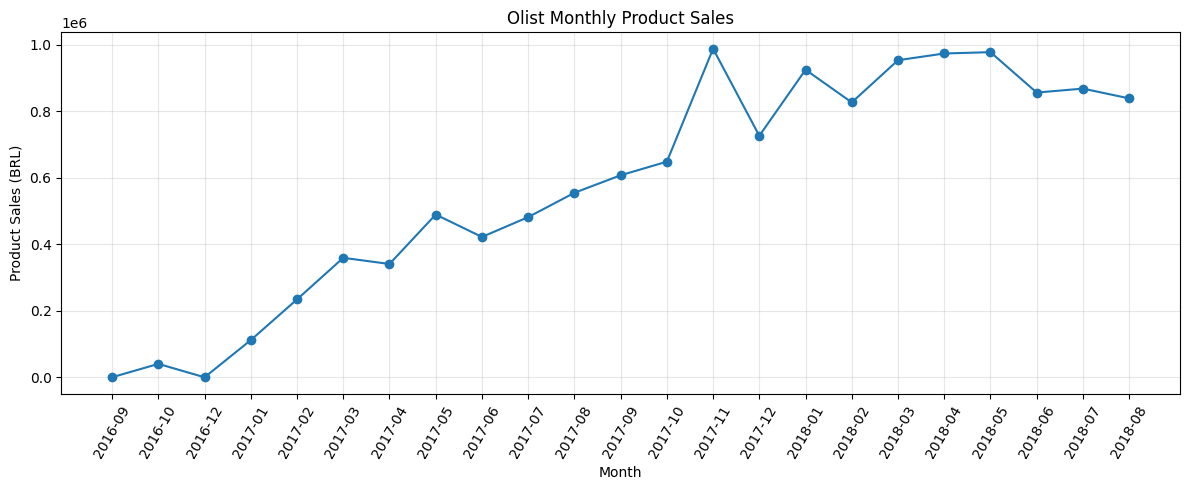

In [41]:
# Plot monthly product sales
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["month"],
    monthly_sales["product_sales"],
    marker="o"
)

plt.title("Olist Monthly Product Sales")
plt.xlabel("Month")
plt.ylabel("Product Sales (BRL)")
plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
# Calculate cancellations from all order records
query = """
SELECT
    COUNT(*) AS total_orders,
    SUM(
        CASE WHEN order_status = 'canceled'
        THEN 1 ELSE 0 END
    ) AS canceled_orders,
    ROUND(
        100.0 * SUM(
            CASE WHEN order_status = 'canceled'
            THEN 1 ELSE 0 END
        ) / NULLIF(COUNT(*), 0),
        2
    ) AS cancellation_rate_pct
FROM orders;
"""

cancellation_kpis = pd.read_sql_query(query, conn)

display(cancellation_kpis)

,total_orders,canceled_orders,cancellation_rate_pct
0,99441,625,0.63


In [43]:
# Compare customer freight charges with product sales
query = """
SELECT
    ROUND(SUM(oi.price), 2) AS product_sales,
    ROUND(SUM(oi.freight_value), 2) AS freight_charged,
    ROUND(
        100.0 * SUM(oi.freight_value)
        / NULLIF(SUM(oi.price), 0),
        2
    ) AS freight_to_sales_pct
FROM order_items oi
INNER JOIN orders o
    ON oi.order_id = o.order_id
WHERE o.order_status = 'delivered';
"""

freight_kpis = pd.read_sql_query(query, conn)

display(freight_kpis)

,product_sales,freight_charged,freight_to_sales_pct
0,13221498.11,2198275.64,16.63


In [44]:
# Combine the calculated KPIs
financial_summary = pd.DataFrame({
    "Metric": [
        "Delivered Orders",
        "Product Sales (BRL)",
        "Average Order Value (BRL)",
        "Customer Freight Charged (BRL)",
        "Cancellation Rate (%)",
        "Freight-to-Sales Ratio (%)"
    ],
    "Value": [
        kpis["total_orders"].iloc[0],
        kpis["total_product_sales"].iloc[0],
        kpis["avg_order_value"].iloc[0],
        kpis["total_freight_charged"].iloc[0],
        cancellation_kpis["cancellation_rate_pct"].iloc[0],
        freight_kpis["freight_to_sales_pct"].iloc[0]
    ]
})

display(financial_summary)

,Metric,Value
0,Delivered Orders,96478.00
1,Product Sales (BRL),13221498.11
2,Average Order Value (BRL),137.04
3,Customer Freight Charged (BRL),2198275.64
4,Cancellation Rate (%),0.63
5,Freight-to-Sales Ratio (%),16.63


In [45]:
# Create financial reports folder
report_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI/reports/financial"
)

report_path.mkdir(parents=True, exist_ok=True)

# Save results
financial_summary.to_csv(
    report_path / "financial_kpis.csv",
    index=False
)

monthly_sales.to_csv(
    report_path / "monthly_sales.csv",
    index=False
)

print("Financial reports saved successfully!")

Financial reports saved successfully!


### Product and Category Performance Analysis

In [46]:
# Create readable labels
query = """
SELECT
    oi.product_id,

    COALESCE(
        c.product_category_name_english,
        p.product_category_name,
        'Unknown'
    ) AS category,

    COUNT(*) AS items_sold,
    COUNT(DISTINCT oi.order_id) AS total_orders,
    ROUND(SUM(oi.price), 2) AS product_sales,
    ROUND(SUM(oi.freight_value), 2) AS freight_charged,
    ROUND(AVG(oi.price), 2) AS avg_selling_price

FROM order_items oi

JOIN orders o
    ON oi.order_id = o.order_id

LEFT JOIN products p
    ON oi.product_id = p.product_id

LEFT JOIN categories c
    ON p.product_category_name = c.product_category_name

WHERE o.order_status = 'delivered'

GROUP BY
    oi.product_id,
    c.product_category_name_english,
    p.product_category_name

ORDER BY product_sales DESC;
"""

product_performance = pd.read_sql_query(query, conn)

# Create readable labels
product_performance["product_label"] = (
    product_performance["category"]
    .str.replace("_", " ", regex=False)
    .str.title()
    + " | "
    + product_performance["product_id"].str[:6]
)

display(
    product_performance[
        ["product_label", "items_sold", "product_sales"]
    ].head(10)
)

,product_label,items_sold,product_sales
0,Health Beauty | bb50f2,194,63560.00
1,Health Beauty | 6cdd53,153,53652.30
2,Computers | d6160f,33,45949.35
3,Computers Accessories | d1c427,332,45620.56
4,Bed Bath Table | 99a478,477,42049.66
5,Computers Accessories | 3dd2a1,272,40782.80
6,Baby | 25c385,38,38907.32
7,Cool Stuff | 5f504b,63,37733.90
8,Watches Gifts | 53b36d,321,37454.63
9,Furniture Decor | aca2eb,520,37104.30


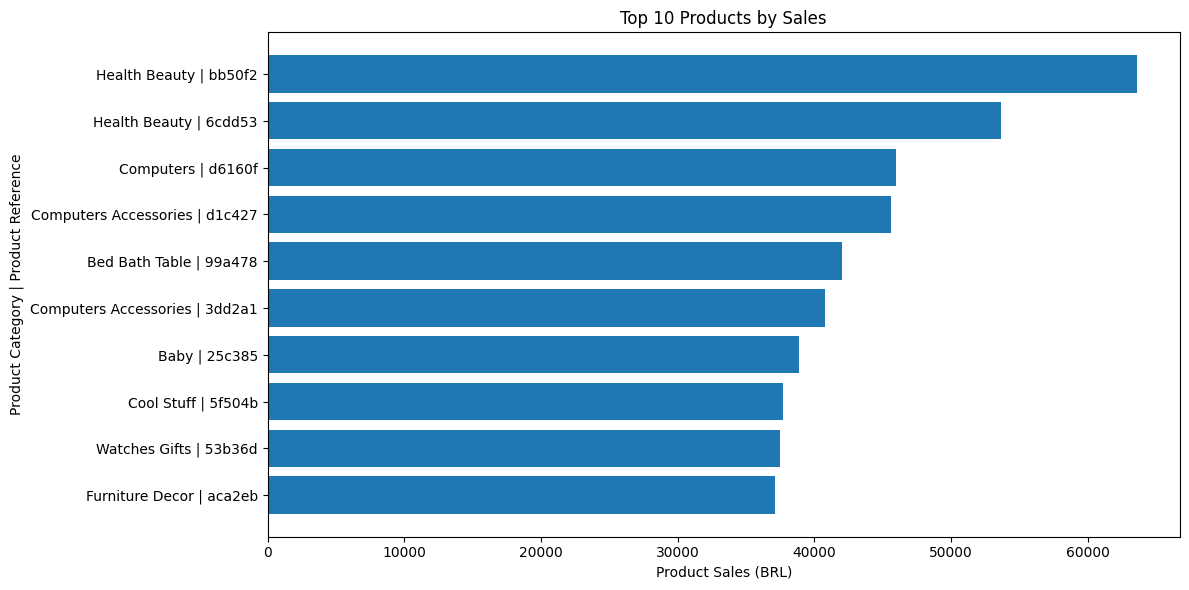

In [47]:
# Run this analysis step.
top_products = product_performance.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_products["product_label"],
    top_products["product_sales"]
)

plt.gca().invert_yaxis()

plt.title("Top 10 Products by Sales")
plt.xlabel("Product Sales (BRL)")
plt.ylabel("Product Category | Product Reference")

plt.tight_layout()
plt.show()

### Visualize Top Product Categories

In [48]:
# Join delivered items with products and category names
query = """
SELECT
    COALESCE(
        c.product_category_name_english,
        p.product_category_name,
        'Unknown'
    ) AS category,
    COUNT(*) AS items_sold,
    COUNT(DISTINCT oi.order_id) AS total_orders,
    ROUND(SUM(oi.price), 2) AS product_sales,
    ROUND(SUM(oi.freight_value), 2) AS freight_charged
FROM order_items oi
JOIN orders o
    ON oi.order_id = o.order_id
LEFT JOIN products p
    ON oi.product_id = p.product_id
LEFT JOIN categories c
    ON p.product_category_name = c.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY category
ORDER BY product_sales DESC;
"""

category_performance = pd.read_sql_query(query, conn)

display(category_performance.head(10))

,category,items_sold,total_orders,product_sales,freight_charged
0,health_beauty,9465,8647,1233131.72,178957.81
1,watches_gifts,5859,5495,1166176.98,98156.14
2,bed_bath_table,10953,9272,1023434.76,201774.50
3,sports_leisure,8431,7530,954852.55,163404.36
4,computers_accessories,7644,6530,888724.61,143999.16
5,furniture_decor,8160,6307,711927.69,168402.23
6,housewares,6795,5743,615628.69,142763.56
7,cool_stuff,3718,3559,610204.10,81476.79
8,auto,4140,3810,578966.65,90488.10
9,toys,4030,3804,471286.48,75774.58


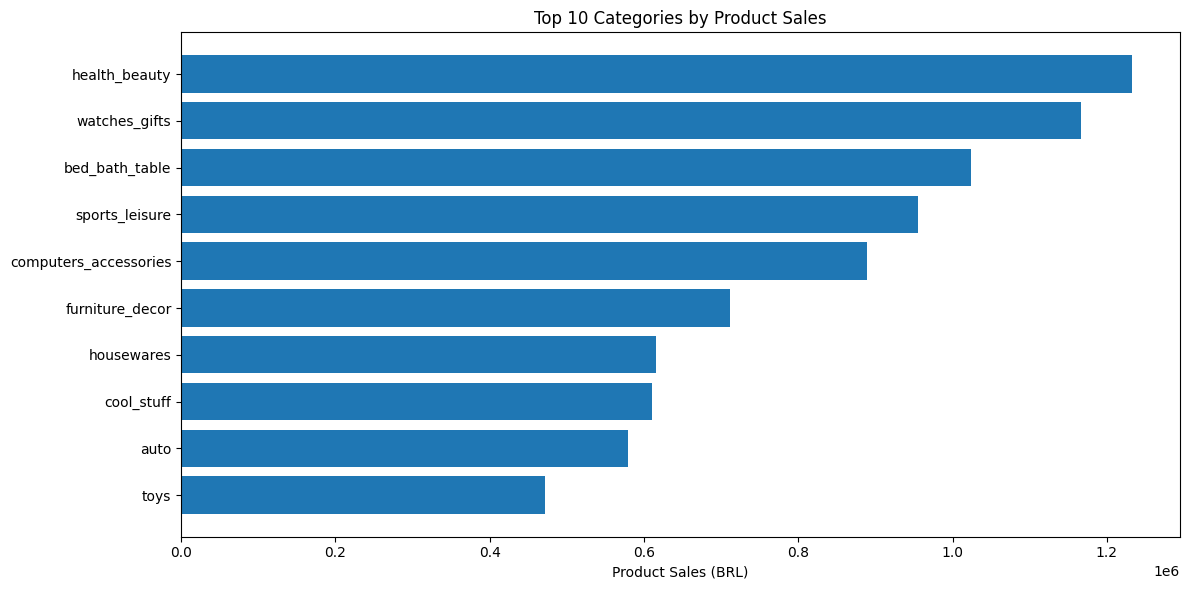

In [49]:
# Show top 10 categories
top_categories = category_performance.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_categories["category"],
    top_categories["product_sales"]
)

plt.gca().invert_yaxis()
plt.title("Top 10 Categories by Product Sales")
plt.xlabel("Product Sales (BRL)")
plt.tight_layout()
plt.show()

### Identify Low-Sales Products

In [50]:
# Step 60: Identify Low-Sales Products

# Find products with 1 or 2 recorded item sales
low_sales_products = product_performance[
    product_performance["items_sold"] <= 2
].sort_values("product_sales").copy()

# Create readable product labels
low_sales_products["product_label"] = (
    low_sales_products["category"]
    .fillna("Unknown")
    .str.replace("_", " ", regex=False)
    .str.title()
    + " | "
    + low_sales_products["product_id"].str[:6]
)

# Select useful columns
low_sales_report = low_sales_products[
    [
        "product_label",
        "items_sold",
        "total_orders",
        "product_sales",
        "freight_charged",
        "avg_selling_price"
    ]
].copy()

# Rename columns for readability
low_sales_report.columns = [
    "Product",
    "Items Sold",
    "Total Orders",
    "Product Sales (BRL)",
    "Freight Charged (BRL)",
    "Average Selling Price (BRL)"
]

print("Total low-sales products:", len(low_sales_report))

display(low_sales_report.head(20))

Total low-sales products: 23385


,Product,Items Sold,Total Orders,Product Sales (BRL),Freight Charged (BRL),Average Selling Price (BRL)
32215,Health Beauty | 46fce5,1,1,2.20,7.39,2.20
32214,Stationery | 310dc3,1,1,2.29,7.78,2.29
32212,Pet Shop | 680cc8,1,1,2.90,8.72,2.90
32211,Stationery | 2e8316,1,1,2.99,11.85,2.99
32210,Music | 0eeeb4,1,1,3.85,7.71,3.85
32209,Computers Accessories | eee2fb,1,1,3.90,11.85,3.90
32208,Unknown | dc9f66,1,1,3.90,10.96,3.90
32206,Fashion Underwear Beach | 836c4b,1,1,3.90,15.10,3.90
32207,Computers Accessories | c2fb26,1,1,3.90,15.10,3.90
32205,Construction Tools Construction | 66389c,1,1,3.99,12.79,3.99


### Analyze Freight Charges by Category

In [51]:
# Calculate freight charges relative to product sales
category_performance["freight_ratio_pct"] = (
    category_performance["freight_charged"]
    / category_performance["product_sales"]
    .replace(0, float("nan"))
    * 100
)

# Exclude very small categories from the initial ranking
freight_analysis = category_performance[
    (category_performance["total_orders"] >= 100) &
    (category_performance["product_sales"] > 0)
].sort_values(
    "freight_ratio_pct",
    ascending=False
)

display(
    freight_analysis[
        [
            "category",
            "total_orders",
            "product_sales",
            "freight_charged",
            "freight_ratio_pct"
        ]
    ].head(10)
)

,category,total_orders,product_sales,freight_charged,freight_ratio_pct
54,christmas_supplies,125,8737.84,3190.91,36.518293
47,signaling_and_security,138,21315.05,6477.54,30.389514
21,electronics,2517,155043.93,45679.16,29.462076
51,food_drink,221,14942.88,4394.89,29.411265
30,furniture_living_room,414,67350.70,17694.37,26.271991
36,kitchen_dining_laundry_garden_furniture,241,45531.98,11540.99,25.346998
46,drinks,287,21529.84,5441.27,25.273156
14,office_furniture,1254,268154.31,67057.05,25.006889
41,food,441,28731.15,7063.53,24.584919
5,furniture_decor,6307,711927.69,168402.23,23.654401


### Perform Pareto Analysis

In [52]:
# Rank products from highest to lowest sales
pareto = product_performance.sort_values(
    "product_sales",
    ascending=False
).copy()

# Calculate cumulative sales percentage
total_sales = pareto["product_sales"].sum()

pareto["cumulative_sales_pct"] = (
    pareto["product_sales"].cumsum()
    / total_sales * 100
)

# Calculate the share from the top 20% of products
top_20_count = max(1, int(np.ceil(len(pareto) * 0.20)))

top_20_share = (
    pareto["product_sales"].head(top_20_count).sum()
    / total_sales * 100
)

print(
    f"Top 20% of products generate "
    f"{top_20_share:.2f}% of product sales."
)

Top 20% of products generate 74.82% of product sales.


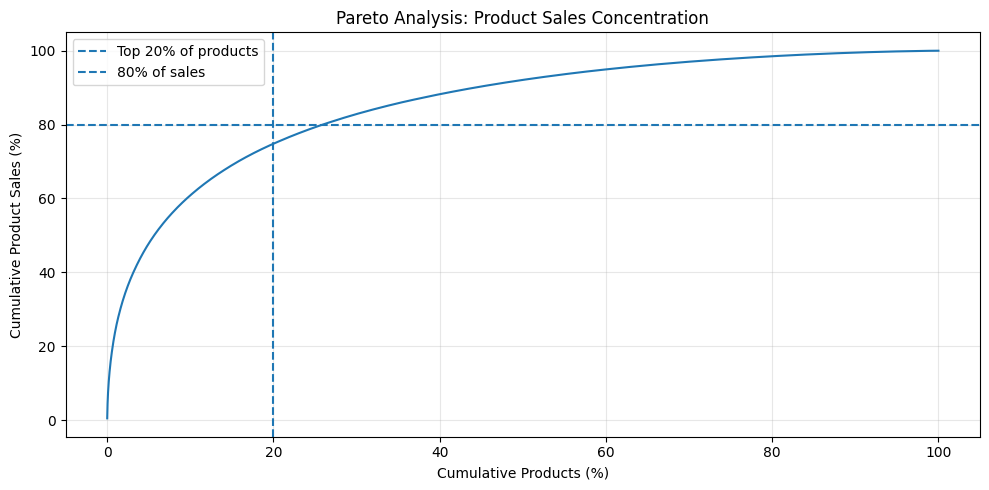

In [53]:
# Calculate cumulative share of products
pareto["cumulative_products_pct"] = (
    np.arange(1, len(pareto) + 1)
    / len(pareto) * 100
)

plt.figure(figsize=(10, 5))

plt.plot(
    pareto["cumulative_products_pct"],
    pareto["cumulative_sales_pct"]
)

plt.axvline(20, linestyle="--", label="Top 20% of products")
plt.axhline(80, linestyle="--", label="80% of sales")

plt.title("Pareto Analysis: Product Sales Concentration")
plt.xlabel("Cumulative Products (%)")
plt.ylabel("Cumulative Product Sales (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Validate Product and Category Sales Totals

In [54]:
# Confirm that both analyses use the same sales total
product_total = product_performance["product_sales"].sum()
category_total = category_performance["product_sales"].sum()
kpi_total = float(kpis["total_product_sales"].iloc[0])

print("Product-level total:", round(product_total, 2))
print("Category-level total:", round(category_total, 2))
print("Financial KPI total:", round(kpi_total, 2))

assert np.isclose(product_total, kpi_total, atol=1.0)
assert np.isclose(category_total, kpi_total, atol=1.0)

print("Sales totals validated successfully!")

Product-level total: 13221498.11
Category-level total: 13221498.11
Financial KPI total: 13221498.11
Sales totals validated successfully!


In [55]:
# Create the report folder
report_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI/reports/products"
)

report_path.mkdir(parents=True, exist_ok=True)

# Save product and category analysis
product_performance.to_csv(
    report_path / "product_performance.csv",
    index=False
)

category_performance.to_csv(
    report_path / "category_performance.csv",
    index=False
)

freight_analysis.to_csv(
    report_path / "category_freight_analysis.csv",
    index=False
)

pareto.to_csv(
    report_path / "product_pareto_analysis.csv",
    index=False
)

print("Product analysis reports saved successfully!")

Product analysis reports saved successfully!


## 06 | Machine learning: anomaly detection
Train an unsupervised model to flag unusual orders for investigation, not confirmed fraud.

### Build Our First Machine Learning Model for ProfitLens AI

### Prepare Order-Level Machine Learning Dataset

In [56]:
# Calculate freight-to-sales ratio
query = """
SELECT
    oi.order_id,
    COUNT(*) AS item_count,
    SUM(oi.price) AS order_value,
    SUM(oi.freight_value) AS freight_charged
FROM order_items oi
INNER JOIN orders o
    ON oi.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY oi.order_id;
"""

ml_data = pd.read_sql_query(query, conn)

# Calculate freight-to-sales ratio
ml_data["freight_ratio"] = (
    ml_data["freight_charged"]
    / ml_data["order_value"].replace(0, np.nan)
)

print("Total orders:", len(ml_data))
display(ml_data.head())

Total orders: 96478


,order_id,item_count,order_value,freight_charged,freight_ratio
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,0.225637
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,0.083076
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,0.089799
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,0.984604
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,0.090745


### Validate Machine Learning Features

In [57]:
# Run this analysis step.
features = [
    "order_value",
    "freight_charged",
    "item_count",
    "freight_ratio"
]

print("Missing values:")
print(ml_data[features].isna().sum())

print("\nDuplicate order IDs:")
print(ml_data["order_id"].duplicated().sum())

print("\nFeature statistics:")
display(ml_data[features].describe())

Missing values:
order_value        0
freight_charged    0
item_count         0
freight_ratio      0
dtype: int64

Duplicate order IDs:
0

Feature statistics:


,order_value,freight_charged,item_count,freight_ratio
count,96478.000000,96478.000000,96478.000000,96478.000000
mean,137.041586,22.785253,1.142198,0.308370
std,209.045198,21.559197,0.538804,0.311610
min,0.850000,0.000000,1.000000,0.000000
25%,45.900000,13.850000,1.000000,0.132016
50%,86.575000,17.170000,1.000000,0.224374
75%,149.900000,24.017500,1.000000,0.380531
max,13440.000000,1794.960000,21.000000,21.447059


In [58]:
# Keep original data unchanged
ml_clean = ml_data.copy()

# Remove invalid records from this modeling dataset only
ml_clean = ml_clean[
    (ml_clean["order_value"] > 0) &
    (ml_clean["freight_charged"] >= 0) &
    (ml_clean["item_count"] > 0)
]

# Remove missing or infinite feature values
ml_clean = ml_clean.replace(
    [np.inf, -np.inf], np.nan
)

ml_clean = ml_clean.dropna(subset=features)

print("Original orders:", len(ml_data))
print("Valid orders:", len(ml_clean))
print("Excluded orders:", len(ml_data) - len(ml_clean))

Original orders: 96478
Valid orders: 96478
Excluded orders: 0


### Prepare features for machine learning

### Transform and Scale Features

In [59]:
# Log-transform nonnegative features
X_log = np.log1p(ml_clean[features])

# Standardize features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

print("ML feature matrix shape:", X_scaled.shape)

ML feature matrix shape: (96478, 4)


### Train Isolation Forest Model

In [60]:
# Predict anomaly labels
model = IsolationForest(
    n_estimators=200,
    contamination=0.03,
    random_state=42,
    n_jobs=-1
)

model.fit(X_scaled)

# Predict anomaly labels
ml_clean["anomaly_label"] = model.predict(X_scaled)

# Calculate anomaly scores
ml_clean["anomaly_score"] = model.decision_function(X_scaled)

# Convert labels to readable values
ml_clean["anomaly_status"] = ml_clean["anomaly_label"].map({
    1: "Normal",
    -1: "Anomaly"
})

print(ml_clean["anomaly_status"].value_counts())

anomaly_status
Normal     93584
Anomaly     2894
Name: count, dtype: int64


### Investigate Flagged Orders

In [61]:
# Run this analysis step.
anomalies = ml_clean[
    ml_clean["anomaly_label"] == -1
].sort_values("anomaly_score")

print("Flagged orders:", len(anomalies))

display(
    anomalies[
        [
            "order_id",
            "order_value",
            "freight_charged",
            "item_count",
            "freight_ratio",
            "anomaly_score"
        ]
    ].head(20)
)

Flagged orders: 2894


,order_id,order_value,freight_charged,item_count,freight_ratio,anomaly_score
13658,2455cbeb73fd04b170ca2504662f95ce,419.40,1002.29,6,2.389819,-0.168861
78177,cf4659487be50c0c317cff3564c4a840,1050.00,1794.96,6,1.709486,-0.167792
49031,8272b63d03f5f79c56e9e4120aec44ef,31.80,164.37,21,5.168868,-0.167647
65947,af822dacd6f5cff7376413c03a388bb7,61.26,182.76,12,2.983350,-0.163917
23856,3f744e5030fb02e02651eb31d5204878,35.40,109.38,6,3.089831,-0.158828
74052,c471a28c25283860362c67c0a1cd1694,28.68,94.74,6,3.303347,-0.157773
22849,3caf6c286c8cde37ea9c0fb2da0e3169,47.40,132.36,6,2.792405,-0.156982
56117,95d6357ffe41aa6d2998852a710c70a0,17.50,91.15,5,5.208571,-0.153302
1432,03caa2c082116e1d31e67e9ae3700499,13440.00,224.08,8,0.016673,-0.152352
87931,e928cc82f61f2dcab3ad58d6e7200224,60.00,124.80,6,2.080000,-0.152254


In [62]:
## Compare normal and unusual orders
comparison = (
    ml_clean
    .groupby("anomaly_status")[features]
    .median()
    .round(2)
)

display(comparison)

,order_value,freight_charged,item_count,freight_ratio
anomaly_status,,,,
Anomaly,149.7,62.68,3.0,0.51
Normal,85.0,16.96,1.0,0.22


### Visualize anomaly detection results

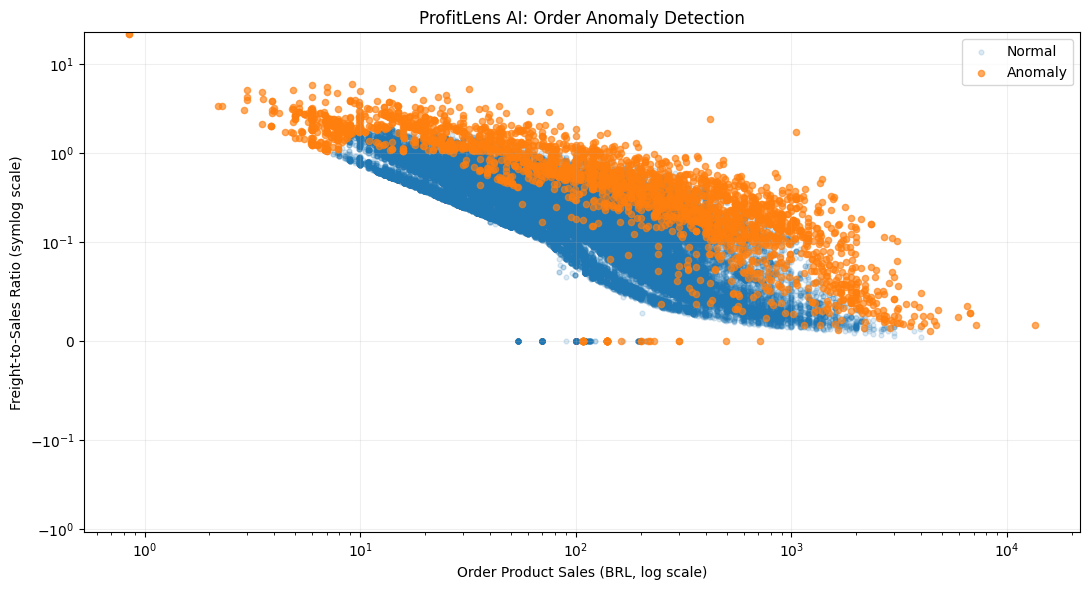

In [63]:
# Run this analysis step.
normal = ml_clean[
    ml_clean["anomaly_label"] == 1
]

anomalous = ml_clean[
    ml_clean["anomaly_label"] == -1
]

plt.figure(figsize=(11, 6))

plt.scatter(
    normal["order_value"],
    normal["freight_ratio"],
    alpha=0.15,
    s=12,
    label="Normal"
)

plt.scatter(
    anomalous["order_value"],
    anomalous["freight_ratio"],
    alpha=0.65,
    s=20,
    label="Anomaly"
)

plt.xscale("log")
plt.yscale("symlog", linthresh=0.1)

plt.title("ProfitLens AI: Order Anomaly Detection")
plt.xlabel("Order Product Sales (BRL, log scale)")
plt.ylabel("Freight-to-Sales Ratio (symlog scale)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Evaluate Anomaly Detection Results

In [64]:
# Run this analysis step.
total_orders = len(ml_clean)
flagged_orders = (ml_clean["anomaly_label"] == -1).sum()

flagged_pct = 100 * flagged_orders / total_orders

print("Total analyzed orders:", total_orders)
print("Flagged orders:", flagged_orders)
print(f"Flagged percentage: {flagged_pct:.2f}%")

print("\nAnomaly score statistics:")
display(ml_clean["anomaly_score"].describe())

print("\nMost unusual orders:")
display(
    ml_clean.nsmallest(10, "anomaly_score")[
        [
            "order_id",
            "order_value",
            "freight_charged",
            "item_count",
            "freight_ratio",
            "anomaly_score"
        ]
    ]
)

Total analyzed orders: 96478
Flagged orders: 2894
Flagged percentage: 3.00%

Anomaly score statistics:


,anomaly_score
count,96478.000000
mean,0.188892
std,0.074856
min,-0.168861
25%,0.156930
50%,0.215357
75%,0.245659
max,0.263641



Most unusual orders:


,order_id,order_value,freight_charged,item_count,freight_ratio,anomaly_score
13658,2455cbeb73fd04b170ca2504662f95ce,419.40,1002.29,6,2.389819,-0.168861
78177,cf4659487be50c0c317cff3564c4a840,1050.00,1794.96,6,1.709486,-0.167792
49031,8272b63d03f5f79c56e9e4120aec44ef,31.80,164.37,21,5.168868,-0.167647
65947,af822dacd6f5cff7376413c03a388bb7,61.26,182.76,12,2.983350,-0.163917
23856,3f744e5030fb02e02651eb31d5204878,35.40,109.38,6,3.089831,-0.158828
74052,c471a28c25283860362c67c0a1cd1694,28.68,94.74,6,3.303347,-0.157773
22849,3caf6c286c8cde37ea9c0fb2da0e3169,47.40,132.36,6,2.792405,-0.156982
56117,95d6357ffe41aa6d2998852a710c70a0,17.50,91.15,5,5.208571,-0.153302
1432,03caa2c082116e1d31e67e9ae3700499,13440.00,224.08,8,0.016673,-0.152352
87931,e928cc82f61f2dcab3ad58d6e7200224,60.00,124.80,6,2.080000,-0.152254


In [65]:
# Create folders
model_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI/models"
)

report_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI/reports/anomalies"
)

model_path.mkdir(parents=True, exist_ok=True)
report_path.mkdir(parents=True, exist_ok=True)

# Save model and preprocessing scaler
joblib.dump(
    {
        "model": model,
        "scaler": scaler,
        "features": features,
        "log_transform": "log1p",
        "contamination": 0.03
    },
    model_path / "isolation_forest_pipeline.joblib"
)

# Save all scored orders
ml_clean.to_csv(
    report_path / "all_order_anomaly_scores.csv",
    index=False
)

# Save flagged orders
anomalies.to_csv(
    report_path / "flagged_orders.csv",
    index=False
)

print("Model and anomaly reports saved successfully!")

Model and anomaly reports saved successfully!


### Calculate Normal Order Benchmarks

In [66]:
# Select orders not flagged by the model
normal_orders = ml_clean[
    ml_clean["anomaly_label"] == 1
].copy()

features = [
    "order_value",
    "freight_charged",
    "item_count",
    "freight_ratio"
]

# Calculate comparison statistics
benchmarks = normal_orders[features].agg(
    ["median", "mean", "std"]
).T

# Calculate percentile thresholds
benchmarks["p95"] = normal_orders[features].quantile(0.95)
benchmarks["p99"] = normal_orders[features].quantile(0.99)

display(benchmarks.round(3))

,median,mean,std,p95,p99
order_value,85.000,128.639,166.342,369.99,849.000
freight_charged,16.960,20.987,13.897,48.00,78.158
item_count,1.000,1.090,0.313,2.00,2.000
freight_ratio,0.223,0.291,0.240,0.77,1.215


### Build Business Investigation Rules

In [67]:
# 1. Unusually high order value
def explain_anomaly(order, benchmarks):
    """
    Describe observed unusual features of an order.

    These are benchmark comparisons, not explanations
    of the Isolation Forest's internal decisions.
    """

    explanations = []

    # 1. Unusually high order value
    if order["order_value"] > benchmarks.loc["order_value", "p95"]:
        explanations.append(
            "Product sales are higher than the 95th percentile "
            "of unflagged orders."
        )

    # 2. Unusually high freight charge
    if order["freight_charged"] > benchmarks.loc["freight_charged", "p95"]:
        explanations.append(
            "Customer freight charges are unusually high "
            "compared with unflagged orders."
        )

    # 3. High freight-to-sales ratio
    if order["freight_ratio"] > benchmarks.loc["freight_ratio", "p95"]:
        explanations.append(
            "The customer freight-to-sales ratio is higher "
            "than the 95th percentile of unflagged orders."
        )

    # 4. Unusually high item count
    if order["item_count"] > benchmarks.loc["item_count", "p95"]:
        explanations.append(
            "The order contains more item records "
            "than most unflagged orders."
        )

    # 5. Unusually low order value
    if order["order_value"] < normal_orders["order_value"].quantile(0.05):
        explanations.append(
            "Product sales are below the 5th percentile "
            "of unflagged orders."
        )

    # If none of our simple rules explains the unusual pattern
    if not explanations:
        explanations.append(
            "The model flagged an unusual combination of features, "
            "but none exceeded the individual investigation thresholds."
        )

    return explanations

### Generate Anomaly Investigation Explanations

In [68]:
# Work on a copy of flagged orders
investigation_report = anomalies.copy()

# Generate explanations
investigation_report["explanations"] = (
    investigation_report.apply(
        lambda row: explain_anomaly(row, benchmarks),
        axis=1
    )
)

# Create a readable explanation column
investigation_report["investigation_summary"] = (
    investigation_report["explanations"].apply(
        lambda items: " ".join(items)
    )
)

display(
    investigation_report[
        [
            "order_id",
            "order_value",
            "freight_charged",
            "freight_ratio",
            "anomaly_score",
            "investigation_summary"
        ]
    ].head(10)
)

,order_id,order_value,freight_charged,freight_ratio,anomaly_score,investigation_summary
13658,2455cbeb73fd04b170ca2504662f95ce,419.40,1002.29,2.389819,-0.168861,Product sales are higher than the 95th percent...
78177,cf4659487be50c0c317cff3564c4a840,1050.00,1794.96,1.709486,-0.167792,Product sales are higher than the 95th percent...
49031,8272b63d03f5f79c56e9e4120aec44ef,31.80,164.37,5.168868,-0.167647,Customer freight charges are unusually high co...
65947,af822dacd6f5cff7376413c03a388bb7,61.26,182.76,2.983350,-0.163917,Customer freight charges are unusually high co...
23856,3f744e5030fb02e02651eb31d5204878,35.40,109.38,3.089831,-0.158828,Customer freight charges are unusually high co...
74052,c471a28c25283860362c67c0a1cd1694,28.68,94.74,3.303347,-0.157773,Customer freight charges are unusually high co...
22849,3caf6c286c8cde37ea9c0fb2da0e3169,47.40,132.36,2.792405,-0.156982,Customer freight charges are unusually high co...
56117,95d6357ffe41aa6d2998852a710c70a0,17.50,91.15,5.208571,-0.153302,Customer freight charges are unusually high co...
1432,03caa2c082116e1d31e67e9ae3700499,13440.00,224.08,0.016673,-0.152352,Product sales are higher than the 95th percent...
87931,e928cc82f61f2dcab3ad58d6e7200224,60.00,124.80,2.080000,-0.152254,Customer freight charges are unusually high co...


### Generate Investigation Recommendations

In [69]:
# Run this analysis step.
def recommend_investigation(order, benchmarks):

    recommendations = []

    if order["freight_ratio"] > benchmarks.loc["freight_ratio", "p95"]:
        recommendations.append(
            "Review product category, shipping destination, "
            "and customer freight charges."
        )

    if order["order_value"] > benchmarks.loc["order_value", "p95"]:
        recommendations.append(
            "Review product prices, item count, "
            "and order composition."
        )

    if order["item_count"] > benchmarks.loc["item_count", "p95"]:
        recommendations.append(
            "Check whether the order contains multiple "
            "products or repeated item records."
        )

    if not recommendations:
        recommendations.append(
            "Review the order details and compare its "
            "combined features with typical orders."
        )

    return " ".join(recommendations)


investigation_report["recommended_action"] = (
    investigation_report.apply(
        lambda row: recommend_investigation(row, benchmarks),
        axis=1
    )
)

display(
    investigation_report[
        [
            "order_id",
            "investigation_summary",
            "recommended_action"
        ]
    ].head(10)
)

,order_id,investigation_summary,recommended_action
13658,2455cbeb73fd04b170ca2504662f95ce,Product sales are higher than the 95th percent...,"Review product category, shipping destination,..."
78177,cf4659487be50c0c317cff3564c4a840,Product sales are higher than the 95th percent...,"Review product category, shipping destination,..."
49031,8272b63d03f5f79c56e9e4120aec44ef,Customer freight charges are unusually high co...,"Review product category, shipping destination,..."
65947,af822dacd6f5cff7376413c03a388bb7,Customer freight charges are unusually high co...,"Review product category, shipping destination,..."
23856,3f744e5030fb02e02651eb31d5204878,Customer freight charges are unusually high co...,"Review product category, shipping destination,..."
74052,c471a28c25283860362c67c0a1cd1694,Customer freight charges are unusually high co...,"Review product category, shipping destination,..."
22849,3caf6c286c8cde37ea9c0fb2da0e3169,Customer freight charges are unusually high co...,"Review product category, shipping destination,..."
56117,95d6357ffe41aa6d2998852a710c70a0,Customer freight charges are unusually high co...,"Review product category, shipping destination,..."
1432,03caa2c082116e1d31e67e9ae3700499,Product sales are higher than the 95th percent...,"Review product prices, item count, and order c..."
87931,e928cc82f61f2dcab3ad58d6e7200224,Customer freight charges are unusually high co...,"Review product category, shipping destination,..."


### Assign Investigation Priority

In [70]:
# Rank flagged orders by anomaly score
# Lower score = more unusual according to the model
investigation_report = investigation_report.sort_values(
    "anomaly_score",
    ascending=True
).copy()

# Calculate relative rank among flagged orders
investigation_report["anomaly_rank_pct"] = (
    investigation_report["anomaly_score"]
    .rank(method="first", pct=True, ascending=True)
)

# Assign investigation priority
investigation_report["priority"] = np.select(
    [
        investigation_report["anomaly_rank_pct"] <= 0.10,
        investigation_report["anomaly_rank_pct"] <= 0.40
    ],
    [
        "High",
        "Medium"
    ],
    default="Low"
)

print(investigation_report["priority"].value_counts())

display(
    investigation_report[
        [
            "order_id",
            "anomaly_score",
            "priority",
            "investigation_summary"
        ]
    ].head(15)
)

priority
Low       1737
Medium     868
High       289
Name: count, dtype: int64


,order_id,anomaly_score,priority,investigation_summary
13658,2455cbeb73fd04b170ca2504662f95ce,-0.168861,High,Product sales are higher than the 95th percent...
78177,cf4659487be50c0c317cff3564c4a840,-0.167792,High,Product sales are higher than the 95th percent...
49031,8272b63d03f5f79c56e9e4120aec44ef,-0.167647,High,Customer freight charges are unusually high co...
65947,af822dacd6f5cff7376413c03a388bb7,-0.163917,High,Customer freight charges are unusually high co...
23856,3f744e5030fb02e02651eb31d5204878,-0.158828,High,Customer freight charges are unusually high co...
74052,c471a28c25283860362c67c0a1cd1694,-0.157773,High,Customer freight charges are unusually high co...
22849,3caf6c286c8cde37ea9c0fb2da0e3169,-0.156982,High,Customer freight charges are unusually high co...
56117,95d6357ffe41aa6d2998852a710c70a0,-0.153302,High,Customer freight charges are unusually high co...
1432,03caa2c082116e1d31e67e9ae3700499,-0.152352,High,Product sales are higher than the 95th percent...
87931,e928cc82f61f2dcab3ad58d6e7200224,-0.152254,High,Customer freight charges are unusually high co...


### Interactive Order Investigation

In [71]:
# Create a copy and assign readable display IDs
investigation_ui = investigation_report.reset_index(drop=True).copy()

investigation_ui["display_id"] = [
    f"ORD-{i:04d}"
    for i in range(1, len(investigation_ui) + 1)
]

# Create dropdown with short IDs
order_dropdown = widgets.Dropdown(
    options=[
        (
            f"{row['display_id']} | {row['priority']} Priority",
            row["order_id"]
        )
        for _, row in investigation_ui.iterrows()
    ],
    description="Select Order:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

output = widgets.Output()

def show_order_details(change):
    with output:
        clear_output(wait=True)

        selected = investigation_ui[
            investigation_ui["order_id"] == change["new"]
        ].iloc[0]

        # Format explanations as a readable list
        explanations = "".join(
            f"<li>{item}</li>"
            for item in selected["explanations"]
        )

        # Create a clean HTML report
        html = f"""
        <div style="
            font-family: Arial, sans-serif;
            padding: 22px;
            background: #ffffff;
            color: #222222;
            border: 1px solid #dddddd;
            border-radius: 12px;
            max-width: 750px;
        ">

            <h2 style="margin-top: 0;">
                ProfitLens AI | Order Investigation
            </h2>

            <h3>{selected['display_id']}</h3>

            <p>
                <b>Original Order ID:</b>
                <code>{selected['order_id']}</code>
            </p>

            <p>
                <b>Investigation Priority:</b>
                {selected['priority']}
            </p>

            <hr>

            <h3>Order Financial Details</h3>

            <table style="width: 100%; border-collapse: collapse;">
                <tr>
                    <td style="padding: 9px;">Product Sales</td>
                    <td>R$ {selected['order_value']:,.2f}</td>
                </tr>
                <tr>
                    <td style="padding: 9px;">Customer Freight</td>
                    <td>R$ {selected['freight_charged']:,.2f}</td>
                </tr>
                <tr>
                    <td style="padding: 9px;">Freight Ratio</td>
                    <td>{selected['freight_ratio']:.2%}</td>
                </tr>
                <tr>
                    <td style="padding: 9px;">Item Count</td>
                    <td>{int(selected['item_count'])}</td>
                </tr>
                <tr>
                    <td style="padding: 9px;">Anomaly Score</td>
                    <td>{selected['anomaly_score']:.4f}</td>
                </tr>
            </table>

            <hr>

            <h3>Observed Unusual Features</h3>
            <ul>
                {explanations}
            </ul>

            <h3>Suggested Investigation</h3>
            <p>{selected['recommended_action']}</p>

            <p style="font-size: 12px; color: #666;">
                Note: This is a statistical anomaly,
                not a confirmed financial loss or fraud.
            </p>

        </div>
        """

        display(HTML(html))

order_dropdown.observe(show_order_details, names="value")

display(order_dropdown, output)

if len(investigation_ui) > 0:
    show_order_details({"new": order_dropdown.value})

Dropdown(description='Select Order:', layout=Layout(width='450px'), options=(('ORD-0001 | High Priority', '245…

Output()

In [72]:
# Save report as CSV
report_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI/reports/anomalies"
)

report_path.mkdir(parents=True, exist_ok=True)

# Save report as CSV
investigation_report.to_csv(
    report_path / "anomaly_investigation_report.csv",
    index=False
)

# Save benchmarks
benchmarks.to_csv(
    report_path / "normal_order_benchmarks.csv"
)

# Save structured report as JSON
investigation_report.to_json(
    report_path / "anomaly_investigation_report.json",
    orient="records",
    indent=2
)

print("Investigation reports saved successfully!")

Investigation reports saved successfully!


## 07 | Forecasting and model evaluation
Use chronological evaluation and compare models against the naive baseline. Results are provisional with a short test period.

### Build the Sales Forecasting Engine for ProfitLens AI

### Prepare Monthly Sales Data

In [73]:
# Load monthly sales report from Step 48
file_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI/reports/financial/monthly_sales.csv"
)

monthly_df = pd.read_csv(file_path)

# Convert month to date
monthly_df["month"] = pd.to_datetime(
    monthly_df["month"],
    format="%Y-%m"
)

# Sort by date
monthly_df = monthly_df.sort_values("month").reset_index(drop=True)

display(monthly_df)

,month,total_orders,product_sales,sales_growth_pct
0,2016-09-01,1,134.97,NaN
1,2016-10-01,265,40325.11,2.977709e+04
2,2016-12-01,1,10.90,-9.997297e+01
3,2017-01-01,750,111798.36,1.025573e+06
4,2017-02-01,1653,234223.40,1.095052e+02
5,2017-03-01,2546,359198.85,5.335737e+01
6,2017-04-01,2303,340669.68,-5.158471e+00
7,2017-05-01,3546,489338.25,4.364009e+01
8,2017-06-01,3135,421923.37,-1.377674e+01
9,2017-07-01,3872,481604.52,1.414502e+01


In [74]:
# Run this analysis step.
print("First month:", monthly_df["month"].min())
print("Last month:", monthly_df["month"].max())
print("Total months:", len(monthly_df))

print("\nMissing values:")
print(monthly_df.isna().sum())

First month: 2016-09-01 00:00:00
Last month: 2018-08-01 00:00:00
Total months: 23

Missing values:
month               0
total_orders        0
product_sales       0
sales_growth_pct    1
dtype: int64


In [75]:
# Start from January 2017
sales_ts = monthly_df[
    monthly_df["month"] >= "2017-01-01"
].copy()

# Keep the required columns
sales_ts = sales_ts[
    ["month", "product_sales"]
].copy()

# Rename product_sales to sales
sales_ts = sales_ts.rename(
    columns={"product_sales": "sales"}
)

# Set month as the index
sales_ts = sales_ts.set_index("month").asfreq("MS")

# Check missing values
print("Missing monthly observations:")
print(sales_ts["sales"].isna().sum())

print("\nTotal months:", len(sales_ts))

print("\nFirst month:", sales_ts.index.min())
print("Last month:", sales_ts.index.max())

display(sales_ts)

Missing monthly observations:
0

Total months: 20

First month: 2017-01-01 00:00:00
Last month: 2018-08-01 00:00:00


,sales
month,
2017-01-01,111798.36
2017-02-01,234223.40
2017-03-01,359198.85
2017-04-01,340669.68
2017-05-01,489338.25
2017-06-01,421923.37
2017-07-01,481604.52
2017-08-01,554699.70
2017-09-01,607399.67


### Create Time-Series Features

In [76]:
# Previous month sales
forecast_df = sales_ts.copy()

# Previous month sales
forecast_df["lag_1"] = forecast_df["sales"].shift(1)

# Two months earlier
forecast_df["lag_2"] = forecast_df["sales"].shift(2)

# Three months earlier
forecast_df["lag_3"] = forecast_df["sales"].shift(3)

# Average of previous three months
forecast_df["rolling_mean_3"] = (
    forecast_df["sales"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

# Remove rows without sufficient history
forecast_df = forecast_df.dropna().reset_index()

display(forecast_df.head())

,month,sales,lag_1,lag_2,lag_3,rolling_mean_3
0,2017-04-01,340669.68,359198.85,234223.40,111798.36,235073.536667
1,2017-05-01,489338.25,340669.68,359198.85,234223.40,311363.976667
2,2017-06-01,421923.37,489338.25,340669.68,359198.85,396402.260000
3,2017-07-01,481604.52,421923.37,489338.25,340669.68,417310.433333
4,2017-08-01,554699.70,481604.52,421923.37,489338.25,464288.713333


### Create Chronological Train-Test Split

In [77]:
# Reserve the last four eligible months for testing
feature_cols = [
    "lag_1",
    "lag_2",
    "lag_3",
    "rolling_mean_3"
]

# Reserve the last four eligible months for testing
test_size = 4

if len(forecast_df) < 10:
    raise ValueError(
        "Not enough monthly observations for this experiment. "
        "Use a longer time series such as Walmart M5."
    )

train_df = forecast_df.iloc[:-test_size].copy()
test_df = forecast_df.iloc[-test_size:].copy()

X_train = train_df[feature_cols]
y_train = train_df["sales"]

X_test = test_df[feature_cols]
y_test = test_df["sales"]

print("Training months:", len(train_df))
print("Testing months:", len(test_df))

Training months: 13
Testing months: 4


### Train Random Forest Sales Forecasting Model

In [78]:
# Run this analysis step.
forecast_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

forecast_model.fit(X_train, y_train)

print("Forecasting model trained successfully!")

Forecasting model trained successfully!


In [79]:
# Predict test-month sales
test_df["predicted_sales"] = forecast_model.predict(X_test)

# Avoid negative sales estimates
test_df["predicted_sales"] = test_df[
    "predicted_sales"
].clip(lower=0)

display(
    test_df[
        ["month", "sales", "predicted_sales"]
    ]
)

,month,sales,predicted_sales
13,2018-05-01,977544.69,877285.604738
14,2018-06-01,856077.86,877285.604738
15,2018-07-01,867953.46,921220.930310
16,2018-08-01,838576.64,922674.029570


In [80]:
# Evaluate Sales Forecasting Model
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

actual = test_df["sales"]
predicted = test_df["predicted_sales"]

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

wape = (
    np.abs(actual - predicted).sum()
    / actual.abs().sum()
    * 100
    if actual.abs().sum() > 0
    else np.nan
)

print(f"MAE: R$ {mae:,.2f}")
print(f"RMSE: R$ {rmse:,.2f}")
print(f"WAPE: {wape:.2f}%")

MAE: R$ 64,707.92
RMSE: R$ 71,434.32
WAPE: 7.31%


In [81]:
# Simple baseline: next month = previous month
baseline_predictions = test_df["lag_1"]

baseline_mae = mean_absolute_error(
    actual,
    baseline_predictions
)

print(f"Random Forest MAE: R$ {mae:,.2f}")
print(f"Baseline MAE: R$ {baseline_mae:,.2f}")

if mae < baseline_mae:
    print("Random Forest performed better on this test period.")
else:
    print("The simple baseline performed as well or better.")

Random Forest MAE: R$ 64,707.92
Baseline MAE: R$ 41,682.46
The simple baseline performed as well or better.


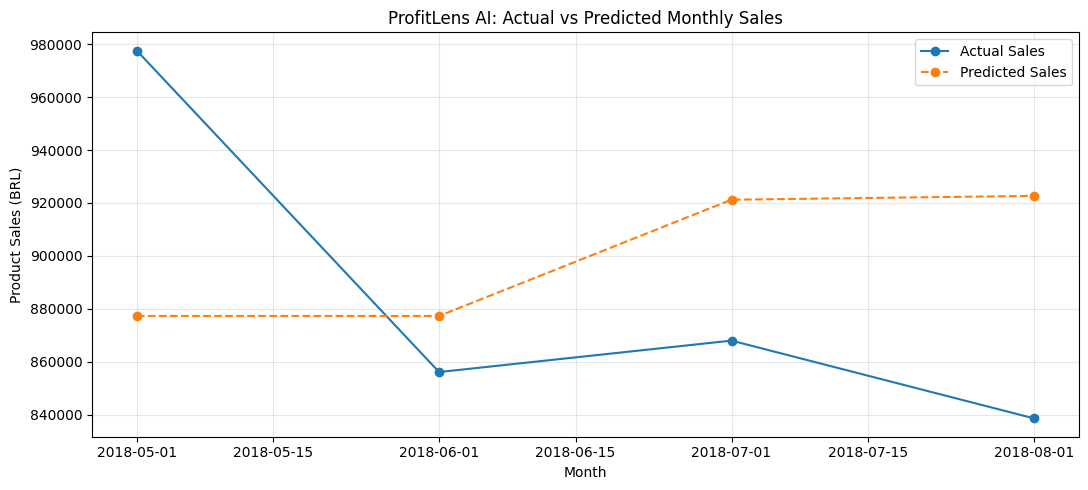

In [82]:
# Run this analysis step.
plt.figure(figsize=(11, 5))

plt.plot(
    test_df["month"],
    test_df["sales"],
    marker="o",
    label="Actual Sales"
)

plt.plot(
    test_df["month"],
    test_df["predicted_sales"],
    marker="o",
    linestyle="--",
    label="Predicted Sales"
)

plt.title("ProfitLens AI: Actual vs Predicted Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Product Sales (BRL)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Forecast the Next Month

In [83]:
# Train using all eligible historical months
final_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

final_model.fit(
    forecast_df[feature_cols],
    forecast_df["sales"]
)

# Get the latest three months of actual sales
last_three = sales_ts["sales"].tail(3).to_numpy()

if len(last_three) != 3 or np.isnan(last_three).any():
    raise ValueError("Three complete recent months are required.")

# Create next-month features
next_month_features = pd.DataFrame([{
    "lag_1": last_three[-1],
    "lag_2": last_three[-2],
    "lag_3": last_three[-3],
    "rolling_mean_3": last_three.mean()
}])

# Predict next month
next_month_prediction = max(
    0,
    float(final_model.predict(next_month_features)[0])
)

next_month_date = (
    sales_ts.index.max() + pd.DateOffset(months=1)
)

print("Forecast month:", next_month_date.strftime("%Y-%m"))
print(f"Predicted product sales: R$ {next_month_prediction:,.2f}")

Forecast month: 2018-09
Predicted product sales: R$ 941,881.62


In [84]:
# Use the monthly sales data from Step 82
warnings.filterwarnings("ignore", category=UserWarning)

# Use the monthly sales data from Step 82
sales = sales_ts["sales"].copy().sort_index()

# Check data
assert sales.notna().all(), "Missing sales values found."
assert len(sales) >= 12, "Not enough monthly observations."
assert (sales >= 0).all(), "Negative sales values found."

print("Total months:", len(sales))
print("First month:", sales.index.min())
print("Last month:", sales.index.max())

display(sales.tail())

Total months: 20
First month: 2017-01-01 00:00:00
Last month: 2018-08-01 00:00:00


,sales
month,
2018-04-01,973534.09
2018-05-01,977544.69
2018-06-01,856077.86
2018-07-01,867953.46
2018-08-01,838576.64


In [85]:
# Fit a trend using historical month positions
def create_features(history):
    """Create lag features from historical monthly sales."""

    df = pd.DataFrame({"sales": history.values})

    df["lag_1"] = df["sales"].shift(1)
    df["lag_2"] = df["sales"].shift(2)
    df["lag_3"] = df["sales"].shift(3)

    df["rolling_mean_3"] = (
        df["sales"].shift(1).rolling(3).mean()
    )

    return df.dropna()


def forecast_one_month(history, model_name):

    values = np.asarray(history, dtype=float)

    if model_name == "Naive":
        prediction = values[-1]

    elif model_name == "Moving Average":
        prediction = values[-3:].mean()

    elif model_name == "Linear Regression":
        # Fit a trend using historical month positions
        X = np.arange(len(values)).reshape(-1, 1)
        y = values

        model = LinearRegression()
        model.fit(X, y)

        prediction = model.predict(
            np.array([[len(values)]])
        )[0]

    elif model_name == "Random Forest":
        df = create_features(values)

        X = df.drop(columns="sales")
        y = df["sales"]

        model = RandomForestRegressor(
            n_estimators=200,
            max_depth=5,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X, y)

        next_features = pd.DataFrame([{
            "lag_1": values[-1],
            "lag_2": values[-2],
            "lag_3": values[-3],
            "rolling_mean_3": values[-3:].mean()
        }])

        prediction = model.predict(next_features)[0]

    elif model_name == "ARIMA":
        model = ARIMA(
            values,
            order=(1, 1, 0)
        )

        fitted = model.fit()
        prediction = fitted.forecast(steps=1)[0]

    else:
        raise ValueError("Unknown model")

    # Sales predictions cannot be negative
    return max(0, float(prediction))

In [86]:
# Ensure we work with a flat 1D array
warnings.filterwarnings('ignore')

def create_features(history_array):
    """Create lag features from historical monthly sales represented as a NumPy array."""
    # Ensure we work with a flat 1D array
    sales_vals = np.asarray(history_array).flatten()
    df = pd.DataFrame({"sales": sales_vals})

    df["lag_1"] = df["sales"].shift(1)
    df["lag_2"] = df["sales"].shift(2)
    df["lag_3"] = df["sales"].shift(3)
    df["rolling_mean_3"] = df["sales"].shift(1).rolling(3).mean()

    return df.dropna()

def forecast_one_month(history, model_name):
    values = np.asarray(history, dtype=float)

    if model_name == "Naive":
        prediction = values[-1]

    elif model_name == "Moving Average":
        prediction = values[-3:].mean()

    elif model_name == "Linear Regression":
        X = np.arange(len(values)).reshape(-1, 1)
        y = values
        model = LinearRegression()
        model.fit(X, y)
        prediction = model.predict(np.array([[len(values)]]))[0]

    elif model_name == "Random Forest":
        df = create_features(values)
        X = df.drop(columns="sales")
        y = df["sales"]

        model = RandomForestRegressor(
            n_estimators=200,
            max_depth=5,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
        model.fit(X, y)

        next_features = pd.DataFrame([{
            "lag_1": values[-1],
            "lag_2": values[-2],
            "lag_3": values[-3],
            "rolling_mean_3": values[-3:].mean()
        }])
        prediction = model.predict(next_features)[0]

    elif model_name == "ARIMA":
        model = ARIMA(values, order=(1, 1, 0))
        fitted = model.fit()
        prediction = fitted.forecast(steps=1)[0]

    else:
        raise ValueError("Unknown model")

    return max(0, float(prediction))

# Run backtest loop
models = [
    "Naive",
    "Moving Average",
    "Linear Regression",
    "Random Forest",
    "ARIMA"
]

test_months = 4
results = []

for i in range(len(sales) - test_months, len(sales)):
    history = sales.iloc[:i]
    actual = float(sales.iloc[i])
    month = sales.index[i]

    for model_name in models:
        try:
            prediction = forecast_one_month(history, model_name)
            results.append({
                "month": month,
                "model": model_name,
                "actual_sales": actual,
                "predicted_sales": prediction,
                "absolute_error": abs(actual - prediction)
            })
        except Exception as e:
            print(f"Error: {model_name}, {month}: {e}")
            raise

results_df = pd.DataFrame(results)
display(results_df.head(10))

,month,model,actual_sales,predicted_sales,absolute_error
0,2018-05-01,Naive,977544.69,9.735341e+05,4010.600000
1,2018-05-01,Moving Average,977544.69,9.177758e+05,59768.866667
2,2018-05-01,Linear Regression,977544.69,1.073915e+06,96370.788750
3,2018-05-01,Random Forest,977544.69,8.772856e+05,100259.085262
4,2018-05-01,ARIMA,977544.69,9.652699e+05,12274.775009
5,2018-06-01,Naive,856077.86,9.775447e+05,121466.830000
6,2018-06-01,Moving Average,856077.86,9.681450e+05,112067.150000
7,2018-06-01,Linear Regression,856077.86,1.106694e+06,250616.353603
8,2018-06-01,Random Forest,856077.86,9.143787e+05,58300.887219
9,2018-06-01,ARIMA,856077.86,9.759051e+05,119827.204532


In [87]:
# Run this analysis step.
comparison = []

for model_name in models:

    df = results_df[
        results_df["model"] == model_name
    ]

    actual = df["actual_sales"]
    predicted = df["predicted_sales"]

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        np.mean((actual - predicted) ** 2)
    )

    wape = (
        np.abs(actual - predicted).sum()
        / actual.abs().sum()
        * 100
    )

    comparison.append({
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "WAPE (%)": round(wape, 2)
    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    "MAE"
).reset_index(drop=True)

display(comparison_df)

,Model,MAE,RMSE,WAPE (%)
0,Naive,41682.46,62797.90,4.71
1,ARIMA,48680.60,64339.49,5.50
2,Random Forest,69822.32,72359.98,7.89
3,Moving Average,75387.53,78360.00,8.52
4,Linear Regression,212236.05,222760.56,23.98


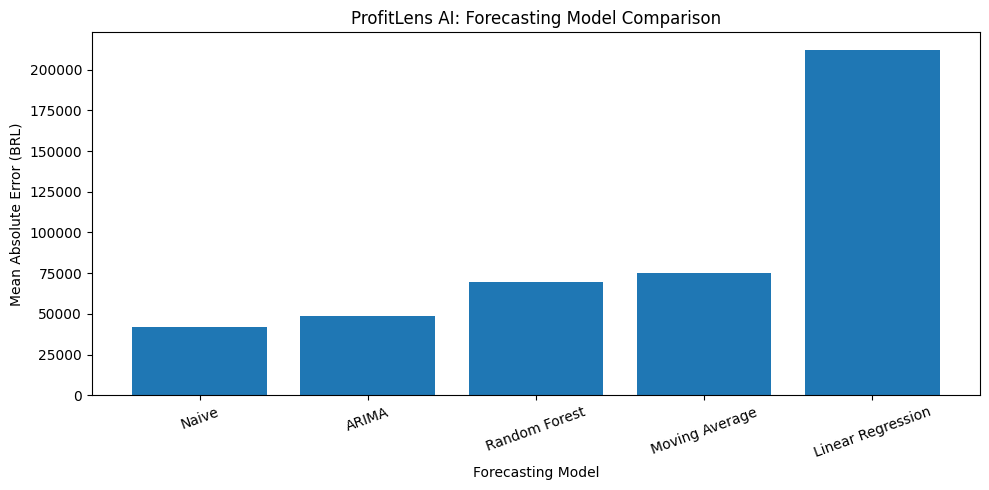

In [88]:
# Run this analysis step.
plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["MAE"]
)

plt.title("ProfitLens AI: Forecasting Model Comparison")
plt.xlabel("Forecasting Model")
plt.ylabel("Mean Absolute Error (BRL)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [89]:
# Run this analysis step.
best_model = comparison_df.iloc[0]["Model"]
best_mae = comparison_df.iloc[0]["MAE"]

print("Best-performing model:", best_model)
print(f"MAE: R$ {best_mae:,.2f}")

Best-performing model: Naive
MAE: R$ 41,682.46


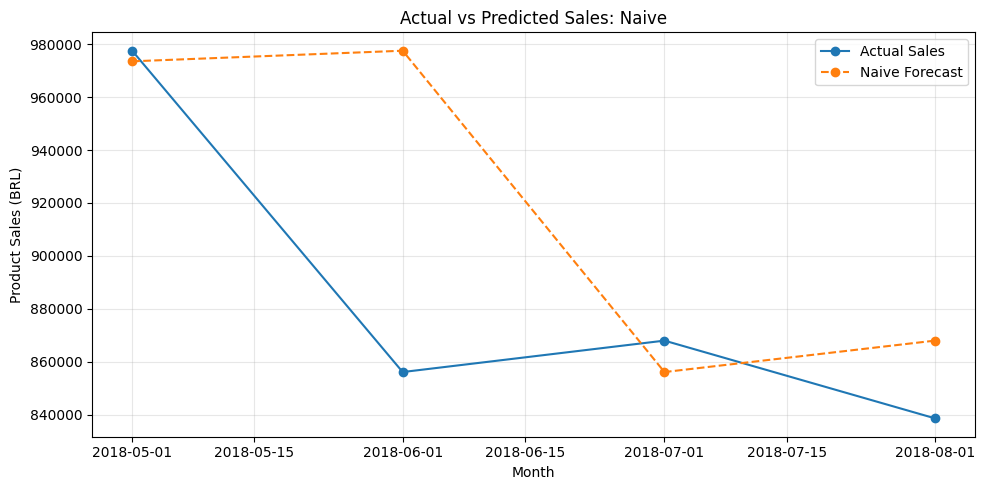

In [90]:
# Run this analysis step.
best_results = results_df[
    results_df["model"] == best_model
].copy()

plt.figure(figsize=(10, 5))

plt.plot(
    best_results["month"],
    best_results["actual_sales"],
    marker="o",
    label="Actual Sales"
)

plt.plot(
    best_results["month"],
    best_results["predicted_sales"],
    marker="o",
    linestyle="--",
    label=f"{best_model} Forecast"
)

plt.title(f"Actual vs Predicted Sales: {best_model}")
plt.xlabel("Month")
plt.ylabel("Product Sales (BRL)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 08 | Financial What-If Simulator
Scenario costs are assumptions. Modeled contribution is not actual net profit.

### Build the Financial What-If Simulator for ProfitLens AI

### Prepare Financial Simulation Data

In [91]:
# Load product performance from Step 55
file_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI/reports/products/product_performance.csv"
)

products_df = pd.read_csv(file_path)

# Use products with at least 20 sold item records
eligible_products = products_df[
    (products_df["items_sold"] >= 20) &
    (products_df["avg_selling_price"] > 0)
].copy()

print("Eligible products:", len(eligible_products))

display(
    eligible_products[
        [
            "product_id",
            "items_sold",
            "product_sales",
            "avg_selling_price"
        ]
    ].head(10)
)

Eligible products: 690


,product_id,items_sold,product_sales,avg_selling_price
0,bb50f2e236e5eea0100680137654686c,194,63560.00,327.63
1,6cdd53843498f92890544667809f1595,153,53652.30,350.67
2,d6160fb7873f184099d9bc95e30376af,33,45949.35,1392.40
3,d1c427060a0f73f6b889a5c7c61f2ac4,332,45620.56,137.41
4,99a4788cb24856965c36a24e339b6058,477,42049.66,88.15
5,3dd2a17168ec895c781a9191c1e95ad7,272,40782.80,149.94
6,25c38557cf793876c5abdd5931f922db,38,38907.32,1023.88
7,5f504b3a1c75b73d6151be81eb05bdc9,63,37733.90,598.95
8,53b36df67ebb7c41585e8d54d6772e08,321,37454.63,116.68
9,aca2eb7d00ea1a7b8ebd4e68314663af,520,37104.30,71.35


### Build the Financial What-If Simulator

In [92]:
# Baseline
def simulate_financial_scenario(
    price,
    quantity,
    unit_cost,
    price_change_pct=0,
    demand_change_pct=0,
    cost_change_pct=0
):
    """
    Compare a baseline with a hypothetical business scenario.

    unit_cost and percentage changes are assumptions.
    """

    if price <= 0 or quantity < 0 or unit_cost < 0:
        raise ValueError("Invalid baseline inputs.")

    if min(
        1 + price_change_pct / 100,
        1 + demand_change_pct / 100,
        1 + cost_change_pct / 100
    ) < 0:
        raise ValueError("Changes cannot reduce values below zero.")

    # Baseline
    baseline_sales = price * quantity
    baseline_cost = unit_cost * quantity
    baseline_contribution = baseline_sales - baseline_cost

    # Scenario assumptions
    new_price = price * (1 + price_change_pct / 100)
    new_quantity = quantity * (1 + demand_change_pct / 100)
    new_unit_cost = unit_cost * (1 + cost_change_pct / 100)

    # Scenario calculations
    scenario_sales = new_price * new_quantity
    scenario_cost = new_unit_cost * new_quantity
    scenario_contribution = scenario_sales - scenario_cost

    baseline_margin = (
        baseline_contribution / baseline_sales * 100
        if baseline_sales > 0 else np.nan
    )

    scenario_margin = (
        scenario_contribution / scenario_sales * 100
        if scenario_sales > 0 else np.nan
    )

    return pd.DataFrame({
        "Metric": [
            "Unit Price",
            "Quantity",
            "Unit Variable Cost",
            "Product Sales",
            "Total Variable Cost",
            "Contribution",
            "Contribution Margin (%)"
        ],
        "Baseline": [
            price,
            quantity,
            unit_cost,
            baseline_sales,
            baseline_cost,
            baseline_contribution,
            baseline_margin
        ],
        "Scenario": [
            new_price,
            new_quantity,
            new_unit_cost,
            scenario_sales,
            scenario_cost,
            scenario_contribution,
            scenario_margin
        ]
    })

In [93]:
# Select the highest-sales eligible product
selected_product = eligible_products.iloc[0]

product_id = selected_product["product_id"]

# Use actual total product sales and item count
quantity = float(selected_product["items_sold"])

# Derive the historical average price
price = float(
    selected_product["product_sales"] / quantity
)

# Hypothetical unit variable cost
unit_cost = price * 0.60

scenario_result = simulate_financial_scenario(
    price=price,
    quantity=quantity,
    unit_cost=unit_cost,
    price_change_pct=10,
    demand_change_pct=-5,
    cost_change_pct=3
)

print("Product ID:", product_id)
print("Historical average price:", round(price, 2))
print("Assumed unit variable cost:", round(unit_cost, 2))

display(scenario_result.round(2))

Product ID: bb50f2e236e5eea0100680137654686c
Historical average price: 327.63
Assumed unit variable cost: 196.58


,Metric,Baseline,Scenario
0,Unit Price,327.63,360.39
1,Quantity,194.00,184.30
2,Unit Variable Cost,196.58,202.47
3,Product Sales,63560.00,66420.20
4,Total Variable Cost,38136.00,37316.08
5,Contribution,25424.00,29104.12
6,Contribution Margin (%),40.00,43.82


### Calculate Scenario Financial Impact

In [94]:
# Run this analysis step.
result = scenario_result.set_index("Metric")

baseline_contribution = result.loc[
    "Contribution", "Baseline"
]

scenario_contribution = result.loc[
    "Contribution", "Scenario"
]

contribution_change = (
    scenario_contribution - baseline_contribution
)

contribution_change_pct = (
    contribution_change / abs(baseline_contribution) * 100
    if baseline_contribution != 0 else np.nan
)

print(
    f"Baseline contribution: R$ {baseline_contribution:,.2f}"
)

print(
    f"Scenario contribution: R$ {scenario_contribution:,.2f}"
)

print(
    f"Contribution change: R$ {contribution_change:,.2f}"
)

print(
    f"Relative contribution change: {contribution_change_pct:.2f}%"
)

Baseline contribution: R$ 25,424.00
Scenario contribution: R$ 29,104.12
Contribution change: R$ 3,680.12
Relative contribution change: 14.48%


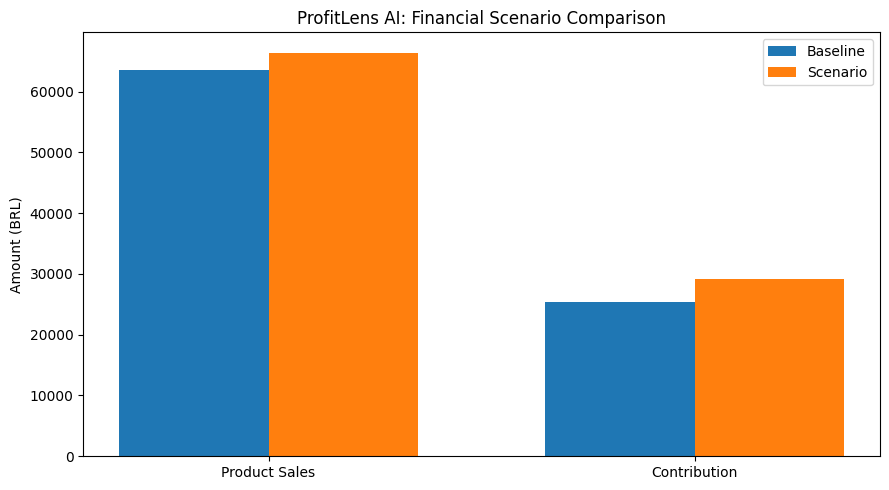

In [95]:
# visualize Financial Scenario Results
metrics = [
    "Product Sales",
    "Contribution"
]

baseline_values = result.loc[
    metrics, "Baseline"
].values

scenario_values = result.loc[
    metrics, "Scenario"
].values

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    baseline_values,
    width,
    label="Baseline"
)

plt.bar(
    x + width / 2,
    scenario_values,
    width,
    label="Scenario"
)

plt.xticks(x, metrics)
plt.ylabel("Amount (BRL)")
plt.title("ProfitLens AI: Financial Scenario Comparison")
plt.legend()
plt.tight_layout()
plt.show()

### Build an interactive What-If Simulator

In [96]:
# Get product category information
product_info = olist["products"][
    ["product_id", "product_category_name"]
].copy()

category_info = olist["categories"][
    ["product_category_name", "product_category_name_english"]
].copy()

# Join product information with English category names
product_info = product_info.merge(
    category_info,
    on="product_category_name",
    how="left"
)

# Add category names to eligible products
eligible_products = eligible_products.drop(
    columns=["category", "product_category_name_english"],
    errors="ignore"
)

eligible_products = eligible_products.merge(
    product_info[
        ["product_id", "product_category_name_english"]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

eligible_products["category"] = (
    eligible_products["product_category_name_english"]
    .fillna("Unknown Category")
    .str.replace("_", " ")
    .str.title()
)

# Create readable labels
eligible_products["product_label"] = (
    eligible_products["category"]
    + " | "
    + eligible_products["product_id"].str[:8]
)

display(
    eligible_products[
        ["product_label", "items_sold", "product_sales"]
    ].head(10)
)

,product_label,items_sold,product_sales
0,Health Beauty | bb50f2e2,194,63560.00
1,Health Beauty | 6cdd5384,153,53652.30
2,Computers | d6160fb7,33,45949.35
3,Computers Accessories | d1c42706,332,45620.56
4,Bed Bath Table | 99a4788c,477,42049.66
5,Computers Accessories | 3dd2a171,272,40782.80
6,Baby | 25c38557,38,38907.32
7,Cool Stuff | 5f504b3a,63,37733.90
8,Watches Gifts | 53b36df6,321,37454.63
9,Furniture Decor | aca2eb7d,520,37104.30


In [97]:
# Show top 100 products by sales
product_options = eligible_products.sort_values(
    "product_sales",
    ascending=False
).head(100)

# Readable product dropdown
product_dropdown = widgets.Dropdown(
    options=[
        (row.product_label, row.product_id)
        for row in product_options.itertuples()
    ],
    description="Product:",
    style={"description_width": "120px"},
    layout=widgets.Layout(width="750px")
)

cost_slider = widgets.IntSlider(
    value=60, min=10, max=100, step=5,
    description="Unit Cost (%):",
    style={"description_width": "120px"}
)

price_slider = widgets.IntSlider(
    value=0, min=-30, max=30,
    description="Price Change:",
    style={"description_width": "120px"}
)

demand_slider = widgets.IntSlider(
    value=0, min=-50, max=50,
    description="Demand Change:",
    style={"description_width": "120px"}
)

supplier_slider = widgets.IntSlider(
    value=0, min=-30, max=50,
    description="Cost Change:",
    style={"description_width": "120px"}
)

output = widgets.Output()


def update_simulation(change=None):

    with output:
        clear_output(wait=True)

        product = eligible_products[
            eligible_products["product_id"] == product_dropdown.value
        ].iloc[0]

        quantity = float(product["items_sold"])
        price = float(product["product_sales"] / quantity)
        assumed_cost = price * cost_slider.value / 100

        simulation = simulate_financial_scenario(
            price=price,
            quantity=quantity,
            unit_cost=assumed_cost,
            price_change_pct=price_slider.value,
            demand_change_pct=demand_slider.value,
            cost_change_pct=supplier_slider.value
        )

        print("PROFITLENS AI - FINANCIAL SIMULATOR")
        print("=" * 55)
        print("Category:", product["category"])
        print("Product ID:", product["product_id"][:8])
        print("Historical Items Sold:", int(quantity))
        print("Assumed Unit Cost:", cost_slider.value, "% of price")
        print("=" * 55)

        display(
            simulation.style.format({
                "Baseline": "{:,.2f}",
                "Scenario": "{:,.2f}"
            })
        )


for control in [
    product_dropdown,
    cost_slider,
    price_slider,
    demand_slider,
    supplier_slider
]:
    control.observe(update_simulation, names="value")

display(
    product_dropdown,
    cost_slider,
    price_slider,
    demand_slider,
    supplier_slider,
    output
)

update_simulation()

Dropdown(description='Product:', layout=Layout(width='750px'), options=(('Health Beauty | bb50f2e2', 'bb50f2e2…

IntSlider(value=60, description='Unit Cost (%):', min=10, step=5, style=SliderStyle(description_width='120px')…

IntSlider(value=0, description='Price Change:', max=30, min=-30, style=SliderStyle(description_width='120px'))

IntSlider(value=0, description='Demand Change:', max=50, min=-50, style=SliderStyle(description_width='120px')…

IntSlider(value=0, description='Cost Change:', max=50, min=-30, style=SliderStyle(description_width='120px'))

Output()

In [98]:
# Run this analysis step.
report_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI/reports/simulations"
)

report_path.mkdir(parents=True, exist_ok=True)

scenario_result.to_csv(
    report_path / "sample_financial_scenario.csv",
    index=False
)

print("Financial simulation report saved successfully!")

Financial simulation report saved successfully!


### Build the Business Decision Recommendation Engine

### Define Business Decision Scenarios

In [99]:
# Five hypothetical business scenarios
scenarios = [
    {
        "Scenario": "No Change",
        "price_change": 0,
        "demand_change": 0,
        "cost_change": 0
    },
    {
        "Scenario": "Small Price Increase",
        "price_change": 5,
        "demand_change": -2,
        "cost_change": 0
    },
    {
        "Scenario": "Large Price Increase",
        "price_change": 10,
        "demand_change": -8,
        "cost_change": 0
    },
    {
        "Scenario": "Discount Strategy",
        "price_change": -5,
        "demand_change": 10,
        "cost_change": 0
    },
    {
        "Scenario": "Supplier Cost Increase",
        "price_change": 0,
        "demand_change": 0,
        "cost_change": 10
    }
]

scenarios_df = pd.DataFrame(scenarios)

display(scenarios_df)

,Scenario,price_change,demand_change,cost_change
0,No Change,0,0,0
1,Small Price Increase,5,-2,0
2,Large Price Increase,10,-8,0
3,Discount Strategy,-5,10,0
4,Supplier Cost Increase,0,0,10


### Calculate Financial Outcomes for All Scenarios

In [100]:
# Select a product from our actual Olist data
selected_product = eligible_products.iloc[0]

product_id = selected_product["product_id"]

quantity = float(selected_product["items_sold"])

price = float(
    selected_product["product_sales"] / quantity
)

# Hypothetical cost: 60% of average selling price
unit_cost = price * 0.60

scenario_results = []

for scenario in scenarios:

    result = simulate_financial_scenario(
        price=price,
        quantity=quantity,
        unit_cost=unit_cost,
        price_change_pct=scenario["price_change"],
        demand_change_pct=scenario["demand_change"],
        cost_change_pct=scenario["cost_change"]
    )

    result = result.set_index("Metric")

    scenario_results.append({
        "Scenario": scenario["Scenario"],
        "Price Change (%)": scenario["price_change"],
        "Demand Change (%)": scenario["demand_change"],
        "Cost Change (%)": scenario["cost_change"],
        "Product Sales": result.loc[
            "Product Sales", "Scenario"
        ],
        "Variable Cost": result.loc[
            "Total Variable Cost", "Scenario"
        ],
        "Contribution": result.loc[
            "Contribution", "Scenario"
        ],
        "Contribution Margin (%)": result.loc[
            "Contribution Margin (%)", "Scenario"
        ]
    })

decision_df = pd.DataFrame(scenario_results)

display(decision_df.round(2))

,Scenario,Price Change (%),Demand Change (%),Cost Change (%),Product Sales,Variable Cost,Contribution,Contribution Margin (%)
0,No Change,0,0,0,63560.00,38136.00,25424.00,40.00
1,Small Price Increase,5,-2,0,65403.24,37373.28,28029.96,42.86
2,Large Price Increase,10,-8,0,64322.72,35085.12,29237.60,45.45
3,Discount Strategy,-5,10,0,66420.20,41949.60,24470.60,36.84
4,Supplier Cost Increase,0,0,10,63560.00,41949.60,21610.40,34.00


### Rank Financial Scenarios

In [101]:
# Get baseline contribution
baseline_contribution = decision_df.loc[
    decision_df["Scenario"] == "No Change",
    "Contribution"
].iloc[0]

# Calculate contribution change
decision_df["Contribution Change"] = (
    decision_df["Contribution"] - baseline_contribution
)

# Rank by contribution
decision_df = decision_df.sort_values(
    "Contribution",
    ascending=False
).reset_index(drop=True)

decision_df["Rank"] = np.arange(1, len(decision_df) + 1)

display(
    decision_df[
        [
            "Rank",
            "Scenario",
            "Product Sales",
            "Contribution",
            "Contribution Change",
            "Contribution Margin (%)"
        ]
    ].round(2)
)

,Rank,Scenario,Product Sales,Contribution,Contribution Change,Contribution Margin (%)
0,1,Large Price Increase,64322.72,29237.60,3813.60,45.45
1,2,Small Price Increase,65403.24,28029.96,2605.96,42.86
2,3,No Change,63560.00,25424.00,0.00,40.00
3,4,Discount Strategy,66420.20,24470.60,-953.40,36.84
4,5,Supplier Cost Increase,63560.00,21610.40,-3813.60,34.00


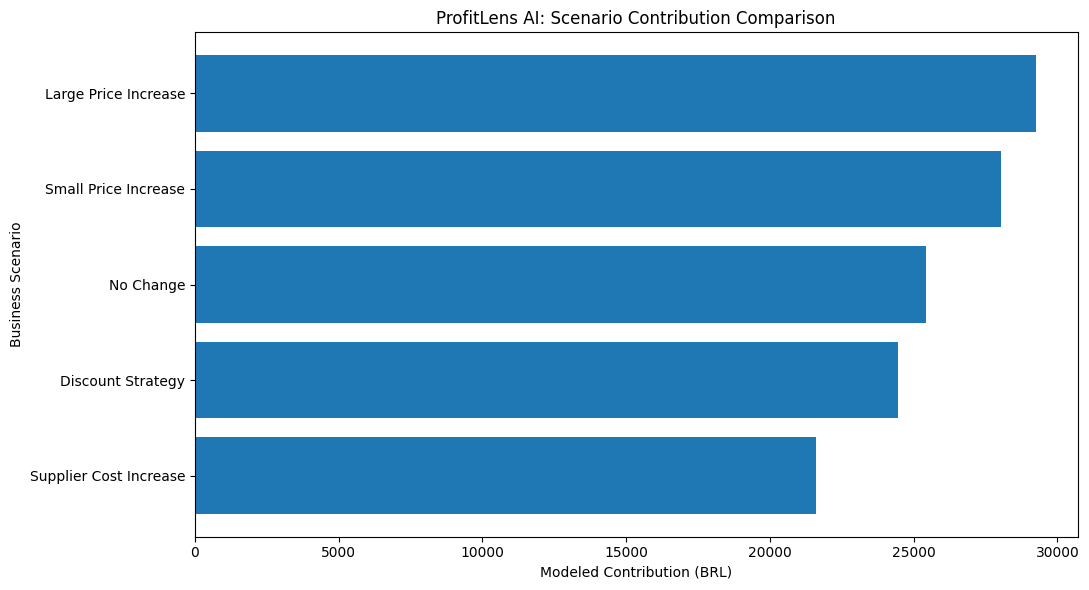

In [102]:
# Visualize Business Scenario Rankings
plt.figure(figsize=(11, 6))

plt.barh(
    decision_df["Scenario"],
    decision_df["Contribution"]
)

plt.gca().invert_yaxis()

plt.title("ProfitLens AI: Scenario Contribution Comparison")
plt.xlabel("Modeled Contribution (BRL)")
plt.ylabel("Business Scenario")

plt.tight_layout()
plt.show()

### Generate Business Decision Summary

In [103]:
# Select highest-contribution scenario
best_scenario = decision_df.iloc[0]

best_name = best_scenario["Scenario"]
best_contribution = best_scenario["Contribution"]
best_change = best_scenario["Contribution Change"]

print("PROFITLENS AI — BUSINESS DECISION SUMMARY")
print("-" * 50)

print("Product:", product_id)

print("\nHighest modeled contribution scenario:")
print(best_name)

print(
    f"\nModeled contribution: R$ {best_contribution:,.2f}"
)

print(
    f"Change from baseline: R$ {best_change:,.2f}"
)

print("\nScenario assumptions:")
print(
    f"Price change: {best_scenario['Price Change (%)']}%"
)
print(
    f"Demand change: {best_scenario['Demand Change (%)']}%"
)
print(
    f"Unit cost change: {best_scenario['Cost Change (%)']}%"
)

print("\nInterpretation:")
print(
    "This scenario produces the highest modeled contribution "
    "among the alternatives tested, given the specified assumptions."
)

print("\nImportant limitation:")
print(
    "Demand changes and product costs are assumptions. "
    "This is not a verified profit forecast."
)

PROFITLENS AI — BUSINESS DECISION SUMMARY
--------------------------------------------------
Product: bb50f2e236e5eea0100680137654686c

Highest modeled contribution scenario:
Large Price Increase

Modeled contribution: R$ 29,237.60
Change from baseline: R$ 3,813.60

Scenario assumptions:
Price change: 10%
Demand change: -8%
Unit cost change: 0%

Interpretation:
This scenario produces the highest modeled contribution among the alternatives tested, given the specified assumptions.

Important limitation:
Demand changes and product costs are assumptions. This is not a verified profit forecast.


In [104]:
# Run this analysis step.
report_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI/reports/decisions"
)

report_path.mkdir(parents=True, exist_ok=True)

decision_df.to_csv(
    report_path / "scenario_comparison.csv",
    index=False
)

print("Business decision report saved successfully!")

Business decision report saved successfully!


## 09 | Approved business analytics tools
Connect to the saved SQLite database and load existing anomaly and scenario reports.

In [105]:
# Copy SQLite from Drive to Colab storage to avoid Drive I/O errors.
local_db_path = Path("/content/ProfitLens_AI/database/profitlens_olist.db")
local_db_path.parent.mkdir(parents=True, exist_ok=True)
if not DB_DRIVE_PATH.exists():
    raise FileNotFoundError(f"Missing saved database: {DB_DRIVE_PATH}")
shutil.copy2(DB_DRIVE_PATH, local_db_path)
conn_ai = sqlite3.connect(local_db_path.resolve().as_uri() + "?mode=ro", uri=True)
print("Read-only analytics database ready.")

Read-only analytics database ready.


In [106]:
# Run this analysis step.
def get_sales_summary():
    query = """
    SELECT
        COUNT(DISTINCT oi.order_id) AS total_orders,
        ROUND(SUM(oi.price), 2) AS product_sales,
        ROUND(SUM(oi.freight_value), 2) AS freight_charged
    FROM order_items oi
    JOIN orders o ON oi.order_id = o.order_id
    WHERE o.order_status = 'delivered';
    """

    return pd.read_sql_query(query, conn_ai)


def get_top_categories(limit=10):
    limit = max(1, min(int(limit), 20))

    query = """
    SELECT
        COALESCE(
            c.product_category_name_english,
            p.product_category_name,
            'Unknown'
        ) AS category,
        ROUND(SUM(oi.price), 2) AS product_sales
    FROM order_items oi
    JOIN orders o ON oi.order_id = o.order_id
    LEFT JOIN products p ON oi.product_id = p.product_id
    LEFT JOIN categories c
        ON p.product_category_name = c.product_category_name
    WHERE o.order_status = 'delivered'
    GROUP BY category
    ORDER BY product_sales DESC
    LIMIT ?;
    """

    return pd.read_sql_query(
        query, conn_ai, params=(limit,)
    )


def get_cancellation_summary():
    query = """
    SELECT
        COUNT(*) AS total_orders,
        SUM(
            CASE WHEN order_status = 'canceled'
            THEN 1 ELSE 0 END
        ) AS canceled_orders,
        ROUND(
            100.0 * SUM(
                CASE WHEN order_status = 'canceled'
                THEN 1 ELSE 0 END
            ) / NULLIF(COUNT(*), 0),
            2
        ) AS cancellation_rate_pct
    FROM orders;
    """

    return pd.read_sql_query(query, conn_ai)


print("Approved SQL analytics tools are ready!")

Approved SQL analytics tools are ready!


In [107]:
# Run this analysis step.
anomaly_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI/"
    "reports/anomalies/anomaly_investigation_report.csv"
)

if anomaly_path.exists():
    anomaly_report = pd.read_csv(anomaly_path)
    print("Anomaly investigation report loaded!")
else:
    anomaly_report = pd.DataFrame()
    print("Anomaly report not found.")


def get_top_anomalies(limit=5):
    if anomaly_report.empty:
        return pd.DataFrame()

    limit = max(1, min(int(limit), 20))

    return (
        anomaly_report
        .sort_values("anomaly_score")
        .head(limit)
        [
            [
                "order_id",
                "order_value",
                "freight_charged",
                "anomaly_score",
                "priority",
                "investigation_summary"
            ]
        ]
    )

Anomaly investigation report loaded!


In [108]:
# Run this analysis step.
scenario_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI/"
    "reports/decisions/scenario_comparison.csv"
)

if scenario_path.exists():
    scenario_report = pd.read_csv(scenario_path)
    print("Scenario comparison report loaded!")
else:
    scenario_report = pd.DataFrame()
    print("Scenario report not found.")


def get_best_scenario():
    if scenario_report.empty:
        return pd.DataFrame()

    return (
        scenario_report
        .sort_values("Contribution", ascending=False)
        .head(1)
    )

Scenario comparison report loaded!


## 10 | Free Qwen language model
Qwen classifies questions. Python and SQL provide the financial figures.

In [109]:
# Run this analysis step.
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16,
    device_map="auto"
)

model.eval()

print("Free LLM loaded successfully!")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Free LLM loaded successfully!


In [110]:
# Run this analysis step.
def ask_free_llm(question, max_new_tokens=150):

    messages = [
        {
            "role": "system",
            "content": (
                "You are ProfitLens AI, a helpful business "
                "analytics assistant. Explain concepts "
                "in simple English."
            )
        },
        {
            "role": "user",
            "content": question
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    answer = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return answer.strip()

In [111]:
# Restrict generation to approved category labels.
ROUTE_LABELS = [
    "sales",
    "categories",
    "cancellations",
    "anomalies",
    "scenarios",
    "unsupported"
]

ROUTER_SYSTEM = """
You classify questions for ProfitLens AI.

Available categories:

sales: Total product sales, order counts, freight charged.
categories: Top-selling product categories, category rankings.
cancellations: Canceled orders, cancellation rates.
anomalies: Unusual orders, anomaly detection.
scenarios: Pricing changes, assumed costs, contribution scenarios.
unsupported: Actual net profit, unrelated or unavailable data.

Examples:
Question: Which categories have the highest sales?
Category: categories

Question: Show the top 10 product categories.
Category: categories

Question: Which pricing scenario gives the highest contribution?
Category: scenarios

Question: What happens if prices increase?
Category: scenarios

Question: What are total product sales?
Category: sales

Question: How many orders were canceled?
Category: cancellations

Question: Show unusual orders.
Category: anomalies

Question: What was the actual net profit?
Category: unsupported

Return exactly one category.
"""


def route_business_question(question):

    messages = [
        {"role": "system", "content": ROUTER_SYSTEM},
        {
            "role": "user",
            "content": (
                f"Question: {question}\n"
                "Category:"
            )
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    # Restrict generation to approved category labels.
    # Compare model likelihoods instead of parsing free-form text.
    candidate_scores = {}

    with torch.inference_mode():
        for label in ROUTE_LABELS:

            label_ids = tokenizer(
                label,
                add_special_tokens=False
            ).input_ids

            candidate = torch.tensor(
                [label_ids],
                device=inputs["input_ids"].device
            )

            full_ids = torch.cat(
                [inputs["input_ids"], candidate],
                dim=1
            )

            full_mask = torch.ones_like(full_ids)

            output = model(
                input_ids=full_ids,
                attention_mask=full_mask
            )

            logits = output.logits

            start = inputs["input_ids"].shape[1] - 1
            end = start + len(label_ids)

            log_probs = torch.log_softmax(
                logits[:, start:end, :],
                dim=-1
            )

            token_scores = log_probs.gather(
                2,
                candidate.unsqueeze(-1)
            ).squeeze(-1)

            candidate_scores[label] = (
                token_scores.sum().item()
            )

    return max(candidate_scores, key=candidate_scores.get)

In [112]:
# Run this analysis step.
def execute_business_tool(route):

    approved_tools = {
        "sales": lambda: get_sales_summary(),
        "categories": lambda: get_top_categories(10),
        "cancellations": lambda: get_cancellation_summary(),
        "anomalies": lambda: get_top_anomalies(5),
        "scenarios": lambda: get_best_scenario()
    }

    if route not in approved_tools:
        return None

    result = approved_tools[route]()

    return result

In [113]:
# Run this analysis step.
def brl(value):
    return f"R${float(value):,.2f}"


def generate_verified_answer(route, result):

    if result is None:
        return "No verified data available."

    if isinstance(result, pd.DataFrame) and result.empty:
        return "No verified data available."

    if route == "sales":
        row = result.iloc[0]

        return (
            "Delivered-order sales summary:\n"
            f"• Delivered orders with items: "
            f"{int(row['total_orders']):,}\n"
            f"• Product sales: {brl(row['product_sales'])}\n"
            f"• Customer freight charged: "
            f"{brl(row['freight_charged'])}\n\n"
            "Freight charged is not shipping expense. "
            "These amounts do not represent net profit."
        )

    elif route == "categories":
        df = result.sort_values(
            "product_sales", ascending=False
        ).head(3)

        lines = ["Top three categories by product sales:"]

        for i, (_, row) in enumerate(df.iterrows(), 1):
            name = str(row["category"]).replace("_", " ").title()

            lines.append(
                f"{i}. {name}: {brl(row['product_sales'])}"
            )

        lines.append(
            "\nRankings are based on product sales value, "
            "not units sold or profitability."
        )

        return "\n".join(lines)

    elif route == "cancellations":
        row = result.iloc[0]

        return (
            f"Total orders: {int(row['total_orders']):,}\n"
            f"Canceled orders: {int(row['canceled_orders']):,}\n"
            f"Cancellation rate: "
            f"{float(row['cancellation_rate_pct']):.2f}%\n\n"
            "The rate measures the percentage of orders "
            "recorded as canceled."
        )

    elif route == "anomalies":
        lines = ["Top flagged orders for investigation:"]

        for _, row in result.head(5).iterrows():
            lines.append(
                f"• Order {row['order_id']}: "
                f"product sales {brl(row['order_value'])}, "
                f"customer freight {brl(row['freight_charged'])}, "
                f"priority {row['priority']}"
            )

        lines.append(
            "\nThese are statistical anomalies, "
            "not confirmed fraud or financial losses."
        )

        return "\n".join(lines)

    elif route == "scenarios":
        row = result.iloc[0]

        return (
            f"Highest-ranked saved scenario: {row['Scenario']}\n"
            f"Price change: {row['Price Change (%)']:+g}%\n"
            f"Assumed demand change: "
            f"{row['Demand Change (%)']:+g}%\n"
            f"Assumed cost change: "
            f"{row['Cost Change (%)']:+g}%\n"
            f"Modeled product sales: "
            f"{brl(row['Product Sales'])}\n"
            f"Assumed variable cost: "
            f"{brl(row['Variable Cost'])}\n"
            f"Modeled contribution: "
            f"{brl(row['Contribution'])}\n"
            f"Contribution change: "
            f"{brl(row['Contribution Change'])}\n\n"
            "This is a hypothetical contribution scenario, "
            "not actual net profit. Its ranking depends "
            "on the modeled assumptions."
        )

    return "This question is not supported by the approved tools."

In [114]:
# Reject actual profitability questions
def safe_route_business_question(question):

    q = question.lower().strip()

    # Reject actual profitability questions
    profit_terms = re.search(
        r"\b(profit|profits|profitable|profitability|"
        r"net income|earnings)\b",
        q
    )

    if profit_terms:
        return "unsupported"

    # Reject requests for a new, specific pricing simulation
    new_scenario = re.search(
        r"\b(simulate|calculate|model|what if)\b",
        q
    )

    price_terms = re.search(
        r"\b(price|prices|pricing)\b",
        q
    )

    if new_scenario and price_terms:
        return "unsupported"

    # Otherwise use the existing Qwen router
    return route_business_question(question)

## 11 | Safe business copilot
Reject unsupported profitability and new-simulation requests before running approved tools.

In [115]:
# Step 1: Let Qwen classify the question
def profitlens_ai(question, show_source=True):

    print("\n" + "=" * 65)
    print("PROFITLENS AI — BUSINESS DECISION COPILOT")
    print("=" * 65)

    print("\nQUESTION:")
    print(question)

    # Step 1: Let Qwen classify the question
    route = safe_route_business_question(question)

    print("\nSELECTED ANALYTICS TOOL:")
    print(route)

    # Step 2: Reject unsupported questions
    if route == "unsupported":
        print(
            "\nANSWER:\n"
            "I cannot reliably answer this question "
            "using the currently available verified data."
        )
        return

    # Step 3: Execute approved analytics function
    try:
        result = execute_business_tool(route)
    except Exception as error:
        print(
            "\nThe analytics tool encountered an error:",
            type(error).__name__
        )
        return

    # Step 4: Check for missing results
    if result is None or (
        isinstance(result, pd.DataFrame) and result.empty
    ):
        print("\nNo business data was returned.")
        return

    # Step 5: Generate factual answer using Python
    answer = generate_verified_answer(route, result)

    print("\nBUSINESS ANSWER:")
    print(answer)

    # Step 6: Display original data for verification
    if show_source:
        print("\nSOURCE DATA:")
        display(result)

    return {
        "question": question,
        "route": route,
        "answer": answer,
        "source": result
    }

In [116]:
# Interactive question box for the final verified copilot.
question_input = widgets.Text(placeholder="Ask about sales, categories, cancellations, anomalies, or saved scenarios", layout=widgets.Layout(width="750px"))
ask_button = widgets.Button(description="Ask ProfitLens AI", button_style="primary")
chat_output = widgets.Output()
def on_ask_click(_):
    with chat_output:
        clear_output(wait=True)
        if question_input.value.strip():
            profitlens_ai(question_input.value.strip(), show_source=True)
        else:
            print("Enter a business question.")
ask_button.on_click(on_ask_click)
display(question_input, ask_button, chat_output)

Text(value='', layout=Layout(width='750px'), placeholder='Ask about sales, categories, cancellations, anomalie…

Button(button_style='primary', description='Ask ProfitLens AI', style=ButtonStyle())

Output()

## 12 | Independent validation and smoke tests
Run these checks after changes to data, SQL, or the copilot. A successful tool call alone does not prove data correctness.

In [117]:
# Load original CSVs for independent cross-checks.
items = olist["order_items"]
orders = olist["orders"]
products = olist["products"]
translations = olist["categories"]
top_anomalies = get_top_anomalies(5).copy()

raw_order_totals = (
    items[
        items["order_id"].isin(top_anomalies["order_id"])
    ]
    .groupby("order_id", as_index=False)
    .agg(
        verified_order_value=("price", "sum"),
        verified_freight=("freight_value", "sum")
    )
)

anomaly_check = top_anomalies.merge(
    raw_order_totals,
    on="order_id",
    how="left"
)

anomaly_check["value_match"] = np.isclose(
    anomaly_check["order_value"],
    anomaly_check["verified_order_value"],
    atol=0.01,
    rtol=0
)

anomaly_check["freight_match"] = np.isclose(
    anomaly_check["freight_charged"],
    anomaly_check["verified_freight"],
    atol=0.01,
    rtol=0
)

display(
    anomaly_check[
        [
            "order_id",
            "order_value",
            "verified_order_value",
            "value_match",
            "freight_charged",
            "verified_freight",
            "freight_match"
        ]
    ]
)

print(
    "All order amounts match:",
    anomaly_check["value_match"].all()
    and anomaly_check["freight_match"].all()
)

,order_id,order_value,verified_order_value,value_match,freight_charged,verified_freight,freight_match
0,2455cbeb73fd04b170ca2504662f95ce,419.40,419.40,True,1002.29,1002.29,True
1,cf4659487be50c0c317cff3564c4a840,1050.00,1050.00,True,1794.96,1794.96,True
2,8272b63d03f5f79c56e9e4120aec44ef,31.80,31.80,True,164.37,164.37,True
3,af822dacd6f5cff7376413c03a388bb7,61.26,61.26,True,182.76,182.76,True
4,3f744e5030fb02e02651eb31d5204878,35.40,35.40,True,109.38,109.38,True


All order amounts match: True


In [118]:
# Run this analysis step.
sales = 64322.72
variable_cost = 35085.12
reported_contribution = 29237.60

calculated_contribution = sales - variable_cost

print("Calculated contribution:", calculated_contribution)

print(
    "Calculation correct:",
    np.isclose(
        calculated_contribution,
        reported_contribution,
        atol=0.01
    )
)

Calculated contribution: 29237.6
Calculation correct: True


In [119]:
# Run this analysis step.
test_cases = [
    ("Total product sales", "sales"),
    ("Top product categories", "categories"),
    ("Canceled orders", "cancellations"),
    ("Unusual orders", "anomalies"),
    ("Best financial scenario", "scenarios")
]

validation_results = []

for question, route in test_cases:

    print("\n" + "=" * 60)
    print("TEST:", question)
    print("TOOL:", route)

    try:
        result = execute_business_tool(route)

        if isinstance(result, pd.DataFrame):
            valid = not result.empty

            if valid:
                display(result.head(10))
            else:
                print("Empty result returned.")

        elif result is not None:
            valid = True
            print(result)

        else:
            valid = False
            print("No data returned.")

        validation_results.append({
            "tool": route,
            "status": "PASS" if valid else "FAIL"
        })

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e))

        validation_results.append({
            "tool": route,
            "status": "FAIL"
        })

print("\nFINAL TOOL EXECUTION SUMMARY")
display(pd.DataFrame(validation_results))


TEST: Total product sales
TOOL: sales


,total_orders,product_sales,freight_charged
0,96478,13221498.11,2198275.64



TEST: Top product categories
TOOL: categories


,category,product_sales
0,health_beauty,1233131.72
1,watches_gifts,1166176.98
2,bed_bath_table,1023434.76
3,sports_leisure,954852.55
4,computers_accessories,888724.61
5,furniture_decor,711927.69
6,housewares,615628.69
7,cool_stuff,610204.10
8,auto,578966.65
9,toys,471286.48



TEST: Canceled orders
TOOL: cancellations


,total_orders,canceled_orders,cancellation_rate_pct
0,99441,625,0.63


... (2 outputs left out)


TEST: Best financial scenario
TOOL: scenarios


,Scenario,Price Change (%),Demand Change (%),Cost Change (%),Product Sales,Variable Cost,Contribution,Contribution Margin (%),Contribution Change,Rank
0,Large Price Increase,10,-8,0,64322.72,35085.12,29237.6,45.454545,3813.6,1



FINAL TOOL EXECUTION SUMMARY


,tool,status
0,sales,PASS
1,categories,PASS
2,cancellations,PASS
3,anomalies,PASS
4,scenarios,PASS


In [120]:
# 1. Validate all-order and cancellation counts
BASE = Path(
    "/content/drive/MyDrive/ProfitLens_AI/data/raw/olist"
)

orders = pd.read_csv(
    BASE / "olist_orders_dataset.csv"
)

items = pd.read_csv(
    BASE / "olist_order_items_dataset.csv"
)

# 1. Validate all-order and cancellation counts
total_orders = orders["order_id"].nunique()

canceled_orders = (
    orders.loc[
        orders["order_status"] == "canceled",
        "order_id"
    ].nunique()
)

cancellation_rate = (
    canceled_orders / total_orders * 100
)

# 2. Validate delivered-order sales
delivered_ids = set(
    orders.loc[
        orders["order_status"] == "delivered",
        "order_id"
    ]
)

delivered_items = items[
    items["order_id"].isin(delivered_ids)
]

delivered_orders = delivered_items[
    "order_id"
].nunique()

product_sales = delivered_items["price"].sum()

freight_charged = delivered_items[
    "freight_value"
].sum()

# 3. Compare with existing tools
sales_result = get_sales_summary().iloc[0]
cancel_result = get_cancellation_summary().iloc[0]

checks = {
    "Total orders": (
        total_orders == cancel_result["total_orders"]
    ),
    "Canceled orders": (
        canceled_orders == cancel_result["canceled_orders"]
    ),
    "Cancellation rate": (
        abs(
            cancellation_rate -
            cancel_result["cancellation_rate_pct"]
        ) < 0.01
    ),
    "Delivered orders with items": (
        delivered_orders == sales_result["total_orders"]
    ),
    "Product sales": (
        abs(
            product_sales -
            sales_result["product_sales"]
        ) < 0.01
    ),
    "Customer freight charged": (
        abs(
            freight_charged -
            sales_result["freight_charged"]
        ) < 0.01
    )
}

print("INDEPENDENT VALIDATION")
print("=" * 55)

for name, passed in checks.items():
    print(
        f"{name}: {'PASS' if passed else 'FAIL'}"
    )

print("\nOriginal CSV values:")
print("Total orders:", total_orders)
print("Canceled orders:", canceled_orders)
print("Cancellation rate:", round(cancellation_rate, 4))
print("Delivered orders with items:", delivered_orders)
print("Product sales: R$", round(product_sales, 2))
print("Freight charged: R$", round(freight_charged, 2))

print("\nALL CHECKS PASSED:", all(checks.values()))

INDEPENDENT VALIDATION
Total orders: PASS
Canceled orders: PASS
Cancellation rate: PASS
Delivered orders with items: PASS
Product sales: PASS
Customer freight charged: PASS

Original CSV values:
Total orders: 99441
Canceled orders: 625
Cancellation rate: 0.6285
Delivered orders with items: 96478
Product sales: R$ 13221498.11
Freight charged: R$ 2198275.64

ALL CHECKS PASSED: True


In [121]:
# Run this analysis step.
test_questions = [
    "What are total product sales?",
    "Which product categories generated the highest sales?",
    "How many orders were canceled?",
    "Show the most unusual orders.",
    "Which pricing scenario gives the highest contribution?"
]

for question in test_questions:

    route = route_business_question(question)
    result = execute_business_tool(route)

    print("\n" + "=" * 65)
    print("QUESTION:", question)
    print("ROUTE:", route)
    print("\nANSWER:")
    print(generate_verified_answer(route, result))


QUESTION: What are total product sales?
ROUTE: sales

ANSWER:
Delivered-order sales summary:
• Delivered orders with items: 96,478
• Product sales: R$13,221,498.11
• Customer freight charged: R$2,198,275.64

Freight charged is not shipping expense. These amounts do not represent net profit.

QUESTION: Which product categories generated the highest sales?
ROUTE: categories

ANSWER:
Top three categories by product sales:
1. Health Beauty: R$1,233,131.72
2. Watches Gifts: R$1,166,176.98
3. Bed Bath Table: R$1,023,434.76

Rankings are based on product sales value, not units sold or profitability.

QUESTION: How many orders were canceled?
ROUTE: cancellations

ANSWER:
Total orders: 99,441
Canceled orders: 625
Cancellation rate: 0.63%

The rate measures the percentage of orders recorded as canceled.

QUESTION: Show the most unusual orders.
ROUTE: anomalies

ANSWER:
Top flagged orders for investigation:
• Order 2455cbeb73fd04b170ca2504662f95ce: product sales R$419.40, customer freight R$1,00

In [122]:
# Run this analysis step.
safety_questions = [
    "Who are the company's most profitable customers?",
    "What was the actual net profit?",
    "Which product categories generated the highest sales?",
    "How many orders were canceled?",
    "Which saved pricing scenario has the highest contribution?",
    "What if we increase prices by 15%?",
    "Simulate a 10% price increase."
]

for question in safety_questions:
    print("Question:", question)
    print("Safe route:", safe_route_business_question(question))
    print("-" * 55)

Question: Who are the company's most profitable customers?
Safe route: unsupported
-------------------------------------------------------
Question: What was the actual net profit?
Safe route: unsupported
-------------------------------------------------------
Question: Which product categories generated the highest sales?
Safe route: categories
-------------------------------------------------------
Question: How many orders were canceled?
Safe route: cancellations
-------------------------------------------------------
Question: Which saved pricing scenario has the highest contribution?
Safe route: scenarios
-------------------------------------------------------
Question: What if we increase prices by 15%?
Safe route: unsupported
-------------------------------------------------------
Question: Simulate a 10% price increase.
Safe route: unsupported
-------------------------------------------------------


## 13 | Dashboard and deployment development

## Step 137: Interactive ProfitLens AI Business Copilot

In [123]:
# Create a simple interactive chat interface in Colab.

import ipywidgets as widgets
from IPython.display import display, clear_output

question_input = widgets.Text(
    value="",
    placeholder="Ask about sales, categories, cancellations...",
    description="Question:",
    layout=widgets.Layout(width="85%")
)

ask_button = widgets.Button(
    description="Ask ProfitLens AI",
    button_style="primary",
    icon="comment"
)

chat_output = widgets.Output()

def handle_question(button):
    question = question_input.value.strip()

    with chat_output:
        clear_output(wait=True)

        if not question:
            print("Please enter a business question.")
            return

        profitlens_ai(question, show_source=True)

ask_button.on_click(handle_question)

display(
    widgets.VBox([
        widgets.HTML(
            "<h3>ProfitLens AI | Business Decision Copilot</h3>"
        ),
        question_input,
        ask_button,
        chat_output
    ])
)

In [124]:
# Check that the saved scenario has complete, valid data.

scenario = get_best_scenario()

columns = [
    "Scenario",
    "Product Sales",
    "Variable Cost",
    "Contribution",
    "Contribution Change",
    "Rank"
]

display(scenario[columns])

print("\nMissing values:")
print(scenario[columns].isna().sum())

row = scenario.iloc[0]

calculated_contribution = (
    row["Product Sales"] - row["Variable Cost"]
)

print(
    "\nContribution calculation correct:",
    abs(calculated_contribution - row["Contribution"]) < 0.01
)

,Scenario,Product Sales,Variable Cost,Contribution,Contribution Change,Rank
0,Large Price Increase,64322.72,35085.12,29237.6,3813.6,1



Missing values:
Scenario               0
Product Sales          0
Variable Cost          0
Contribution           0
Contribution Change    0
Rank                   0
dtype: int64

Contribution calculation correct: True


### 138.2: Top Product Categories by Sales

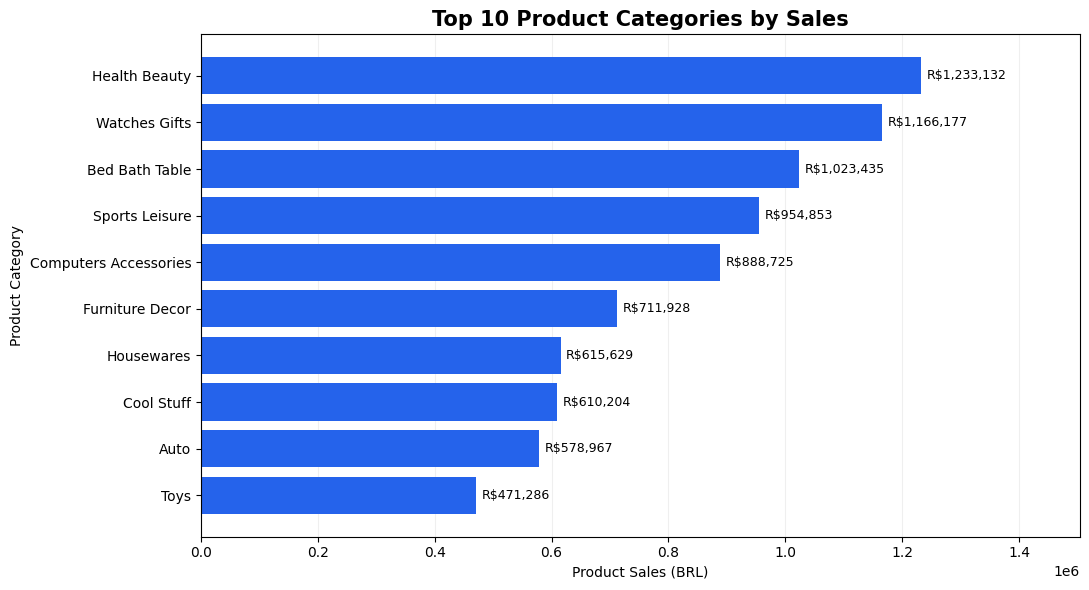

In [125]:
# Show the 10 highest-selling product categories.

category_data = get_top_categories(10).copy()

# Make category names easier to read.
category_data["category_name"] = (
    category_data["category"]
    .str.replace("_", " ", regex=False)
    .str.title()
)

# Sort categories for a horizontal chart.
category_data = category_data.sort_values(
    "product_sales", ascending=True
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    category_data["category_name"],
    category_data["product_sales"],
    color="#2563EB"
)

ax.set_title(
    "Top 10 Product Categories by Sales",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Product Sales (BRL)")
ax.set_ylabel("Product Category")

# Display exact sales values next to the bars.
ax.bar_label(
    bars,
    labels=[
        f"R${value:,.0f}"
        for value in category_data["product_sales"]
    ],
    padding=4,
    fontsize=9
)

ax.set_xlim(
    0,
    category_data["product_sales"].max() * 1.22
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 138.3: Monthly Product Sales Trend

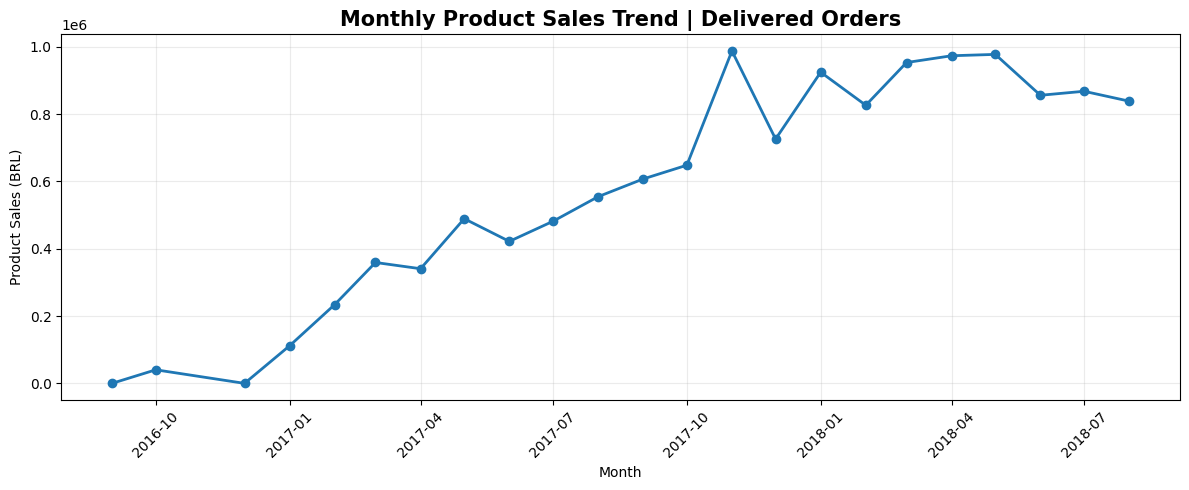

Monthly sales total: R$13,221,498.11
Verified sales total: R$13,221,498.11
Validation: PASS


In [126]:
# Calculate monthly sales for delivered orders.

monthly_orders = orders[
    orders["order_status"] == "delivered"
][["order_id", "order_purchase_timestamp"]].copy()

# Join order dates with product sales.
monthly_data = items[
    ["order_id", "price"]
].merge(
    monthly_orders,
    on="order_id",
    how="inner"
)

# Convert purchase dates into months.
monthly_data["month"] = pd.to_datetime(
    monthly_data["order_purchase_timestamp"]
).dt.to_period("M")

# Calculate total product sales for each month.
monthly_sales = (
    monthly_data.groupby("month")["price"]
    .sum()
    .reset_index(name="product_sales")
)

monthly_sales["month"] = (
    monthly_sales["month"].dt.to_timestamp()
)

# Display monthly sales trend.
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_sales["month"],
    monthly_sales["product_sales"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Monthly Product Sales Trend | Delivered Orders",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Product Sales (BRL)")

ax.grid(alpha=0.25)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Verify totals against the existing sales tool.
expected_sales = float(
    get_sales_summary().iloc[0]["product_sales"]
)

actual_sales = monthly_sales["product_sales"].sum()

print("Monthly sales total:", f"R${actual_sales:,.2f}")
print("Verified sales total:", f"R${expected_sales:,.2f}")

print(
    "Validation:",
    "PASS" if abs(actual_sales - expected_sales) < 0.01
    else "FAIL"
)

### 138.4: Monthly Timeline Quality Check

In [127]:
# Check missing months and incomplete periods.

monthly_check = monthly_sales.copy()

monthly_check["month"] = pd.to_datetime(
    monthly_check["month"]
)

# Create every calendar month between first and last.
all_months = pd.date_range(
    start=monthly_check["month"].min(),
    end=monthly_check["month"].max(),
    freq="MS"
)

missing_months = all_months.difference(
    monthly_check["month"]
)

print("First month:", monthly_check["month"].min().strftime("%Y-%m"))
print("Last month:", monthly_check["month"].max().strftime("%Y-%m"))

print("\nMissing calendar months:")
if len(missing_months) == 0:
    print("None")
else:
    for month in missing_months:
        print(month.strftime("%Y-%m"))

print("\nFirst three recorded months:")
display(monthly_check.head(3))

print("\nLast three recorded months:")
display(monthly_check.tail(3))

First month: 2016-09
Last month: 2018-08

Missing calendar months:
2016-11

First three recorded months:


,month,product_sales
0,2016-09-01,134.97
1,2016-10-01,40325.11
2,2016-12-01,10.90



Last three recorded months:


,month,product_sales
20,2018-06-01,856077.86
21,2018-07-01,867953.46
22,2018-08-01,838576.64


### 138.5: Monthly Sales Trend with Missing-Month Handling

Missing months:


,month,product_sales
2,2016-11-01,NaN


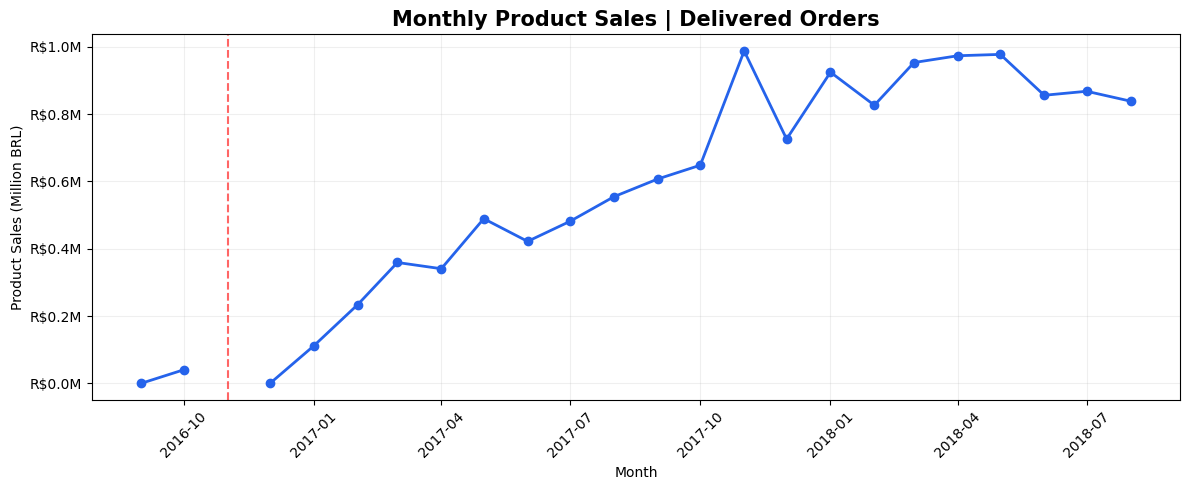

Recorded sales preserved: True


In [128]:
# Create a complete monthly timeline without inventing sales.

monthly_plot = monthly_sales.copy()

monthly_plot["month"] = pd.to_datetime(
    monthly_plot["month"]
)

# Include every calendar month.
monthly_plot = (
    monthly_plot.set_index("month")
    .asfreq("MS")
    .reset_index()
)

# Missing months remain NaN, not zero.
print("Missing months:")
display(
    monthly_plot[
        monthly_plot["product_sales"].isna()
    ]
)

# Plot recorded monthly sales.
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_plot["month"],
    monthly_plot["product_sales"],
    marker="o",
    linewidth=2,
    color="#2563EB"
)

# Mark the missing month.
for month in monthly_plot.loc[
    monthly_plot["product_sales"].isna(), "month"
]:
    ax.axvline(
        month,
        color="red",
        linestyle="--",
        alpha=0.6
    )

ax.set_title(
    "Monthly Product Sales | Delivered Orders",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Product Sales (Million BRL)")

# Format values in millions.
from matplotlib.ticker import FuncFormatter

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"R${x/1_000_000:.1f}M")
)

ax.grid(alpha=0.2)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Verify that recorded sales remain unchanged.
original_total = monthly_sales["product_sales"].sum()
plotted_total = monthly_plot["product_sales"].sum()

print(
    "Recorded sales preserved:",
    abs(original_total - plotted_total) < 0.01
)

### 138.6: Anomaly Monitoring Dashboard

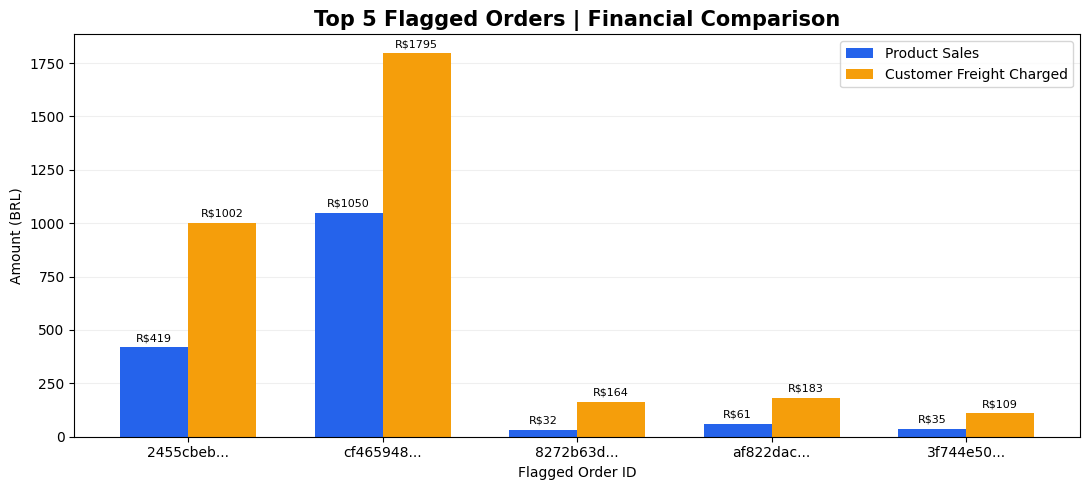

,order_id,order_value,freight_charged,anomaly_score,priority,investigation_summary
0,2455cbeb73fd04b170ca2504662f95ce,419.40,1002.29,-0.168861,High,Product sales are higher than the 95th percent...
1,cf4659487be50c0c317cff3564c4a840,1050.00,1794.96,-0.167792,High,Product sales are higher than the 95th percent...
2,8272b63d03f5f79c56e9e4120aec44ef,31.80,164.37,-0.167647,High,Customer freight charges are unusually high co...
3,af822dacd6f5cff7376413c03a388bb7,61.26,182.76,-0.163917,High,Customer freight charges are unusually high co...
4,3f744e5030fb02e02651eb31d5204878,35.40,109.38,-0.158828,High,Customer freight charges are unusually high co...


In [129]:
# Compare product sales and freight charges for flagged orders.

anomaly_data = get_top_anomalies(5).copy()

# Shorten order IDs to make the chart readable.
anomaly_data["order_label"] = (
    anomaly_data["order_id"].str[:8] + "..."
)

# Create a comparison chart.
fig, ax = plt.subplots(figsize=(11, 5))

x = range(len(anomaly_data))
width = 0.35

bars_sales = ax.bar(
    [i - width / 2 for i in x],
    anomaly_data["order_value"],
    width,
    label="Product Sales",
    color="#2563EB"
)

bars_freight = ax.bar(
    [i + width / 2 for i in x],
    anomaly_data["freight_charged"],
    width,
    label="Customer Freight Charged",
    color="#F59E0B"
)

ax.set_title(
    "Top 5 Flagged Orders | Financial Comparison",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Flagged Order ID")
ax.set_ylabel("Amount (BRL)")

ax.set_xticks(list(x))
ax.set_xticklabels(anomaly_data["order_label"])

ax.bar_label(
    bars_sales,
    fmt="R$%.0f",
    padding=3,
    fontsize=8
)

ax.bar_label(
    bars_freight,
    fmt="R$%.0f",
    padding=3,
    fontsize=8
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Display the underlying anomaly information.
display(
    anomaly_data[
        [
            "order_id",
            "order_value",
            "freight_charged",
            "anomaly_score",
            "priority",
            "investigation_summary"
        ]
    ]
)

### 138.7: Financial What-If Scenario Comparison

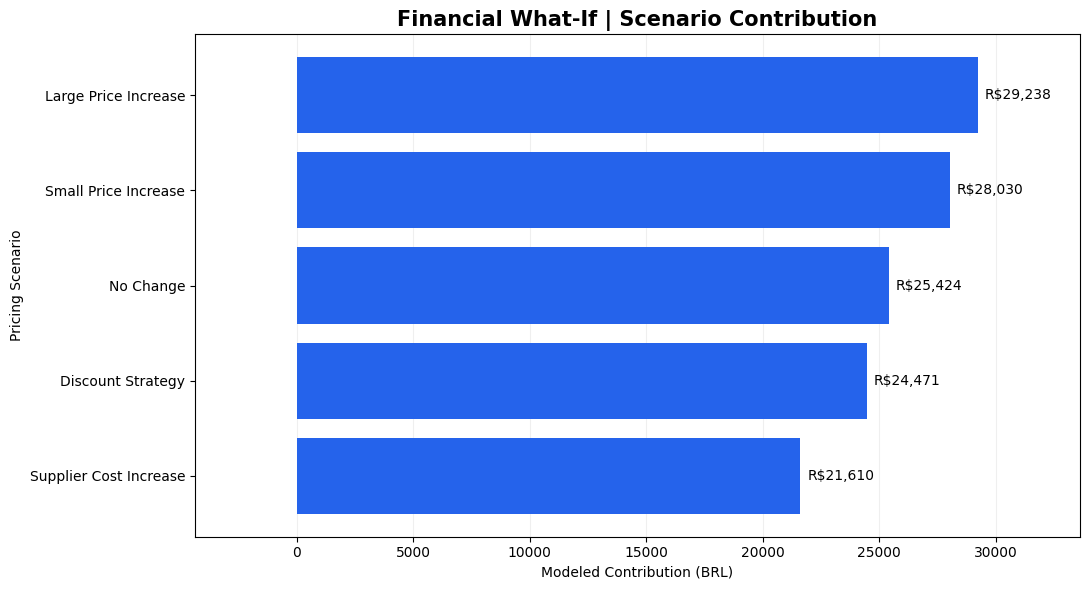

,Scenario,Price Change (%),Demand Change (%),Cost Change (%),Product Sales,Variable Cost,Contribution,Contribution Margin (%),Contribution Change,Rank
0,Large Price Increase,10,-8,0,64322.72,35085.12,29237.60,45.454545,3813.60,1
1,Small Price Increase,5,-2,0,65403.24,37373.28,28029.96,42.857143,2605.96,2
2,No Change,0,0,0,63560.00,38136.00,25424.00,40.000000,0.00,3
3,Discount Strategy,-5,10,0,66420.20,41949.60,24470.60,36.842105,-953.40,4
4,Supplier Cost Increase,0,0,10,63560.00,41949.60,21610.40,34.000000,-3813.60,5


In [130]:
# Compare saved financial scenarios without recalculating them.

scenario_path = (
    PROJECT_ROOT
    / "reports/decisions/scenario_comparison.csv"
)

scenario_data = pd.read_csv(scenario_path)

required_columns = [
    "Scenario",
    "Contribution",
    "Contribution Change",
    "Rank"
]

# Check that the report contains the required columns.
missing_columns = [
    col for col in required_columns
    if col not in scenario_data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing scenario columns: {missing_columns}"
    )

# Remove incomplete rows from the visualization.
scenario_plot = scenario_data.dropna(
    subset=required_columns
).copy()

if scenario_plot.empty:
    raise ValueError("No complete scenarios available.")

# Sort by modeled contribution.
scenario_plot = scenario_plot.sort_values(
    "Contribution",
    ascending=True
)

# Display scenario contributions.
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    scenario_plot["Scenario"],
    scenario_plot["Contribution"],
    color="#2563EB"
)

ax.bar_label(
    bars,
    labels=[
        f"R${value:,.0f}"
        for value in scenario_plot["Contribution"]
    ],
    padding=5
)

ax.set_title(
    "Financial What-If | Scenario Contribution",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Modeled Contribution (BRL)")
ax.set_ylabel("Pricing Scenario")

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

# Leave space for bar labels.
xmin = min(0, scenario_plot["Contribution"].min())
xmax = max(0, scenario_plot["Contribution"].max())
padding = max((xmax - xmin) * 0.15, 1)
ax.set_xlim(xmin - padding, xmax + padding)

plt.tight_layout()
plt.show()

# Show the scenario comparison table.
display(
    scenario_data.sort_values("Rank")
)

### 138.8: Interactive Financial Scenario Comparison

In [132]:
# Step 138.8: Compare two saved financial scenarios.
# Uses existing scenario_data without recalculating results.

import ipywidgets as widgets
from IPython.display import display, clear_output

# Get available scenarios.
scenario_names = scenario_data["Scenario"].tolist()

# Select baseline scenario.
scenario_a = widgets.Dropdown(
    options=scenario_names,
    value="No Change",
    description="Baseline:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="400px")
)

# Select comparison scenario.
scenario_b = widgets.Dropdown(
    options=scenario_names,
    value="Large Price Increase",
    description="Compare:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="400px")
)

comparison_output = widgets.Output()


# Calculate and display the comparison.
def compare_scenarios(change=None):

    with comparison_output:
        clear_output(wait=True)

        baseline = scenario_data.loc[
            scenario_data["Scenario"] == scenario_a.value
        ].iloc[0]

        comparison = scenario_data.loc[
            scenario_data["Scenario"] == scenario_b.value
        ].iloc[0]

        baseline_value = float(baseline["Contribution"])
        comparison_value = float(comparison["Contribution"])

        difference = comparison_value - baseline_value

        # Format positive and negative currency correctly.
        sign = "+" if difference > 0 else "-" if difference < 0 else ""

        formatted_difference = (
            f"{sign}R${abs(difference):,.2f}"
        )

        print("FINANCIAL SCENARIO COMPARISON")
        print("=" * 45)

        print(f"\nBaseline: {scenario_a.value}")
        print(f"Contribution: R${baseline_value:,.2f}")

        print(f"\nComparison: {scenario_b.value}")
        print(f"Contribution: R${comparison_value:,.2f}")

        print(
            f"\nContribution difference: {formatted_difference}"
        )

        if difference > 0:
            print(
                "\nResult: Comparison scenario has "
                "higher modeled contribution."
            )

        elif difference < 0:
            print(
                "\nResult: Comparison scenario has "
                "lower modeled contribution."
            )

        else:
            print(
                "\nResult: Both scenarios have "
                "equal modeled contribution."
            )

        print(
            "\nNote: These are hypothetical financial "
            "results based on assumed prices, demand, "
            "and variable costs. They are not actual net profit."
        )


# Update results automatically when selections change.
scenario_a.observe(compare_scenarios, names="value")
scenario_b.observe(compare_scenarios, names="value")


# Display the interactive comparison.
display(
    widgets.VBox([
        widgets.HTML(
            "<h3>ProfitLens AI | Financial Scenario Comparison</h3>"
        ),
        scenario_a,
        scenario_b,
        comparison_output
    ])
)

# Show the default comparison.
compare_scenarios()

## Step 139: Unified ProfitLens AI Dashboard

In [136]:
# Step 139: Combine existing analytics into one dashboard.
# Uses previously calculated data and approved business tools.

import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt

# Create dashboard tabs.
tab_names = [
    "Overview",
    "Sales Analytics",
    "Anomaly Monitor",
    "Financial Simulator",
    "AI Copilot"
]

outputs = [widgets.Output() for _ in tab_names]

tabs = widgets.Tab(children=outputs)

for i, name in enumerate(tab_names):
    tabs.set_title(i, name)

# -------------------------
# TAB 1: Business Overview
# -------------------------

with outputs[0]:
    display(dashboard)

# -------------------------
# TAB 2: Sales Analytics
# -------------------------

with outputs[1]:

    print("TOP PRODUCT CATEGORIES")

    category_chart = get_top_categories(10).copy()

    category_chart["category_name"] = (
        category_chart["category"]
        .str.replace("_", " ", regex=False)
        .str.title()
    )

    category_chart = category_chart.sort_values(
        "product_sales"
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.barh(
        category_chart["category_name"],
        category_chart["product_sales"]
    )

    ax.set_title("Top 10 Categories by Product Sales")
    ax.set_xlabel("Product Sales (BRL)")

    plt.tight_layout()
    plt.show()

    print("\nMONTHLY PRODUCT SALES")

    # monthly_plot was created in Step 138.5.
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        monthly_plot["month"],
        monthly_plot["product_sales"],
        marker="o"
    )

    ax.set_title("Monthly Product Sales | Delivered Orders")
    ax.set_ylabel("Product Sales (BRL)")
    ax.set_xlabel("Month")
    ax.grid(alpha=0.2)

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    print(
        "Note: Missing months remain NaN; "
        "they are not treated as zero sales."
    )

# -------------------------
# TAB 3: Anomaly Monitor
# -------------------------

with outputs[2]:

    anomaly_chart = get_top_anomalies(5).copy()

    anomaly_chart["short_id"] = (
        anomaly_chart["order_id"].str[:8]
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    x = range(len(anomaly_chart))
    width = 0.35

    ax.bar(
        [i - width / 2 for i in x],
        anomaly_chart["order_value"],
        width,
        label="Product Sales"
    )

    ax.bar(
        [i + width / 2 for i in x],
        anomaly_chart["freight_charged"],
        width,
        label="Customer Freight Charged"
    )

    ax.set_xticks(list(x))
    ax.set_xticklabels(anomaly_chart["short_id"])

    ax.set_title("Top 5 Flagged Orders")
    ax.set_ylabel("Amount (BRL)")
    ax.legend()

    plt.tight_layout()
    plt.show()

    print(
        "These orders are statistical anomalies, "
        "not confirmed fraud."
    )

# -------------------------
# TAB 4: Financial Simulator
# -------------------------

with outputs[3]:

    print("SAVED FINANCIAL SCENARIOS")

    display(
        scenario_data.sort_values("Rank")
    )

    print(
        "\nThese are hypothetical contribution results, "
        "not actual net profit."
    )

    # Reuse existing comparison widgets.
    display(
        widgets.VBox([
            scenario_a,
            scenario_b,
            comparison_output
        ])
    )

# -------------------------
# TAB 5: AI Business Copilot
# -------------------------

with outputs[4]:

    display(
        widgets.VBox([
            question_input,
            ask_button,
            chat_output
        ])
    )

# Display the complete dashboard.
display(
    widgets.VBox([
        widgets.HTML(
            "<h2>ProfitLens AI | Business Intelligence Dashboard</h2>"
        ),
        tabs
    ])
)

In [137]:
# TAB 1: Business Overview
# Get verified metrics directly from existing analytics tools.

with outputs[0]:

    sales_summary = get_sales_summary().iloc[0]
    cancellation_summary = get_cancellation_summary().iloc[0]

    # Create a simple KPI card.
    def overview_card(title, value, note):
        return widgets.HTML(
            value=f"""
            <div style="
                border: 1px solid #ddd;
                border-radius: 10px;
                padding: 16px;
                margin: 5px;
                background: white;
                color: #222;
                min-width: 200px;
            ">
                <div style="font-size:13px;color:#555;">
                    {title}
                </div>
                <div style="font-size:22px;font-weight:bold;margin:8px 0;">
                    {value}
                </div>
                <div style="font-size:12px;color:#666;">
                    {note}
                </div>
            </div>
            """
        )

    # Display four verified business metrics.
    overview = widgets.VBox([
        widgets.HTML("<h3>Business Overview</h3>"),

        widgets.HBox([
            overview_card(
                "Product Sales",
                f"R${sales_summary['product_sales']:,.2f}",
                "Delivered orders only"
            ),
            overview_card(
                "Delivered Orders",
                f"{int(sales_summary['total_orders']):,}",
                "Orders with item records"
            )
        ]),

        widgets.HBox([
            overview_card(
                "Customer Freight Charged",
                f"R${sales_summary['freight_charged']:,.2f}",
                "Not actual shipping expense"
            ),
            overview_card(
                "Cancellation Rate",
                f"{cancellation_summary['cancellation_rate_pct']:.2f}%",
                f"{int(cancellation_summary['canceled_orders']):,} canceled orders"
            )
        ])
    ])

    display(overview)

In [141]:
# TAB 1: Business Overview
# Display existing KPI cards inside the Overview tab.

with outputs[0]:
    clear_output(wait=True)
    display(overview)

print("Overview tab updated successfully.")

Overview tab updated successfully.


In [142]:
# Display the unified dashboard.

display(tabs)

## Step 140: Unified Dashboard Validation

In [143]:
# Step 140: Validate dashboard data and components.
# Uses existing tools without reloading datasets.

import pandas as pd

checks = []

# 1. Validate product sales.
sales = get_sales_summary().iloc[0]

checks.append({
    "Check": "Product sales",
    "Expected": 13221498.11,
    "Actual": round(float(sales["product_sales"]), 2),
    "Passed": abs(float(sales["product_sales"]) - 13221498.11) < 0.01
})

# 2. Validate delivered orders.
checks.append({
    "Check": "Delivered orders",
    "Expected": 96478,
    "Actual": int(sales["total_orders"]),
    "Passed": int(sales["total_orders"]) == 96478
})

# 3. Validate customer freight charged.
checks.append({
    "Check": "Customer freight charged",
    "Expected": 2198275.64,
    "Actual": round(float(sales["freight_charged"]), 2),
    "Passed": abs(float(sales["freight_charged"]) - 2198275.64) < 0.01
})

# 4. Validate cancellation data.
cancellations = get_cancellation_summary().iloc[0]

checks.append({
    "Check": "Canceled orders",
    "Expected": 625,
    "Actual": int(cancellations["canceled_orders"]),
    "Passed": int(cancellations["canceled_orders"]) == 625
})

# 5. Validate financial scenario arithmetic.
scenario_error = (
    scenario_data["Product Sales"]
    - scenario_data["Variable Cost"]
    - scenario_data["Contribution"]
).abs().max()

checks.append({
    "Check": "Scenario contribution arithmetic",
    "Expected": "Maximum error < 0.01",
    "Actual": round(float(scenario_error), 6),
    "Passed": scenario_error < 0.01
})

# 6. Check all five dashboard tabs exist.
checks.append({
    "Check": "Dashboard tabs",
    "Expected": 5,
    "Actual": len(tabs.children),
    "Passed": len(tabs.children) == 5
})

# Display validation results.
validation_results = pd.DataFrame(checks)

display(validation_results)

passed = int(validation_results["Passed"].sum())
total = len(validation_results)

print(f"\nValidation result: {passed}/{total} checks passed")

if passed == total:
    print("PASS: Dashboard data and structure checks passed.")
else:
    print("WARNING: Review the failed checks before continuing.")

,Check,Expected,Actual,Passed
0,Product sales,13221498.11,13221498.11,True
1,Delivered orders,96478,96478.00,True
2,Customer freight charged,2198275.64,2198275.64,True
3,Canceled orders,625,625.00,True
4,Scenario contribution arithmetic,Maximum error < 0.01,0.00,True
5,Dashboard tabs,5,5.00,True



Validation result: 6/6 checks passed
PASS: Dashboard data and structure checks passed.


## Step 141.1: Reusable Overview Component

In [144]:
# Step 141.1: Create a reusable Overview component.
# Reuses the existing verified KPI cards.

def render_overview():
    """Display the business overview KPI cards."""
    display(overview)


# Test the reusable function.
print("Testing Overview component:")
render_overview()

Testing Overview component:


## Step 141.2: Connect Overview Function to Dashboard

In [145]:
# Step 141.2: Update the Overview tab.
# Reuse the existing function and dashboard.

with outputs[0]:
    clear_output(wait=True)
    render_overview()

print("Overview tab updated successfully.")

Overview tab updated successfully.


## Step 141.3: Reusable Sales Analytics Component

In [146]:
# Step 141.3: Create a reusable Sales Analytics component.
# Reuses the existing dashboard output.

def render_sales_analytics():
    """Display the existing Sales Analytics section."""
    display(outputs[1])


# Test the reusable function.
print("Testing Sales Analytics component:")
render_sales_analytics()

Testing Sales Analytics component:


Output()

## Step 141.4: Reusable Anomaly Monitor Component

In [147]:
# Step 141.4: Create a reusable Anomaly Monitor component.
# Reuses the existing dashboard output.

def render_anomaly_monitor():
    """Display the existing Anomaly Monitor section."""
    display(outputs[2])


# Test the reusable function.
print("Testing Anomaly Monitor component:")
render_anomaly_monitor()

Testing Anomaly Monitor component:


Output()

## Step 141.5: Reusable Financial Simulator Component

In [148]:
# Step 141.5: Create a reusable Financial Simulator component.
# Reuses the existing dashboard output.

def render_financial_simulator():
    """Display the existing Financial Simulator section."""
    display(outputs[3])


# Test the reusable function.
print("Testing Financial Simulator component:")
render_financial_simulator()

Testing Financial Simulator component:


Output()

## Step 141.6: Reusable AI Copilot Component

In [149]:
# Step 141.6: Create a reusable AI Copilot component.
# Reuses the existing chatbot interface.

def render_ai_copilot():
    """Display the existing AI Copilot section."""
    display(outputs[4])


# Test the reusable function.
print("Testing AI Copilot component:")
render_ai_copilot()

Testing AI Copilot component:


Output()

## Step 142: Unified Dashboard Launcher

In [150]:
# Step 142: Create one function to open the dashboard.
# Reuses existing tabs and dashboard components.

def launch_profitlens_dashboard():
    """Display the complete ProfitLens AI dashboard."""

    display(
        widgets.VBox([
            widgets.HTML(
                "<h2>ProfitLens AI | Business Intelligence Dashboard</h2>"
            ),
            tabs
        ])
    )


# Launch the dashboard.
launch_profitlens_dashboard()

## Step 143: Dashboard Dependency Check

In [151]:
# Step 143: Check dashboard dependencies.
# No datasets or models are reloaded.

required_items = {
    "Sales summary tool": "get_sales_summary",
    "Category analytics tool": "get_top_categories",
    "Cancellation tool": "get_cancellation_summary",
    "Anomaly detection tool": "get_top_anomalies",
    "Scenario data": "scenario_data",
    "Monthly sales data": "monthly_plot",
    "Overview cards": "overview",
    "Dashboard tabs": "tabs",
    "Dashboard outputs": "outputs",
    "AI Copilot": "profitlens_ai",
    "Overview component": "render_overview",
    "Sales component": "render_sales_analytics",
    "Anomaly component": "render_anomaly_monitor",
    "Financial component": "render_financial_simulator",
    "Copilot component": "render_ai_copilot",
    "Dashboard launcher": "launch_profitlens_dashboard"
}

results = []

for description, variable in required_items.items():
    exists = variable in globals()

    results.append({
        "Component": description,
        "Variable": variable,
        "Available": exists
    })

dependency_check = pd.DataFrame(results)

display(dependency_check)

available = dependency_check["Available"].sum()
total = len(dependency_check)

print(f"\nDependencies available: {available}/{total}")

if available == total:
    print("PASS: All required dashboard components are available.")
else:
    print("WARNING: Some dashboard components are missing.")

,Component,Variable,Available
0,Sales summary tool,get_sales_summary,True
1,Category analytics tool,get_top_categories,True
2,Cancellation tool,get_cancellation_summary,True
3,Anomaly detection tool,get_top_anomalies,True
4,Scenario data,scenario_data,True
5,Monthly sales data,monthly_plot,True
6,Overview cards,overview,True
7,Dashboard tabs,tabs,True
8,Dashboard outputs,outputs,True
9,AI Copilot,profitlens_ai,True



Dependencies available: 16/16
PASS: All required dashboard components are available.


## Step 144: Dashboard Restart Readiness Check

In [152]:
# Step 144: Check dashboard restart requirements.
# This does not restart Colab or reload datasets.

restart_requirements = {
    "Google Drive": "PROJECT_ROOT",
    "SQLite connection": "conn_ai",
    "Sales analytics": "get_sales_summary",
    "Category analytics": "get_top_categories",
    "Cancellation analytics": "get_cancellation_summary",
    "Anomaly analytics": "get_top_anomalies",
    "Scenario data": "scenario_data",
    "Monthly sales data": "monthly_plot",
    "Dashboard KPI cards": "overview",
    "Dashboard tabs": "tabs",
    "Dashboard outputs": "outputs",
    "AI Copilot": "profitlens_ai",
    "Dashboard launcher": "launch_profitlens_dashboard"
}

restart_results = []

for component, variable in restart_requirements.items():

    value = globals().get(variable)

    restart_results.append({
        "Component": component,
        "Variable": variable,
        "Available": value is not None
    })

restart_check = pd.DataFrame(restart_results)

display(restart_check)

print(
    f"\nAvailable components: "
    f"{restart_check['Available'].sum()}/{len(restart_check)}"
)

print("\nNote: This checks the current session only.")
print("A fresh Colab restart test is still required.")

,Component,Variable,Available
0,Google Drive,PROJECT_ROOT,True
1,SQLite connection,conn_ai,True
2,Sales analytics,get_sales_summary,True
3,Category analytics,get_top_categories,True
4,Cancellation analytics,get_cancellation_summary,True
5,Anomaly analytics,get_top_anomalies,True
6,Scenario data,scenario_data,True
7,Monthly sales data,monthly_plot,True
8,Dashboard KPI cards,overview,True
9,Dashboard tabs,tabs,True



Available components: 13/13

Note: This checks the current session only.
A fresh Colab restart test is still required.


## Step 145: Verify Project Files and Database Connection

In [153]:
# Step 145: Check saved files and SQLite connection.
# Does not reload datasets or retrain models.

from pathlib import Path
import pandas as pd

project_path = Path(PROJECT_ROOT)

# Check important saved files.
files_to_check = {
    "Project folder": project_path,
    "SQLite database": project_path / "database/profitlens_olist.db",
    "Financial scenarios": (
        project_path / "reports/decisions/scenario_comparison.csv"
    )
}

results = []

for name, path in files_to_check.items():
    results.append({
        "Component": name,
        "Exists": path.exists(),
        "Path": str(path)
    })

file_check = pd.DataFrame(results)

display(file_check)

# Test the existing SQLite connection.
try:
    cursor = conn_ai.execute("SELECT 1")
    database_connected = cursor.fetchone()[0] == 1

except Exception as error:
    database_connected = False
    print("Database connection error:", error)

print("\nSQLite connection active:", database_connected)

# Final result.
all_files_exist = file_check["Exists"].all()

if all_files_exist and database_connected:
    print("\nPASS: Project files and database connection verified.")
else:
    print("\nWARNING: Some files or the database connection need attention.")

,Component,Exists,Path
0,Project folder,True,/content/drive/MyDrive/ProfitLens_AI
1,SQLite database,True,/content/drive/MyDrive/ProfitLens_AI/database/...
2,Financial scenarios,True,/content/drive/MyDrive/ProfitLens_AI/reports/d...



SQLite connection active: True

PASS: Project files and database connection verified.


## Step 146: Reusable Database Startup

In [154]:
# Step 146: Reconnect to the saved SQLite database.
# Reuses the existing project folder.

import sqlite3
from pathlib import Path

def connect_profitlens_database():
    """Connect to the saved ProfitLens AI database."""

    global conn_ai

    database_path = (
        Path(PROJECT_ROOT)
        / "database"
        / "profitlens_olist.db"
    )

    # Check that the database file exists.
    if not database_path.is_file():
        raise FileNotFoundError(
            f"Database not found: {database_path}"
        )

    # Reuse the existing connection if it is active.
    try:
        conn_ai.execute("SELECT 1")
        print("Existing SQLite connection is active.")
        return conn_ai

    except (NameError, sqlite3.Error):
        pass

    # Open a new database connection.
    conn_ai = sqlite3.connect(str(database_path))

    # Verify the new connection.
    conn_ai.execute("SELECT 1")

    print("SQLite database connected successfully.")

    return conn_ai


# Test the startup function.
connection = connect_profitlens_database()

print("Database ready:", connection is not None)


Existing SQLite connection is active.
Database ready: True


## Step 147: Reusable Financial Scenario Data Loader

In [155]:
# Step 147: Load saved financial scenarios.
# Uses the existing Google Drive project folder.

import pandas as pd
from pathlib import Path

def load_profitlens_scenarios():
    """Load and validate saved financial scenarios."""

    scenario_path = (
        Path(PROJECT_ROOT)
        / "reports"
        / "decisions"
        / "scenario_comparison.csv"
    )

    # Check whether the saved file exists.
    if not scenario_path.is_file():
        raise FileNotFoundError(
            f"Scenario file not found: {scenario_path}"
        )

    # Load the saved scenario data.
    data = pd.read_csv(scenario_path)

    # Check required columns.
    required_columns = [
        "Scenario",
        "Product Sales",
        "Variable Cost",
        "Contribution"
    ]

    missing = [
        col for col in required_columns
        if col not in data.columns
    ]

    if missing:
        raise ValueError(
            f"Missing scenario columns: {missing}"
        )

    # Verify the contribution calculations.
    error = (
        data["Product Sales"]
        - data["Variable Cost"]
        - data["Contribution"]
    ).abs()

    if data.empty or error.isna().any() or (error >= 0.01).any():
        raise ValueError(
            "Scenario data is empty or contribution validation failed."
        )

    print("Financial scenarios loaded successfully.")

    return data


# Load the scenarios into the existing variable.
scenario_data = load_profitlens_scenarios()

# Display the saved scenarios.
display(
    scenario_data[
        ["Scenario", "Product Sales", "Variable Cost", "Contribution"]
    ]
)

print(f"\nTotal scenarios loaded: {len(scenario_data)}")

Financial scenarios loaded successfully.


,Scenario,Product Sales,Variable Cost,Contribution
0,Large Price Increase,64322.72,35085.12,29237.60
1,Small Price Increase,65403.24,37373.28,28029.96
2,No Change,63560.00,38136.00,25424.00
3,Discount Strategy,66420.20,41949.60,24470.60
4,Supplier Cost Increase,63560.00,41949.60,21610.40



Total scenarios loaded: 5


## Step 148: ProfitLens AI Startup Manager

In [156]:
# Step 148: Initialize ProfitLens AI saved resources.
# Reuses the database and scenario loading functions.

def initialize_profitlens():
    """Initialize saved ProfitLens AI resources."""

    global scenario_data

    print("Starting ProfitLens AI...")
    print("=" * 40)

    # Step 1: Connect to the SQLite database.
    connection = connect_profitlens_database()

    # Step 2: Load saved financial scenarios.
    scenario_data = load_profitlens_scenarios()

    # Step 3: Confirm initialization.
    print("\nSTARTUP SUMMARY")
    print("=" * 40)

    print(
        "SQLite database:",
        "Connected" if connection is not None else "Failed"
    )

    print(
        "Financial scenarios:",
        len(scenario_data)
    )

    print("\nProfitLens AI saved resources are ready.")

    return {
        "database_connection": connection,
        "scenario_data": scenario_data
    }


# Test the startup manager.
startup_result = initialize_profitlens()

Starting ProfitLens AI...
Existing SQLite connection is active.
Financial scenarios loaded successfully.

STARTUP SUMMARY
SQLite database: Connected
Financial scenarios: 5

ProfitLens AI saved resources are ready.


## Step 149: ProfitLens AI Startup Health Check

In [157]:
# Step 149: Test initialized ProfitLens AI resources.
# Uses existing analytics tools and saved scenarios.

import pandas as pd

health_checks = []

# 1. Check SQLite database.
try:
    database_ok = conn_ai.execute(
        "SELECT 1"
    ).fetchone()[0] == 1
except Exception:
    database_ok = False

health_checks.append({
    "Component": "SQLite Database",
    "Passed": database_ok
})

# 2. Check sales analytics.
try:
    sales = get_sales_summary()
    sales_ok = (
        not sales.empty
        and abs(
            float(sales.iloc[0]["product_sales"])
            - 13221498.11
        ) < 0.01
    )
except Exception:
    sales_ok = False

health_checks.append({
    "Component": "Sales Analytics",
    "Passed": sales_ok
})

# 3. Check category analytics.
try:
    categories = get_top_categories(10)
    categories_ok = (
        not categories.empty
        and len(categories) == 10
    )
except Exception:
    categories_ok = False

health_checks.append({
    "Component": "Category Analytics",
    "Passed": categories_ok
})

# 4. Check cancellation analytics.
try:
    cancellations = get_cancellation_summary()
    cancellation_ok = (
        not cancellations.empty
        and int(
            cancellations.iloc[0]["canceled_orders"]
        ) == 625
    )
except Exception:
    cancellation_ok = False

health_checks.append({
    "Component": "Cancellation Analytics",
    "Passed": cancellation_ok
})

# 5. Check anomaly analytics.
try:
    anomalies = get_top_anomalies(5)
    anomaly_ok = (
        not anomalies.empty
        and len(anomalies) == 5
    )
except Exception:
    anomaly_ok = False

health_checks.append({
    "Component": "Anomaly Analytics",
    "Passed": anomaly_ok
})

# 6. Check financial scenarios.
try:
    scenario_ok = (
        len(scenario_data) == 5
        and (
            scenario_data["Product Sales"]
            - scenario_data["Variable Cost"]
            - scenario_data["Contribution"]
        ).abs().max() < 0.01
    )
except Exception:
    scenario_ok = False

health_checks.append({
    "Component": "Financial Scenarios",
    "Passed": scenario_ok
})

# Display results.
health_results = pd.DataFrame(health_checks)

display(health_results)

passed = int(health_results["Passed"].sum())
total = len(health_results)

print(f"\nStartup health checks: {passed}/{total} passed")

if passed == total:
    print("PASS: All tested business resources are ready.")
else:
    print("WARNING: Review the failed components.")

,Component,Passed
0,SQLite Database,True
1,Sales Analytics,True
2,Category Analytics,True
3,Cancellation Analytics,True
4,Anomaly Analytics,True
5,Financial Scenarios,True



Startup health checks: 6/6 passed
PASS: All tested business resources are ready.


## Step 150: ProfitLens AI Startup Sequence

In [158]:
# Step 150: Run the saved-resource startup sequence.
# Does not retrain models or rebuild the dashboard.

from pathlib import Path

def start_profitlens_resources():
    """Initialize and verify saved ProfitLens AI resources."""

    # Check Google Drive access.
    project_path = Path(
        "/content/drive/MyDrive/ProfitLens_AI"
    )

    if not project_path.is_dir():
        raise FileNotFoundError(
            "Project folder not found. Mount Google Drive first."
        )

    # Check required startup functions.
    required_functions = [
        "connect_profitlens_database",
        "load_profitlens_scenarios",
        "initialize_profitlens"
    ]

    missing = [
        name for name in required_functions
        if not callable(globals().get(name))
    ]

    if missing:
        raise RuntimeError(
            f"Run the function definition cells first: {missing}"
        )

    # Initialize the saved resources.
    result = initialize_profitlens()

    # Verify database access.
    connection = result["database_connection"]

    if connection.execute("SELECT 1").fetchone()[0] != 1:
        raise RuntimeError("SQLite connection check failed.")

    # Verify saved scenarios.
    scenarios = result["scenario_data"]

    if scenarios.empty:
        raise RuntimeError("No financial scenarios loaded.")

    print("\nSTARTUP STATUS: PASS")
    print("Database: Ready")
    print(f"Financial scenarios: {len(scenarios)}")
    print("Saved resources initialized successfully.")

    return result


# Test the startup sequence.
startup_status = start_profitlens_resources()

Starting ProfitLens AI...
Existing SQLite connection is active.
Financial scenarios loaded successfully.

STARTUP SUMMARY
SQLite database: Connected
Financial scenarios: 5

ProfitLens AI saved resources are ready.

STARTUP STATUS: PASS
Database: Ready
Financial scenarios: 5
Saved resources initialized successfully.


## Step 156: Streamlit Application Setup

In [168]:
# Step 156.1: Create Streamlit application folders.
# Files will be saved permanently in Google Drive.

from pathlib import Path

APP_ROOT = PROJECT_ROOT / "streamlit_app"

folders = [
    APP_ROOT,
    APP_ROOT / "pages",
    APP_ROOT / "components",
    APP_ROOT / "utils",
    APP_ROOT / "assets",
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

print("STREAMLIT APPLICATION STRUCTURE")
print("=" * 45)

for folder in folders:
    print(folder.relative_to(PROJECT_ROOT))

print("\nStreamlit application folders created successfully.")

STREAMLIT APPLICATION STRUCTURE
streamlit_app
streamlit_app/pages
streamlit_app/components
streamlit_app/utils
streamlit_app/assets

Streamlit application folders created successfully.


## Step 156.2: Create Main Streamlit Application

In [169]:
# Step 156.2: Create the first Streamlit application.
# Uses saved SQLite data. No model training required.

from pathlib import Path

APP_ROOT = PROJECT_ROOT / "streamlit_app"
APP_ROOT.mkdir(parents=True, exist_ok=True)

app_code = '''
import streamlit as st
import sqlite3
from pathlib import Path

st.set_page_config(
    page_title="ProfitLens AI",
    page_icon="📊",
    layout="wide"
)

PROJECT_ROOT = Path(__file__).resolve().parent.parent
DB_PATH = PROJECT_ROOT / "database/profitlens_olist.db"

st.title("📊 ProfitLens AI")
st.caption("Revenue, Sales Analytics & Business Decision Intelligence")

st.sidebar.title("Navigation")

page = st.sidebar.radio(
    "Select Section",
    [
        "Business Overview",
        "Sales Analytics",
        "Anomaly Detection",
        "Financial Simulator",
        "AI Business Copilot"
    ]
)

@st.cache_data
def load_overview():
    if not DB_PATH.is_file():
        return None

    with sqlite3.connect(str(DB_PATH)) as conn:
        sales = conn.execute("""
            SELECT
                COALESCE(SUM(oi.price), 0),
                COUNT(DISTINCT oi.order_id),
                COALESCE(SUM(oi.freight_value), 0)
            FROM order_items oi
            JOIN orders o ON oi.order_id = o.order_id
            WHERE o.order_status = 'delivered'
        """).fetchone()

        cancellations = conn.execute("""
            SELECT
                COUNT(*)
            FROM orders
            WHERE order_status = 'canceled'
        """).fetchone()[0]

        total_orders = conn.execute(
            "SELECT COUNT(*) FROM orders"
        ).fetchone()[0]

    return {
        "sales": sales[0],
        "delivered_orders": sales[1],
        "freight": sales[2],
        "cancellations": cancellations,
        "total_orders": total_orders
    }

if page == "Business Overview":

    st.header("Business Overview")

    try:
        data = load_overview()
    except sqlite3.Error as error:
        st.error(f"Unable to load database metrics: {error}")
        st.stop()

    if data is None:
        st.error("Saved SQLite database not found.")
        st.stop()

    cancellation_rate = (
        100 * data["cancellations"] / data["total_orders"]
        if data["total_orders"] else 0
    )

    col1, col2, col3, col4 = st.columns(4)

    col1.metric(
        "Product Sales",
        f"R${data['sales']:,.2f}"
    )

    col2.metric(
        "Delivered Orders",
        f"{data['delivered_orders']:,}"
    )

    col3.metric(
        "Cancellation Rate",
        f"{cancellation_rate:.2f}%"
    )

    col4.metric(
        "Customer Freight Charged",
        f"R${data['freight']:,.2f}"
    )

    st.info(
        "Sales and freight are based on delivered orders "
        "with item records. Freight charged to customers "
        "is not the actual shipping expense."
    )

elif page == "Sales Analytics":
    st.header("Sales Analytics")
    st.info("Sales charts and forecasting will be added next.")

elif page == "Anomaly Detection":
    st.header("Anomaly Detection")
    st.info("Saved anomaly investigation results will be connected.")

elif page == "Financial Simulator":
    st.header("Financial What-If Simulator")
    st.info("Saved hypothetical financial scenarios will be connected.")

elif page == "AI Business Copilot":
    st.header("AI Business Copilot")
    st.info("The verified business assistant will be integrated later.")
'''

app_path = APP_ROOT / "app.py"
app_path.write_text(app_code, encoding="utf-8")

print("Streamlit application created successfully!")
print("File:", app_path)
print("File size:", app_path.stat().st_size, "bytes")

Streamlit application created successfully!
File: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/app.py
File size: 3184 bytes


In [170]:
# # Install Streamlit in the current Colab session.
# %pip -q install streamlit

In [183]:
# Start ProfitLens AI in the background.

import subprocess
import time

app_path = PROJECT_ROOT / "streamlit_app" / "app.py"

log_file = open("/content/profitlens_streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", str(app_path),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit process ID:", streamlit_process.pid)
print("Process running:", streamlit_process.poll() is None)

Streamlit process ID: 24829
Process running: False


In [184]:
# Restart Streamlit for Google Colab proxy access.

import subprocess
import time

app_path = PROJECT_ROOT / "streamlit_app" / "app.py"

log_file = open("/content/profitlens_streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", str(app_path),
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit running:", streamlit_process.poll() is None)

Streamlit running: False


In [185]:
# Display the Streamlit dashboard inside Colab.

from google.colab import output

output.serve_kernel_port_as_iframe(8501, height=800)

<IPython.core.display.Javascript object>

In [179]:
# Step 157.1: Add top product categories chart.
# Update only the Sales Analytics section.

from pathlib import Path

app_path = PROJECT_ROOT / "streamlit_app" / "app.py"
app_code = app_path.read_text(encoding="utf-8")

old_section = '''elif page == "Sales Analytics":
    st.header("Sales Analytics")
    st.info("Sales charts and forecasting will be added next.")'''

new_section = '''elif page == "Sales Analytics":
    st.header("Sales Analytics")
    st.subheader("Top 10 Product Categories by Sales")

    @st.cache_data
    def load_category_sales():
        with sqlite3.connect(str(DB_PATH)) as conn:
            return pd.read_sql_query("""
                SELECT
                    COALESCE(t.product_category_name_english,
                             p.product_category_name,
                             'Unknown') AS category,
                    SUM(oi.price) AS product_sales
                FROM order_items oi
                JOIN orders o
                    ON oi.order_id = o.order_id
                JOIN products p
                    ON oi.product_id = p.product_id
                LEFT JOIN category_translation t
                    ON p.product_category_name =
                       t.product_category_name
                WHERE o.order_status = 'delivered'
                GROUP BY 1
                ORDER BY product_sales DESC
                LIMIT 10
            """, conn)

    try:
        category_sales = load_category_sales()

        st.bar_chart(
            category_sales,
            x="category",
            y="product_sales",
            x_label="Product Category",
            y_label="Product Sales (R$)"
        )

        st.dataframe(
            category_sales,
            hide_index=True,
            use_container_width=True
        )

        st.caption(
            "Product sales from delivered orders. "
            "These are not net profit figures."
        )

    except Exception as error:
        st.error(f"Unable to load sales chart: {error}")
'''

if old_section not in app_code:
    print("Sales Analytics section not found. No changes made.")
else:
    app_code = app_code.replace(old_section, new_section)

    # Add pandas import if missing.
    if "import pandas as pd" not in app_code:
        app_code = "import pandas as pd\n" + app_code

    app_path.write_text(app_code, encoding="utf-8")
    print("Sales Analytics section updated successfully!")

Sales Analytics section updated successfully!


In [187]:
# Step 157.4: Check whether Streamlit is already running.

import subprocess

result = subprocess.run(
    ["curl", "-s", "-m", "5", "-o", "/dev/null",
     "-w", "%{http_code}",
     "http://127.0.0.1:8501/_stcore/health"],
    capture_output=True,
    text=True
)

print("Streamlit HTTP status:", result.stdout)

if result.stdout == "200":
    print("Existing Streamlit server is running.")
    print("No restart needed.")
else:
    print("Port 8501 is not responding normally.")

Streamlit HTTP status: 200
Existing Streamlit server is running.
No restart needed.


In [189]:
# Step 157.6: Fix the missing category translation table.
# Update only the Sales Analytics query.

from pathlib import Path

app_path = PROJECT_ROOT / "streamlit_app" / "app.py"

app_code = app_path.read_text(encoding="utf-8")

old_query = """
                    COALESCE(t.product_category_name_english,
                             p.product_category_name,
                             'Unknown') AS category,
                    SUM(oi.price) AS product_sales
                FROM order_items oi
                JOIN orders o
                    ON oi.order_id = o.order_id
                JOIN products p
                    ON oi.product_id = p.product_id
                LEFT JOIN category_translation t
                    ON p.product_category_name =
                       t.product_category_name
"""

new_query = """
                    COALESCE(
                        p.product_category_name,
                        'Unknown'
                    ) AS category,
                    SUM(oi.price) AS product_sales
                FROM order_items oi
                JOIN orders o
                    ON oi.order_id = o.order_id
                JOIN products p
                    ON oi.product_id = p.product_id
"""

if old_query in app_code:
    updated_code = app_code.replace(old_query, new_query)

    # Check syntax before saving.
    compile(updated_code, str(app_path), "exec")

    app_path.write_text(updated_code, encoding="utf-8")

    print("Sales Analytics SQL query fixed successfully!")
else:
    print("Original query not found. No changes made.")

Sales Analytics SQL query fixed successfully!


In [191]:
# Step 158.1: Improve the existing sales chart.
# Keep the verified SQLite calculations unchanged.

from pathlib import Path

app_path = PROJECT_ROOT / "streamlit_app" / "app.py"
app_code = app_path.read_text(encoding="utf-8")

old_chart = '''        st.bar_chart(
            category_sales,
            x="category",
            y="product_sales",
            x_label="Product Category",
            y_label="Product Sales (R$)"
        )'''

new_chart = '''        # Translate displayed category names.
        translations = {
            "beleza_saude": "Health & Beauty",
            "relogios_presentes": "Watches & Gifts",
            "cama_mesa_banho": "Bed, Bath & Table",
            "esporte_lazer": "Sports & Leisure",
            "informatica_acessorios": "Computers & Accessories",
            "moveis_decoracao": "Furniture & Decor",
            "utilidades_domesticas": "Housewares",
            "cool_stuff": "Cool Stuff",
            "automotivo": "Automotive",
            "brinquedos": "Toys"
        }

        category_sales["category"] = (
            category_sales["category"]
            .replace(translations)
        )

        # Sort from highest to lowest product sales.
        category_sales = category_sales.sort_values(
            "product_sales", ascending=False
        )

        # Horizontal bar chart with readable labels.
        import plotly.express as px

        fig = px.bar(
            category_sales,
            x="product_sales",
            y="category",
            orientation="h",
            text="product_sales",
            labels={
                "product_sales": "Product Sales (R$)",
                "category": "Product Category"
            }
        )

        fig.update_traces(
            texttemplate="R$%{x:,.0f}",
            textposition="outside"
        )

        fig.update_layout(
            yaxis={
                "categoryorder": "array",
                "categoryarray": category_sales["category"].iloc[::-1].tolist()
            },
            height=520,
            margin=dict(l=20, r=90, t=20, b=20)
        )

        st.plotly_chart(fig, use_container_width=True)'''

if old_chart in app_code:
    updated_code = app_code.replace(old_chart, new_chart)

    # Validate Python syntax before saving.
    compile(updated_code, str(app_path), "exec")

    app_path.write_text(updated_code, encoding="utf-8")

    print("Sales chart updated successfully!")
else:
    print("Original chart code not found. No changes made.")

Sales chart updated successfully!


In [193]:
# Step 159.1: Connect saved anomaly detection results.
# No model retraining required.

from pathlib import Path

app_path = PROJECT_ROOT / "streamlit_app" / "app.py"
app_code = app_path.read_text(encoding="utf-8")

old_section = '''elif page == "Anomaly Detection":
    st.header("Anomaly Detection")
    st.info("Saved anomaly investigation results will be connected.")'''

new_section = '''elif page == "Anomaly Detection":
    st.header("Anomaly Detection")
    st.caption("Isolation Forest | Order Investigation Monitor")

    report_path = (
        PROJECT_ROOT
        / "reports/anomalies/anomaly_investigation_report.csv"
    )

    if not report_path.exists():
        st.error("Saved anomaly investigation report not found.")
        st.stop()

    @st.cache_data
    def load_anomalies():
        return pd.read_csv(report_path)

    anomaly_data = load_anomalies()

    st.metric("Orders in Investigation Report", len(anomaly_data))

    st.warning(
        "Anomalies are unusual transactions identified by a "
        "machine learning model. They are not confirmed fraud "
        "or financial losses."
    )

    st.subheader("Flagged Orders")

    st.dataframe(
        anomaly_data,
        hide_index=True,
        use_container_width=True
    )

    st.subheader("Anomaly Investigation Visualization")

    if {"order_value", "anomaly_score"}.issubset(anomaly_data.columns):

        import plotly.express as px

        fig = px.scatter(
            anomaly_data,
            x="order_value",
            y="anomaly_score",
            hover_data=["order_id"]
                if "order_id" in anomaly_data.columns else None,
            title="Order Value vs Anomaly Score",
            labels={
                "order_value": "Product Order Value (R$)",
                "anomaly_score": "Isolation Forest Anomaly Score"
            }
        )

        st.plotly_chart(fig, use_container_width=True)

    else:
        st.info(
            "The saved report does not contain the columns "
            "needed for the scatter chart."
        )
'''

if old_section in app_code:
    updated_code = app_code.replace(old_section, new_section)

    compile(updated_code, str(app_path), "exec")
    app_path.write_text(updated_code, encoding="utf-8")

    print("Anomaly Detection section connected successfully!")
else:
    print("Original Anomaly Detection section not found.")

Anomaly Detection section connected successfully!


In [195]:
# Step 160.1: Connect the saved Financial What-If Simulator.
# Uses hypothetical scenarios, not actual net profit.

from pathlib import Path

app_path = PROJECT_ROOT / "streamlit_app" / "app.py"
app_code = app_path.read_text(encoding="utf-8")

old_section = '''elif page == "Financial Simulator":
    st.header("Financial What-If Simulator")
    st.info("Saved hypothetical financial scenarios will be connected.")'''

new_section = '''elif page == "Financial Simulator":
    st.header("Financial What-If Simulator")
    st.caption("Compare hypothetical business decisions")

    scenario_path = (
        PROJECT_ROOT / "reports/decisions/scenario_comparison.csv"
    )

    if not scenario_path.is_file():
        st.error("Saved financial scenarios not found.")
        st.stop()

    @st.cache_data
    def load_scenarios():
        return pd.read_csv(scenario_path)

    scenarios = load_scenarios()

    required = {
        "Scenario", "Product Sales",
        "Variable Cost", "Contribution"
    }

    if not required.issubset(scenarios.columns):
        st.error("Required scenario columns are missing.")
        st.stop()

    # Validate saved financial calculations.
    difference = (
        scenarios["Product Sales"]
        - scenarios["Variable Cost"]
        - scenarios["Contribution"]
    ).abs()

    if (difference > 0.01).any():
        st.error("Scenario arithmetic validation failed.")
        st.stop()

    st.warning(
        "These are hypothetical financial scenarios. "
        "Contribution is product sales minus assumed variable costs, "
        "not verified net profit."
    )

    st.subheader("Saved Business Scenarios")

    st.dataframe(
        scenarios,
        hide_index=True,
        use_container_width=True
    )

    st.subheader("Compare Two Strategies")

    names = scenarios["Scenario"].tolist()

    col1, col2 = st.columns(2)

    with col1:
        strategy_a = st.selectbox("Strategy A", names, index=0)

    with col2:
        strategy_b = st.selectbox(
            "Strategy B", names,
            index=min(1, len(names) - 1)
        )

    a = scenarios.loc[
        scenarios["Scenario"] == strategy_a
    ].iloc[0]

    b = scenarios.loc[
        scenarios["Scenario"] == strategy_b
    ].iloc[0]

    col1, col2, col3 = st.columns(3)

    col1.metric(
        "Strategy A Contribution",
        f"R${a['Contribution']:,.2f}"
    )

    col2.metric(
        "Strategy B Contribution",
        f"R${b['Contribution']:,.2f}"
    )

    col3.metric(
        "Contribution Difference (A - B)",
        f"R${a['Contribution'] - b['Contribution']:,.2f}"
    )

    import plotly.express as px

    fig = px.bar(
        scenarios.sort_values("Contribution", ascending=False),
        x="Scenario",
        y="Contribution",
        title="Hypothetical Contribution by Scenario",
        labels={"Contribution": "Contribution (R$)"}
    )

    st.plotly_chart(fig, use_container_width=True)
'''

if old_section in app_code:
    updated_code = app_code.replace(old_section, new_section)

    compile(updated_code, str(app_path), "exec")
    app_path.write_text(updated_code, encoding="utf-8")

    print("Financial Simulator connected successfully!")
else:
    print("Original Financial Simulator section not found.")

Financial Simulator connected successfully!


In [199]:
# Step 161.4: Replace the exact AI Copilot placeholder.
# Keep all other dashboard sections unchanged.

from pathlib import Path

app_path = PROJECT_ROOT / "streamlit_app" / "app.py"
app_code = app_path.read_text(encoding="utf-8")

old_section = '''elif page == "AI Business Copilot":
    st.header("AI Business Copilot")
    st.info("The verified business assistant will be integrated later.")'''

new_section = '''elif page == "AI Business Copilot":
    st.header("AI Business Copilot")
    st.caption("Ask questions about verified business results")

    question = st.text_input(
        "Ask a business question",
        placeholder="What are our total product sales?"
    )

    if st.button("Ask ProfitLens AI") and question.strip():

        q = question.lower().strip()

        if any(term in q for term in [
            "net profit", "actual profit", "true profit"
        ]):
            st.warning(
                "Actual net profit cannot be calculated because "
                "verified cost and expense data are unavailable."
            )

        elif any(term in q for term in [
            "scenario", "strategy", "contribution"
        ]):
            scenario_path = (
                PROJECT_ROOT
                / "reports/decisions/scenario_comparison.csv"
            )

            scenarios = pd.read_csv(scenario_path)

            best = scenarios.sort_values(
                "Contribution", ascending=False
            ).iloc[0]

            st.success(
                f"Highest hypothetical contribution: "
                f"{best['Scenario']} "
                f"(R${best['Contribution']:,.2f})."
            )

            st.caption(
                "Based on saved hypothetical scenarios, "
                "not actual net profit."
            )

        elif any(term in q for term in [
            "sales", "revenue"
        ]):
            with sqlite3.connect(str(DB_PATH)) as conn:
                result = pd.read_sql_query("""
                    SELECT SUM(oi.price) AS product_sales
                    FROM order_items oi
                    JOIN orders o
                        ON oi.order_id = o.order_id
                    WHERE o.order_status = 'delivered'
                """, conn)

            sales = float(result.iloc[0]["product_sales"])

            st.success(
                f"Delivered-order product sales: R${sales:,.2f}"
            )

        else:
            st.info(
                "I can currently answer questions about "
                "product sales and saved financial scenarios. "
                "More business questions will be supported soon."
            )
'''

if old_section not in app_code:
    print("Exact placeholder not found. No changes made.")
else:
    updated_code = app_code.replace(old_section, new_section, 1)

    # Check syntax before saving.
    compile(updated_code, str(app_path), "exec")

    app_path.write_text(updated_code, encoding="utf-8")

    print("AI Business Copilot interface added successfully!")

AI Business Copilot interface added successfully!


In [198]:
# Step 161.3: Inspect the existing AI Copilot section.
# Read only. Do not modify app.py.

from pathlib import Path

app_path = PROJECT_ROOT / "streamlit_app" / "app.py"
lines = app_path.read_text(encoding="utf-8").splitlines()

for i, line in enumerate(lines):
    if 'page == "AI Business Copilot"' in line:
        print("AI COPILOT SECTION FOUND")
        print("=" * 55)

        for j in range(i, min(i + 25, len(lines))):
            print(f"{j + 1}: {lines[j]}")

        break
else:
    print("Exact section name not found.")
    print("\nLines containing 'Copilot':")

    for i, line in enumerate(lines):
        if "copilot" in line.lower():
            print(f"{i + 1}: {line}")

AI COPILOT SECTION FOUND
380: elif page == "AI Business Copilot":
381:     st.header("AI Business Copilot")
382:     st.info("The verified business assistant will be integrated later.")


In [200]:
# Open the existing Streamlit server.
from google.colab import output

output.serve_kernel_port_as_iframe(8501, height=800)

<IPython.core.display.Javascript object>

In [201]:
# Step 162.1: Inspect the existing Qwen model setup.
# Read only. No changes to project files.

import nbformat
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "ProfitLens AI/ProfitLens_AI_Cleaned.ipynb"
)

notebook = nbformat.read(notebook_path, as_version=4)

for cell_number in [143, 144, 145, 146, 147, 148, 150]:
    cell = notebook.cells[cell_number]
    source = cell.source

    print(f"\n{'=' * 55}")
    print(f"CELL {cell_number}")
    print("=" * 55)

    # Show function definitions and model-loading statements.
    for line in source.splitlines():
        stripped = line.strip()

        if (
            stripped.startswith("def ")
            or stripped.startswith("MODEL_NAME")
            or "from_pretrained(" in stripped
            or stripped.startswith("import torch")
            or stripped.startswith("from transformers")
        ):
            print(line)


CELL 143
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,

CELL 144
def ask_free_llm(question, max_new_tokens=150):

CELL 145
def route_business_question(question):

CELL 146
def execute_business_tool(route):

CELL 147
def brl(value):
def generate_verified_answer(route, result):

CELL 148
def safe_route_business_question(question):

CELL 150
def profitlens_ai(question, show_source=True):


In [202]:
# Step 162.2: Inspect Qwen Copilot dependencies.
# Read only. No files will be modified.

import ast
import nbformat
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "ProfitLens AI/ProfitLens_AI_Cleaned.ipynb"
)

notebook = nbformat.read(notebook_path, as_version=4)

copilot_cells = [143, 144, 145, 146, 147, 148, 150]

for cell_number in copilot_cells:
    source = notebook.cells[cell_number].source

    print(f"\n{'=' * 55}")
    print(f"CELL {cell_number}")
    print("=" * 55)

    try:
        tree = ast.parse(source)

        for node in tree.body:
            if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
                print(f"\nFunction: {node.name}")

                # Identify names referenced inside the function.
                loaded = {
                    n.id for n in ast.walk(node)
                    if isinstance(n, ast.Name)
                    and isinstance(n.ctx, ast.Load)
                }

                print("Referenced names:")
                print(", ".join(sorted(loaded)))

            elif isinstance(node, (ast.Import, ast.ImportFrom)):
                print("Import:", ast.unparse(node))

    except SyntaxError as error:
        print("Could not parse cell:", error)


CELL 143

CELL 144

Function: ask_free_llm
Referenced names:
answer, generated_tokens, inputs, max_new_tokens, messages, model, outputs, prompt, question, tokenizer, torch

CELL 145

Function: route_business_question
Referenced names:
ROUTER_SYSTEM, ROUTE_LABELS, candidate, candidate_scores, end, full_ids, full_mask, inputs, label, label_ids, len, log_probs, logits, max, messages, model, output, prompt, question, start, token_scores, tokenizer, torch

CELL 146

Function: execute_business_tool
Referenced names:
approved_tools, get_best_scenario, get_cancellation_summary, get_sales_summary, get_top_anomalies, get_top_categories, result, route

CELL 147

Function: brl
Referenced names:
float, value

Function: generate_verified_answer
Referenced names:
brl, df, enumerate, float, i, int, isinstance, lines, name, pd, result, route, row, str

CELL 148

Function: safe_route_business_question
Referenced names:
new_scenario, price_terms, profit_terms, q, question, re, route_business_question

C

In [203]:
# Step 163: Extract existing Copilot functions.
# Creates a separate Python module without modifying app.py.

import ast
import nbformat
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "ProfitLens AI/ProfitLens_AI_Cleaned.ipynb"
)

notebook = nbformat.read(notebook_path, as_version=4)

function_names = [
    "ask_free_llm",
    "route_business_question",
    "execute_business_tool",
    "brl",
    "generate_verified_answer",
    "safe_route_business_question",
    "profitlens_ai"
]

extracted = {}

for cell in notebook.cells:
    if cell.cell_type != "code":
        continue

    try:
        tree = ast.parse(cell.source)
    except SyntaxError:
        continue

    for node in tree.body:
        if isinstance(node, ast.FunctionDef):
            if node.name in function_names:
                extracted[node.name] = ast.get_source_segment(
                    cell.source, node
                )

missing = set(function_names) - set(extracted)

if missing:
    print("Missing functions:", sorted(missing))
else:
    module_path = (
        PROJECT_ROOT
        / "streamlit_app/utils/copilot_core.py"
    )

    module_path.parent.mkdir(parents=True, exist_ok=True)

    module_code = (
        '"""ProfitLens AI Copilot functions extracted from Colab."""\n\n'
        + "import re\n"
        + "import pandas as pd\n"
        + "import torch\n\n"
        + "\n\n".join(extracted[name] for name in function_names)
        + "\n"
    )

    compile(module_code, str(module_path), "exec")
    module_path.write_text(module_code, encoding="utf-8")

    print("Copilot module created successfully!")
    print("File:", module_path)
    print("Functions extracted:", len(extracted))

Copilot module created successfully!
File: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/utils/copilot_core.py
Functions extracted: 7


In [204]:
# Step 164: Create a reusable Qwen model loader.
# Does not change your existing Streamlit dashboard.

from pathlib import Path

module_path = (
    PROJECT_ROOT
    / "streamlit_app/utils/qwen_loader.py"
)

module_path.parent.mkdir(parents=True, exist_ok=True)

loader_code = '''
import streamlit as st
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"


@st.cache_resource(show_spinner="Loading Qwen AI model...")
def load_qwen_model():

    tokenizer = AutoTokenizer.from_pretrained(
        MODEL_NAME
    )

    device = "cuda" if torch.cuda.is_available() else "cpu"

    model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        torch_dtype=(
            torch.float16 if device == "cuda"
            else torch.float32
        ),
        low_cpu_mem_usage=True
    )

    model = model.to(device)
    model.eval()

    return tokenizer, model
'''

compile(loader_code, str(module_path), "exec")
module_path.write_text(loader_code, encoding="utf-8")

print("Qwen model loader created successfully!")
print("File:", module_path)

Qwen model loader created successfully!
File: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/utils/qwen_loader.py


In [205]:
# Step 165: Find missing dependencies in the original notebook.
# Read-only. Does not change your working Streamlit app.

import ast
import nbformat
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "ProfitLens AI/ProfitLens_AI_Cleaned.ipynb"
)

notebook = nbformat.read(notebook_path, as_version=4)

required_names = {
    "ROUTER_SYSTEM",
    "ROUTE_LABELS",
    "get_sales_summary",
    "get_top_categories",
    "get_cancellation_summary",
    "get_top_anomalies",
    "get_best_scenario",
}

found = {}

for cell_number, cell in enumerate(notebook.cells):
    if cell.cell_type != "code":
        continue

    try:
        tree = ast.parse(cell.source)
    except SyntaxError:
        continue

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if node.name in required_names:
                found[node.name] = cell_number

        elif isinstance(node, (ast.Assign, ast.AnnAssign)):
            targets = (
                node.targets
                if isinstance(node, ast.Assign)
                else [node.target]
            )

            for target in targets:
                if isinstance(target, ast.Name):
                    if target.id in required_names:
                        found[target.id] = cell_number

print("DEPENDENCY LOCATIONS")
print("=" * 50)

for name in sorted(required_names):
    if name in found:
        print(f"{name}: Cell {found[name]}")
    else:
        print(f"{name}: NOT FOUND")

print("\nMODULE FILES")
print("=" * 50)

for filename in ["copilot_core.py", "qwen_loader.py"]:
    path = PROJECT_ROOT / "streamlit_app/utils" / filename
    print(f"{filename}: {'EXISTS' if path.exists() else 'MISSING'}")

DEPENDENCY LOCATIONS
ROUTER_SYSTEM: Cell 145
ROUTE_LABELS: Cell 145
get_best_scenario: Cell 141
get_cancellation_summary: Cell 139
get_sales_summary: Cell 139
get_top_anomalies: Cell 140
get_top_categories: Cell 139

MODULE FILES
copilot_core.py: EXISTS
qwen_loader.py: EXISTS


In [206]:
# Step 166: Add original business tools and router settings.
# Does not modify app.py or load Qwen.

import ast
import nbformat
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "ProfitLens AI/ProfitLens_AI_Cleaned.ipynb"
)

module_path = (
    PROJECT_ROOT / "streamlit_app/utils/copilot_core.py"
)

notebook = nbformat.read(notebook_path, as_version=4)

required_functions = [
    "get_sales_summary",
    "get_top_categories",
    "get_cancellation_summary",
    "get_top_anomalies",
    "get_best_scenario"
]

required_constants = [
    "ROUTER_SYSTEM",
    "ROUTE_LABELS"
]

extracted = {}

for cell in notebook.cells:
    if cell.cell_type != "code":
        continue

    try:
        tree = ast.parse(cell.source)
    except SyntaxError:
        continue

    for node in tree.body:

        if isinstance(node, ast.FunctionDef):
            if node.name in required_functions:
                extracted[node.name] = ast.get_source_segment(
                    cell.source, node
                )

        elif isinstance(node, (ast.Assign, ast.AnnAssign)):
            targets = (
                node.targets if isinstance(node, ast.Assign)
                else [node.target]
            )

            for target in targets:
                if isinstance(target, ast.Name):
                    if target.id in required_constants:
                        extracted[target.id] = ast.get_source_segment(
                            cell.source, node
                        )

missing = (
    set(required_functions + required_constants)
    - set(extracted)
)

if missing:
    print("Missing dependencies:", sorted(missing))
    print("No changes made.")

elif not module_path.exists():
    print("copilot_core.py is missing. No changes made.")

else:
    current_code = module_path.read_text(encoding="utf-8")

    # Avoid adding the same dependencies twice.
    existing_tree = ast.parse(current_code)

    existing_names = set()

    for node in existing_tree.body:
        if isinstance(node, ast.FunctionDef):
            existing_names.add(node.name)

        elif isinstance(node, ast.Assign):
            for target in node.targets:
                if isinstance(target, ast.Name):
                    existing_names.add(target.id)

    additions = [
        extracted[name]
        for name in required_functions + required_constants
        if name not in existing_names
    ]

    updated_code = current_code

    if additions:
        updated_code += (
            "\n\n# Original verified business dependencies\n\n"
            + "\n\n".join(additions)
            + "\n"
        )

    # Verify syntax before saving.
    compile(updated_code, str(module_path), "exec")

    module_path.write_text(
        updated_code,
        encoding="utf-8"
    )

    print("Business dependencies added successfully!")
    print("New definitions added:", len(additions))
    print("Total required dependencies:", 7)
    print("File:", module_path)

Business dependencies added successfully!
New definitions added: 7
Total required dependencies: 7
File: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/utils/copilot_core.py


In [207]:
# Step 167: Inspect external dependencies.
# Read only. No changes to Streamlit or database.

import ast
from pathlib import Path

module_path = (
    PROJECT_ROOT / "streamlit_app/utils/copilot_core.py"
)

source = module_path.read_text(encoding="utf-8")
tree = ast.parse(source)

functions_to_check = [
    "get_sales_summary",
    "get_top_categories",
    "get_cancellation_summary",
    "get_top_anomalies",
    "get_best_scenario"
]

for node in tree.body:

    if not isinstance(node, ast.FunctionDef):
        continue

    if node.name not in functions_to_check:
        continue

    print(f"\n{'=' * 55}")
    print(f"FUNCTION: {node.name}")
    print("=" * 55)

    # Identify names used by the function.
    referenced = {
        n.id
        for n in ast.walk(node)
        if isinstance(n, ast.Name)
        and isinstance(n.ctx, ast.Load)
    }

    # Identify function arguments.
    arguments = {
        arg.arg
        for arg in node.args.args
    }

    # Identify locally assigned variables.
    local_variables = {
        n.id
        for n in ast.walk(node)
        if isinstance(n, ast.Name)
        and isinstance(n.ctx, ast.Store)
    }

    # Identify names defined outside the function.
    external_names = (
        referenced - arguments - local_variables
    )

    print("External names:")
    print(", ".join(sorted(external_names)))

    # Show database and file access statements.
    print("\nDatabase/file references:")

    for line in ast.get_source_segment(
        source, node
    ).splitlines():

        if any(term in line.lower() for term in [
            "sqlite",
            "connect(",
            "db_path",
            "read_csv",
            "read_sql",
            "project_root",
            "report",
            "database"
        ]):
            print(line.strip())


FUNCTION: get_sales_summary
External names:
conn_ai, pd

Database/file references:
return pd.read_sql_query(query, conn_ai)

FUNCTION: get_top_categories
External names:
conn_ai, int, max, min, pd

Database/file references:
return pd.read_sql_query(

FUNCTION: get_cancellation_summary
External names:
conn_ai, pd

Database/file references:
return pd.read_sql_query(query, conn_ai)

FUNCTION: get_top_anomalies
External names:
anomaly_report, int, max, min, pd

Database/file references:
if anomaly_report.empty:
anomaly_report

FUNCTION: get_best_scenario
External names:
pd, scenario_report

Database/file references:
if scenario_report.empty:
scenario_report


In [208]:
# Step 168: Create a data initialization function.
# Does not modify app.py or your original datasets.

from pathlib import Path

module_path = (
    PROJECT_ROOT / "streamlit_app/utils/copilot_core.py"
)

module_code = module_path.read_text(encoding="utf-8")

initialization_code = '''

# Streamlit-compatible business data initialization

import sqlite3
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/ProfitLens_AI")

DB_PATH = PROJECT_ROOT / "database/profitlens_olist.db"

ANOMALY_PATH = (
    PROJECT_ROOT
    / "reports/anomalies/anomaly_investigation_report.csv"
)

SCENARIO_PATH = (
    PROJECT_ROOT
    / "reports/decisions/scenario_comparison.csv"
)


def initialize_business_data():
    """Connect the Copilot to saved, verified business data."""

    global conn_ai, anomaly_report, scenario_report

    if not DB_PATH.is_file():
        raise FileNotFoundError(f"Database not found: {DB_PATH}")

    if not ANOMALY_PATH.is_file():
        raise FileNotFoundError(
            f"Anomaly report not found: {ANOMALY_PATH}"
        )

    if not SCENARIO_PATH.is_file():
        raise FileNotFoundError(
            f"Scenario report not found: {SCENARIO_PATH}"
        )

    conn_ai = sqlite3.connect(
        str(DB_PATH),
        check_same_thread=False
    )

    anomaly_report = pd.read_csv(ANOMALY_PATH)
    scenario_report = pd.read_csv(SCENARIO_PATH)

    return {
        "database": "Connected",
        "anomaly_records": len(anomaly_report),
        "scenario_records": len(scenario_report)
    }
'''

if "def initialize_business_data(" in module_code:
    print("Business data initializer already exists. No changes made.")

else:
    updated_code = module_code + initialization_code

    compile(updated_code, str(module_path), "exec")

    module_path.write_text(
        updated_code,
        encoding="utf-8"
    )

    print("Business data initializer added successfully!")
    print("File:", module_path)

Business data initializer added successfully!
File: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/utils/copilot_core.py


In [209]:
# Step 169: Test the five original business tools.

import sys
import importlib
from pathlib import Path

app_dir = PROJECT_ROOT / "streamlit_app"

if str(app_dir) not in sys.path:
    sys.path.insert(0, str(app_dir))

from utils import copilot_core

# Reload to include the latest changes.
importlib.reload(copilot_core)

# 1. Initialize the database and reports.
status = copilot_core.initialize_business_data()

print("BUSINESS DATA STATUS")
print("=" * 50)

for key, value in status.items():
    print(f"{key}: {value}")

# 2. Test all five business tools.
tests = {
    "Sales Summary": copilot_core.get_sales_summary,
    "Top Categories": lambda: copilot_core.get_top_categories(5),
    "Cancellation Summary": copilot_core.get_cancellation_summary,
    "Top Anomalies": lambda: copilot_core.get_top_anomalies(5),
    "Best Scenario": copilot_core.get_best_scenario
}

print("\nBUSINESS TOOL TEST RESULTS")
print("=" * 50)

for name, function in tests.items():
    try:
        result = function()

        print(f"\n{name}: SUCCESS")

        if hasattr(result, "head"):
            print(result.head().to_string(index=False))
        else:
            print(result)

    except Exception as error:
        print(f"\n{name}: FAILED")
        print(f"{type(error).__name__}: {error}")

BUSINESS DATA STATUS
database: Connected
anomaly_records: 2894
scenario_records: 5

BUSINESS TOOL TEST RESULTS

Sales Summary: SUCCESS
 total_orders  product_sales  freight_charged
        96478    13221498.11       2198275.64

Top Categories: SUCCESS
             category  product_sales
        health_beauty     1233131.72
        watches_gifts     1166176.98
       bed_bath_table     1023434.76
       sports_leisure      954852.55
computers_accessories      888724.61

Cancellation Summary: SUCCESS
 total_orders  canceled_orders  cancellation_rate_pct
        99441              625                   0.63

Top Anomalies: SUCCESS
                        order_id  order_value  freight_charged  anomaly_score priority                                                                                                                                                                                                                                                                                     

In [210]:
# Step 170: Add Qwen-powered business question answering.
# No changes to app.py.

from pathlib import Path

module_path = (
    PROJECT_ROOT / "streamlit_app/utils/copilot_core.py"
)

module_code = module_path.read_text(encoding="utf-8")

integration_code = '''

def configure_qwen(tokenizer_instance, model_instance):
    """Connect an already-loaded Qwen model to the Copilot."""
    global tokenizer, model
    tokenizer = tokenizer_instance
    model = model_instance


def answer_business_question(question):
    """Route a question and return a verified business answer."""

    if not question or not question.strip():
        return "Please enter a business question."

    if "model" not in globals() or "tokenizer" not in globals():
        raise RuntimeError("Qwen model has not been configured.")

    if "conn_ai" not in globals():
        raise RuntimeError("Business data has not been initialized.")

    # Use existing safety rules and Qwen question routing.
    route = safe_route_business_question(question)

    # Execute only the approved business tool.
    result = execute_business_tool(route)

    # Generate the answer from verified data.
    answer = generate_verified_answer(route, result)

    if isinstance(answer, str):
        return answer

    return str(answer)
'''

if "def answer_business_question(" in module_code:
    print("Qwen integration function already exists.")
else:
    updated_code = module_code + integration_code

    compile(updated_code, str(module_path), "exec")

    module_path.write_text(
        updated_code,
        encoding="utf-8"
    )

    print("Qwen business integration added successfully!")

Qwen business integration added successfully!


In [211]:
# Step 171: Test Qwen + verified business tools.
# Does not modify app.py.

import sys
import importlib
import torch

app_dir = PROJECT_ROOT / "streamlit_app"

if str(app_dir) not in sys.path:
    sys.path.insert(0, str(app_dir))

from utils import copilot_core

importlib.reload(copilot_core)

print("GPU available:", torch.cuda.is_available())

# Reuse the model already loaded in the notebook, if available.
if "model" in globals() and "tokenizer" in globals():
    print("Using existing notebook Qwen model.")

    qwen_model = model
    qwen_tokenizer = tokenizer

else:
    print("Loading Qwen model...")

    from transformers import (
        AutoTokenizer,
        AutoModelForCausalLM
    )

    MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

    qwen_tokenizer = AutoTokenizer.from_pretrained(
        MODEL_NAME
    )

    qwen_model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        torch_dtype=(
            torch.float16
            if torch.cuda.is_available()
            else torch.float32
        ),
        device_map="auto"
    )

qwen_model.eval()

# Connect the model to the Copilot.
copilot_core.configure_qwen(
    qwen_tokenizer,
    qwen_model
)

# Connect the verified database and reports.
status = copilot_core.initialize_business_data()

print("\nBusiness data:", status)

# Test the complete question-answering workflow.
questions = [
    "What are our total product sales?",
    "Which product categories generate the most sales?",
    "What is our actual net profit?"
]

for question in questions:
    print("\n" + "=" * 60)
    print("QUESTION:", question)

    try:
        answer = copilot_core.answer_business_question(
            question
        )

        print("ANSWER:", answer)

    except Exception as error:
        print(
            "ERROR:",
            type(error).__name__,
            str(error)
        )

GPU available: True
Using existing notebook Qwen model.

Business data: {'database': 'Connected', 'anomaly_records': 2894, 'scenario_records': 5}

QUESTION: What are our total product sales?
ANSWER: Delivered-order sales summary:
• Delivered orders with items: 96,478
• Product sales: R$13,221,498.11
• Customer freight charged: R$2,198,275.64

Freight charged is not shipping expense. These amounts do not represent net profit.

QUESTION: Which product categories generate the most sales?
ANSWER: Top three categories by product sales:
1. Health Beauty: R$1,233,131.72
2. Watches Gifts: R$1,166,176.98
3. Bed Bath Table: R$1,023,434.76

Rankings are based on product sales value, not units sold or profitability.

QUESTION: What is our actual net profit?
ANSWER: No verified data available.


In [212]:
# Step 172: Create the Streamlit Qwen service.
# Does not modify app.py.

from pathlib import Path

service_path = (
    PROJECT_ROOT
    / "streamlit_app/utils/copilot_service.py"
)

service_code = '''
import threading

from utils import copilot_core
from utils.qwen_loader import load_qwen_model

# Protect the shared model and SQLite connection
# from simultaneous requests.
_copilot_lock = threading.RLock()


def ask_profitlens(question):
    """Return a verified business answer using Qwen."""

    with _copilot_lock:

        tokenizer, model = load_qwen_model()

        copilot_core.configure_qwen(
            tokenizer,
            model
        )

        # Initialize data once per Streamlit process.
        if "conn_ai" not in vars(copilot_core):
            copilot_core.initialize_business_data()

        answer = copilot_core.answer_business_question(
            question
        )

        return answer
'''

compile(service_code, str(service_path), "exec")

service_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

service_path.write_text(
    service_code,
    encoding="utf-8"
)

print("Streamlit Qwen service created successfully!")
print("File:", service_path)

Streamlit Qwen service created successfully!
File: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/utils/copilot_service.py


In [213]:
# Step 173: Activate Qwen in Streamlit.
# Back up app.py before making changes.

from pathlib import Path
import ast
import shutil

app_path = PROJECT_ROOT / "streamlit_app" / "app.py"
backup_path = PROJECT_ROOT / "streamlit_app" / "app_before_qwen.py"

app_code = app_path.read_text(encoding="utf-8")
lines = app_code.splitlines(keepends=True)

# Locate the AI Business Copilot section.
start = next(
    (i for i, line in enumerate(lines)
     if line.startswith('elif page == "AI Business Copilot":')),
    None
)

if start is None:
    print("AI Business Copilot section not found. No changes made.")

else:
    # Find where this page section ends.
    end = next(
        (i for i in range(start + 1, len(lines))
         if lines[i].startswith(("elif page ==", "else:"))),
        len(lines)
    )

    new_section = '''elif page == "AI Business Copilot":
    st.header("AI Business Copilot")
    st.caption("Qwen AI with verified ProfitLens business data")

    question = st.text_input(
        "Ask a business question",
        placeholder="Which categories generate the most sales?"
    )

    if st.button("Ask ProfitLens AI"):
        if not question.strip():
            st.warning("Please enter a business question.")
        else:
            with st.spinner("Analyzing your business question..."):
                try:
                    from utils.copilot_service import ask_profitlens

                    answer = ask_profitlens(question)
                    st.markdown(answer)

                except Exception as error:
                    st.error(
                        "The AI Copilot could not complete this request."
                    )
                    st.caption(
                        f"{type(error).__name__}: {error}"
                    )
'''

    updated_code = (
        "".join(lines[:start])
        + new_section
        + "".join(lines[end:])
    )

    # Validate syntax before writing.
    ast.parse(updated_code)

    # Save a backup before modifying app.py.
    shutil.copy2(app_path, backup_path)

    app_path.write_text(
        updated_code,
        encoding="utf-8"
    )

    print("Qwen Business Copilot connected successfully!")
    print("Backup:", backup_path)

Qwen Business Copilot connected successfully!
Backup: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/app_before_qwen.py


In [214]:
# Release notebook Qwen before Streamlit loads its copy.

import gc
import torch

for name in ["model", "qwen_model", "tokenizer", "qwen_tokenizer"]:
    if name in globals():
        del globals()[name]

# The notebook Copilot module may still hold references.
if "copilot_core" in globals():
    for name in ["model", "tokenizer"]:
        if hasattr(copilot_core, name):
            delattr(copilot_core, name)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Notebook Qwen references released.")

Notebook Qwen references released.


In [215]:
# Step 174: Test the Streamlit Qwen service.
# Uses the same service as the Streamlit application.

import sys
import time

app_dir = PROJECT_ROOT / "streamlit_app"

if str(app_dir) not in sys.path:
    sys.path.insert(0, str(app_dir))

from utils.copilot_service import ask_profitlens

questions = [
    "What are our total product sales?",
    "Which product categories generate the most sales?",
    "How many orders were canceled?",
    "Which scenario has the highest contribution?",
    "What is our actual net profit?"
]

for i, question in enumerate(questions, 1):
    print(f"\n{'=' * 60}")
    print(f"TEST {i}: {question}")

    start = time.time()

    try:
        answer = ask_profitlens(question)

        print("\nANSWER:")
        print(answer)

        print(f"\nTime: {time.time() - start:.1f} seconds")

    except Exception as error:
        print(f"\nERROR: {type(error).__name__}: {error}")

2026-11-22 06:26:59.368 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.



TEST 1: What are our total product sales?


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]


ANSWER:
Delivered-order sales summary:
• Delivered orders with items: 96,478
• Product sales: R$13,221,498.11
• Customer freight charged: R$2,198,275.64

Freight charged is not shipping expense. These amounts do not represent net profit.

Time: 17.5 seconds

TEST 2: Which product categories generate the most sales?

ANSWER:
Top three categories by product sales:
1. Health Beauty: R$1,233,131.72
2. Watches Gifts: R$1,166,176.98
3. Bed Bath Table: R$1,023,434.76

Rankings are based on product sales value, not units sold or profitability.

Time: 1.2 seconds

TEST 3: How many orders were canceled?

ANSWER:
Total orders: 99,441
Canceled orders: 625
Cancellation rate: 0.63%

The rate measures the percentage of orders recorded as canceled.

Time: 0.3 seconds

TEST 4: Which scenario has the highest contribution?

ANSWER:
Highest-ranked saved scenario: Large Price Increase
Price change: +10%
Assumed demand change: -8%
Assumed cost change: +0%
Modeled product sales: R$64,322.72
Assumed variable

In [216]:
# Step 175: Improve the actual net profit response.
# Only updates the Copilot answer function.

from pathlib import Path

module_path = (
    PROJECT_ROOT / "streamlit_app/utils/copilot_core.py"
)

source = module_path.read_text(encoding="utf-8")

old_code = '''    # Use existing safety rules and Qwen question routing.
    route = safe_route_business_question(question)'''

new_code = '''    # Never estimate actual net profit without verified expenses.
    q = question.lower()

    if any(term in q for term in [
        "net profit",
        "actual profit",
        "true profit",
        "net income"
    ]):
        return (
            "Actual net profit cannot be calculated from the "
            "available verified data.\\\\n\\\\n"
            "ProfitLens AI has verified product sales and "
            "customer freight charges, but does not have "
            "complete verified product costs, operating expenses, "
            "taxes, and other required financial information.\\\\n\\\\n"
            "The Financial What-If Simulator shows hypothetical "
            "contribution, not actual net profit."
        )

    # Use existing safety rules and Qwen question routing.
    route = safe_route_business_question(question)'''

if old_code not in source:
    print("Target code not found. No changes made.")
else:
    updated = source.replace(old_code, new_code, 1)

    compile(updated, str(module_path), "exec")

    module_path.write_text(updated, encoding="utf-8")

    print("Net profit explanation improved successfully!")

Net profit explanation improved successfully!


In [217]:
# Step 176: Add chat history to the Streamlit AI Copilot.

from pathlib import Path
import ast
import shutil

app_path = PROJECT_ROOT / "streamlit_app" / "app.py"
backup_path = PROJECT_ROOT / "streamlit_app" / "app_before_chat.py"

lines = app_path.read_text(encoding="utf-8").splitlines(keepends=True)

start = next(
    (i for i, line in enumerate(lines)
     if line.startswith('elif page == "AI Business Copilot":')),
    None
)

if start is None:
    print("AI Business Copilot section not found. No changes made.")

else:
    # Find the next top-level page branch.
    end = next(
        (i for i in range(start + 1, len(lines))
         if lines[i].startswith(("elif page ==", "else:"))),
        len(lines)
    )

    new_section = '''elif page == "AI Business Copilot":
    st.header("AI Business Copilot")
    st.caption("Powered by Qwen and verified ProfitLens business data")

    from utils.copilot_service import ask_profitlens

    # Keep chat history during the Streamlit session.
    if "copilot_messages" not in st.session_state:
        st.session_state.copilot_messages = []

    if st.button("Clear conversation"):
        st.session_state.copilot_messages = []

    # Display previous questions and answers.
    for message in st.session_state.copilot_messages:
        with st.chat_message(message["role"]):
            st.markdown(message["content"])

    # Accept a new business question.
    question = st.chat_input(
        "Ask ProfitLens AI about your business..."
    )

    if question:
        st.session_state.copilot_messages.append({
            "role": "user",
            "content": question
        })

        with st.chat_message("user"):
            st.markdown(question)

        with st.chat_message("assistant"):
            with st.spinner("Analyzing business data..."):
                try:
                    answer = ask_profitlens(question)
                    st.markdown(answer)

                    st.session_state.copilot_messages.append({
                        "role": "assistant",
                        "content": answer
                    })

                except Exception as error:
                    st.error(
                        "The Copilot could not answer this question."
                    )
                    st.caption(
                        f"{type(error).__name__}: {error}"
                    )
'''

    updated_code = (
        "".join(lines[:start])
        + new_section
        + "".join(lines[end:])
    )

    # Check syntax before saving.
    ast.parse(updated_code)

    # Save a backup of the working application.
    shutil.copy2(app_path, backup_path)

    app_path.write_text(updated_code, encoding="utf-8")

    print("Chat interface added successfully!")
    print("Backup:", backup_path)

Chat interface added successfully!
Backup: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/app_before_chat.py


In [219]:
# Step 177: Add clickable suggested questions.

from pathlib import Path
import ast
import shutil

app_path = PROJECT_ROOT / "streamlit_app" / "app.py"
backup_path = PROJECT_ROOT / "streamlit_app" / "app_before_suggestions.py"

lines = app_path.read_text(encoding="utf-8").splitlines(keepends=True)

start = next(
    (i for i, line in enumerate(lines)
     if line.startswith('elif page == "AI Business Copilot":')),
    None
)

if start is None:
    print("AI Business Copilot section not found. No changes made.")

else:
    end = next(
        (i for i in range(start + 1, len(lines))
         if lines[i].startswith(("elif page ==", "else:"))),
        len(lines)
    )

    new_section = '''elif page == "AI Business Copilot":
    st.header("AI Business Copilot")
    st.caption("Qwen AI with verified ProfitLens business data")

    from utils.copilot_service import ask_profitlens

    if "copilot_messages" not in st.session_state:
        st.session_state.copilot_messages = []

    st.subheader("Suggested questions")

    suggestions = [
        "What are our total product sales?",
        "Which categories generate the most sales?",
        "How many orders were canceled?",
        "Which scenario has the highest contribution?",
        "Show the most unusual orders.",
        "What is our actual net profit?"
    ]

    selected_question = None

    # Display suggestions in two columns.
    columns = st.columns(2)

    for i, suggestion in enumerate(suggestions):
        with columns[i % 2]:
            if st.button(
                suggestion,
                key=f"copilot_suggestion_{i}",
                use_container_width=True
            ):
                selected_question = suggestion

    if st.button("Clear conversation"):
        st.session_state.copilot_messages = []
        st.rerun()

    st.divider()

    # Display conversation history.
    for message in st.session_state.copilot_messages:
        with st.chat_message(message["role"]):
            st.markdown(message["content"])

    typed_question = st.chat_input(
        "Ask ProfitLens AI about your business..."
    )

    # Accept either a suggested or typed question.
    question = selected_question or typed_question

    if question:
        st.session_state.copilot_messages.append({
            "role": "user",
            "content": question
        })

        with st.chat_message("user"):
            st.markdown(question)

        with st.chat_message("assistant"):
            with st.spinner("Analyzing business data..."):
                try:
                    answer = ask_profitlens(question)

                    st.markdown(answer)

                    st.session_state.copilot_messages.append({
                        "role": "assistant",
                        "content": answer
                    })

                except Exception as error:
                    st.error(
                        "The Copilot could not answer this question."
                    )
                    st.caption(
                        f"{type(error).__name__}: {error}"
                    )
'''

    updated_code = (
        "".join(lines[:start])
        + new_section
        + "".join(lines[end:])
    )

    ast.parse(updated_code)

    shutil.copy2(app_path, backup_path)

    app_path.write_text(
        updated_code,
        encoding="utf-8"
    )

    print("Suggested questions added successfully!")
    print("Backup:", backup_path)

Suggested questions added successfully!
Backup: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/app_before_suggestions.py


In [220]:
# Step 178: Improve verified answer explanations.

from pathlib import Path
import ast
import shutil

module_path = (
    PROJECT_ROOT / "streamlit_app/utils/copilot_core.py"
)

backup_path = module_path.with_name(
    "copilot_core_before_safety.py.bak"
)

source = module_path.read_text(encoding="utf-8")

tree = ast.parse(source)

target = next(
    (
        node for node in tree.body
        if isinstance(node, ast.FunctionDef)
        and node.name == "answer_business_question"
    ),
    None
)

if target is None:
    print("Answer function not found. No changes made.")

else:
    new_function = '''
def answer_business_question(question):
    """Answer business questions using verified ProfitLens tools."""

    if not question or not question.strip():
        return "Please enter a business question."

    q = question.lower().strip()

    # Protect against unsupported actual-profit claims.
    if any(term in q for term in [
        "net profit",
        "actual profit",
        "true profit",
        "net income"
    ]):
        return (
            "Actual net profit cannot be calculated from "
            "the available verified data.\\n\\n"
            "ProfitLens AI has verified product sales and "
            "customer freight charges, but complete verified "
            "business costs and expenses are unavailable.\\n\\n"
            "The What-If Simulator estimates hypothetical "
            "contribution, not actual net profit."
        )

    if "model" not in globals() or "tokenizer" not in globals():
        raise RuntimeError("Qwen model has not been configured.")

    if "conn_ai" not in globals():
        raise RuntimeError("Business data has not been initialized.")

    # Use existing Qwen routing and approved business tools.
    route = safe_route_business_question(question)

    result = execute_business_tool(route)

    answer = generate_verified_answer(route, result)

    if answer is None or not str(answer).strip():
        return (
            "I couldn't find a verified answer to that question. "
            "Try asking about sales, product categories, "
            "cancellations, unusual orders, or saved scenarios."
        )

    answer = str(answer)

    if answer.strip().lower() == "no verified data available.":
        return (
            "I don't have enough verified information to answer "
            "that question. You can ask about product sales, "
            "categories, cancellations, unusual orders, "
            "or saved financial scenarios."
        )

    return answer
'''

    lines = source.splitlines(keepends=True)

    start = target.lineno - 1
    end = target.end_lineno

    updated = (
        "".join(lines[:start])
        + new_function
        + "".join(lines[end:])
    )

    # Verify Python syntax before saving.
    ast.parse(updated)

    shutil.copy2(module_path, backup_path)

    module_path.write_text(
        updated,
        encoding="utf-8"
    )

    print("Copilot safety improvements saved successfully!")
    print("Backup:", backup_path)

Copilot safety improvements saved successfully!
Backup: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/utils/copilot_core_before_safety.py.bak


In [221]:
# Step 179: Reload updated Copilot code automatically.
# Does not modify app.py or restart Streamlit.

from pathlib import Path
import ast
import shutil

service_path = (
    PROJECT_ROOT
    / "streamlit_app/utils/copilot_service.py"
)

backup_path = service_path.with_name(
    "copilot_service_before_reload.py.bak"
)

new_code = '''
import importlib
import threading
from pathlib import Path

from utils import copilot_core
from utils.qwen_loader import load_qwen_model

_copilot_lock = threading.RLock()
_loaded_version = None


def ask_profitlens(question):
    """Answer using the latest verified Copilot logic."""

    global _loaded_version

    with _copilot_lock:

        # Reload Copilot logic only when its source changes.
        module_path = Path(copilot_core.__file__)
        current_version = module_path.stat().st_mtime_ns

        if current_version != _loaded_version:
            importlib.reload(copilot_core)
            _loaded_version = current_version

        # Load or reuse the cached Qwen model.
        tokenizer, model = load_qwen_model()

        copilot_core.configure_qwen(
            tokenizer,
            model
        )

        # Reconnect business data if the module was reloaded.
        if "conn_ai" not in vars(copilot_core):
            copilot_core.initialize_business_data()

        return copilot_core.answer_business_question(
            question
        )
'''

if not service_path.exists():
    print("Copilot service not found. No changes made.")

else:
    ast.parse(new_code)

    shutil.copy2(service_path, backup_path)

    service_path.write_text(
        new_code,
        encoding="utf-8"
    )

    print("Automatic Copilot code reloading added!")
    print("Backup:", backup_path)


Automatic Copilot code reloading added!
Backup: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/utils/copilot_service_before_reload.py.bak


In [222]:
# Step 180: Check application readiness.
# Read-only. No model loading or server restart.

from pathlib import Path
import ast
import importlib.util

root = PROJECT_ROOT
app_dir = root / "streamlit_app"

files_to_check = {
    "Streamlit application": app_dir / "app.py",
    "Copilot core": app_dir / "utils/copilot_core.py",
    "Copilot service": app_dir / "utils/copilot_service.py",
    "Qwen loader": app_dir / "utils/qwen_loader.py",
    "SQLite database": root / "database/profitlens_olist.db",
    "Anomaly report": (
        root / "reports/anomalies/anomaly_investigation_report.csv"
    ),
    "Financial scenarios": (
        root / "reports/decisions/scenario_comparison.csv"
    )
}

print("PROFITLENS AI DEPLOYMENT CHECK")
print("=" * 55)

all_files_exist = True

for name, path in files_to_check.items():
    exists = path.is_file()

    print(f"{name}: {'OK' if exists else 'MISSING'}")

    if not exists:
        all_files_exist = False

print("\nPYTHON SYNTAX")
print("=" * 55)

python_files = [
    path for path in files_to_check.values()
    if path.suffix == ".py" and path.is_file()
]

syntax_ok = True

for path in python_files:
    try:
        ast.parse(path.read_text(encoding="utf-8"))
        print(f"{path.name}: OK")
    except SyntaxError as error:
        syntax_ok = False
        print(f"{path.name}: ERROR - {error}")

print("\nPYTHON DEPENDENCIES")
print("=" * 55)

packages = [
    "streamlit",
    "pandas",
    "plotly",
    "torch",
    "transformers",
    "accelerate"
]

missing_packages = []

for package in packages:
    installed = importlib.util.find_spec(package) is not None

    print(f"{package}: {'OK' if installed else 'MISSING'}")

    if not installed:
        missing_packages.append(package)

print("\nDEPLOYMENT NOTES")
print("=" * 55)

if all_files_exist and syntax_ok and not missing_packages:
    print("Local Colab file and dependency checks passed.")
else:
    print("Some checks need attention.")

print(
    "External deployment still requires portable data paths, "
    "dependency pinning, model hosting, and security checks."
)

PROFITLENS AI DEPLOYMENT CHECK
Streamlit application: OK
Copilot core: OK
Copilot service: OK
Qwen loader: OK
SQLite database: OK
Anomaly report: OK
Financial scenarios: OK

PYTHON SYNTAX
app.py: OK
copilot_core.py: OK
copilot_service.py: OK
qwen_loader.py: OK

PYTHON DEPENDENCIES
streamlit: OK
pandas: OK
plotly: OK
torch: OK
transformers: OK
accelerate: OK

DEPLOYMENT NOTES
Local Colab file and dependency checks passed.
External deployment still requires portable data paths, dependency pinning, model hosting, and security checks.


In [223]:
# Step 181: Create portable project configuration.

from pathlib import Path

config_path = (
    PROJECT_ROOT
    / "streamlit_app/config.py"
)

config_code = '''
"""ProfitLens AI project configuration."""

import os
from pathlib import Path

# Current Colab location, used as a fallback.
DEFAULT_PROJECT_ROOT = Path(
    "/content/drive/MyDrive/ProfitLens_AI"
)

# Can be overridden when deployed elsewhere.
PROJECT_ROOT = Path(
    os.environ.get(
        "PROFITLENS_PROJECT_ROOT",
        str(DEFAULT_PROJECT_ROOT)
    )
).expanduser().resolve()

DB_PATH = (
    PROJECT_ROOT
    / "database/profitlens_olist.db"
)

ANOMALY_PATH = (
    PROJECT_ROOT
    / "reports/anomalies/anomaly_investigation_report.csv"
)

SCENARIO_PATH = (
    PROJECT_ROOT
    / "reports/decisions/scenario_comparison.csv"
)

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
'''

compile(config_code, str(config_path), "exec")

config_path.write_text(
    config_code,
    encoding="utf-8"
)

print("Portable configuration created successfully!")
print("File:", config_path)

Portable configuration created successfully!
File: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/config.py


In [224]:
# Step 182: Connect the portable configuration.
# Back up both files before modifying them.

from pathlib import Path
import ast
import shutil

app_dir = PROJECT_ROOT / "streamlit_app"

app_path = app_dir / "app.py"
core_path = app_dir / "utils/copilot_core.py"
config_path = app_dir / "config.py"

if not config_path.is_file():
    print("config.py not found. Run Step 181 first.")

else:
    def update_paths(path):
        source = path.read_text(encoding="utf-8")
        tree = ast.parse(source)
        lines = source.splitlines(keepends=True)

        # Only replace top-level path assignments.
        replacements = {
            "PROJECT_ROOT": "PROJECT_ROOT",
            "DB_PATH": "DB_PATH",
            "ANOMALY_PATH": "ANOMALY_PATH",
            "SCENARIO_PATH": "SCENARIO_PATH",
        }

        edits = []

        for node in tree.body:
            if isinstance(node, ast.Assign):
                targets = [
                    t.id for t in node.targets
                    if isinstance(t, ast.Name)
                ]
            elif isinstance(node, ast.AnnAssign):
                targets = (
                    [node.target.id]
                    if isinstance(node.target, ast.Name)
                    else []
                )
            else:
                continue

            for name in targets:
                if name in replacements:
                    edits.append((
                        node.lineno - 1,
                        node.end_lineno,
                        f"{name} = _config.{name}\n"
                    ))
                    break

        for start, end, replacement in reversed(edits):
            lines[start:end] = [replacement]

        updated = "".join(lines)

        if "import config as _config" not in updated:
            updated = "import config as _config\n" + updated

        ast.parse(updated)
        return updated, len(edits)

    try:
        updated_app, app_changes = update_paths(app_path)
        updated_core, core_changes = update_paths(core_path)

        # Save backups before changing either file.
        shutil.copy2(
            app_path,
            app_dir / "app_before_portable_config.py.bak"
        )

        shutil.copy2(
            core_path,
            app_dir / "utils/copilot_core_before_config.py.bak"
        )

        app_path.write_text(updated_app, encoding="utf-8")
        core_path.write_text(updated_core, encoding="utf-8")

        print("Portable configuration connected successfully!")
        print("app.py path assignments updated:", app_changes)
        print("copilot_core.py path assignments updated:", core_changes)

    except Exception as error:
        print("No changes saved.")
        print(type(error).__name__, str(error))

Portable configuration connected successfully!
app.py path assignments updated: 2
copilot_core.py path assignments updated: 4


In [225]:
# Step 183: Verify portable configuration.

from pathlib import Path
import ast
import sys

app_dir = PROJECT_ROOT / "streamlit_app"

files = [
    app_dir / "config.py",
    app_dir / "app.py",
    app_dir / "utils/copilot_core.py",
    app_dir / "utils/copilot_service.py",
]

print("PROFITLENS AI CONFIGURATION CHECK")
print("=" * 50)

all_ok = True

for path in files:
    try:
        ast.parse(path.read_text(encoding="utf-8"))
        print(f"OK: {path.name}")
    except Exception as e:
        all_ok = False
        print(f"ERROR: {path.name}: {e}")

# Check configured paths without loading the Qwen model.
if str(app_dir) not in sys.path:
    sys.path.insert(0, str(app_dir))

import config

print("\nDATA PATH CHECK")
print("=" * 50)

for name, path in {
    "Database": config.DB_PATH,
    "Anomaly report": config.ANOMALY_PATH,
    "Scenario report": config.SCENARIO_PATH,
}.items():
    exists = Path(path).is_file()
    print(f"{name}: {'OK' if exists else 'MISSING'}")
    all_ok = all_ok and exists

print("\nRESULT")
print("=" * 50)

if all_ok:
    print("Configuration and file checks passed!")
else:
    print("Some checks failed. Review the errors above.")


PROFITLENS AI CONFIGURATION CHECK
OK: config.py
OK: app.py
OK: copilot_core.py
OK: copilot_service.py

DATA PATH CHECK
Database: OK
Anomaly report: OK
Scenario report: OK

RESULT
Configuration and file checks passed!


In [226]:
# Step 184: Create requirements.txt

from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

app_dir = PROJECT_ROOT / "streamlit_app"
requirements_path = app_dir / "requirements.txt"

packages = [
    "streamlit",
    "pandas",
    "numpy",
    "plotly",
    "scikit-learn",
    "torch",
    "transformers",
    "accelerate",
    "safetensors",
    "sentencepiece"
]

requirements = []
missing = []

for package in packages:
    try:
        installed_version = version(package)
        requirements.append(
            f"{package}=={installed_version}"
        )
    except PackageNotFoundError:
        missing.append(package)

requirements_path.write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

print("REQUIREMENTS FILE CREATED")
print("=" * 50)
print(requirements_path)

print("\nINSTALLED LIBRARIES")
print("=" * 50)
print(requirements_path.read_text())

if missing:
    print("Packages not installed:", ", ".join(missing))

print(
    "\nNote: This records current versions. "
    "Deployment compatibility still needs testing."
)

REQUIREMENTS FILE CREATED
/content/drive/MyDrive/ProfitLens_AI/streamlit_app/requirements.txt

INSTALLED LIBRARIES
streamlit==1.67.0
pandas==2.2.3
numpy==2.4.6
plotly==5.24.1
scikit-learn==1.6.1
torch==2.14.1+cu130
transformers==5.22.1
accelerate==1.15.0
safetensors==0.8.0
sentencepiece==0.2.2


Note: This records current versions. Deployment compatibility still needs testing.


In [227]:
# Step 185: Scan for Colab-specific dependencies.

from pathlib import Path
import ast

app_dir = PROJECT_ROOT / "streamlit_app"

patterns = [
    "/content/",
    "/content/drive/",
    "google.colab",
    "drive.mount",
    "serve_kernel_port",
    "localhost",
    "127.0.0.1"
]

print("PROFITLENS AI PORTABILITY SCAN")
print("=" * 60)

python_files = sorted(app_dir.rglob("*.py"))

issues = []

for file_path in python_files:

    # Skip backup files.
    if file_path.name.endswith(".bak"):
        continue

    source = file_path.read_text(encoding="utf-8")

    for line_number, line in enumerate(
        source.splitlines(), start=1
    ):
        for pattern in patterns:
            if pattern.lower() in line.lower():

                issues.append({
                    "file": str(file_path.relative_to(app_dir)),
                    "line": line_number,
                    "pattern": pattern,
                    "code": line.strip()[:120]
                })

                break

print(f"Python files scanned: {len(python_files)}")
print(f"Potential portability issues: {len(issues)}")

print("\nFINDINGS")
print("=" * 60)

if not issues:
    print("No matching Colab-specific patterns found.")
else:
    for issue in issues:
        print(f"\nFile: {issue['file']}")
        print(f"Line: {issue['line']}")
        print(f"Pattern: {issue['pattern']}")
        print(f"Code: {issue['code']}")

print("\nSCAN COMPLETE")

PROFITLENS AI PORTABILITY SCAN
Python files scanned: 8
Potential portability issues: 1

FINDINGS

File: config.py
Line: 9
Pattern: /content/
Code: "/content/drive/MyDrive/ProfitLens_AI"

SCAN COMPLETE


In [228]:
# Step 186: Improve portable project paths.

from pathlib import Path
import shutil
import ast

config_path = (
    PROJECT_ROOT / "streamlit_app/config.py"
)

backup_path = config_path.with_name(
    "config_before_portability.py.bak"
)

new_config = '''
"""ProfitLens AI portable configuration."""

import os
from pathlib import Path

# This file lives inside streamlit_app.
APP_DIR = Path(__file__).resolve().parent

# Project folder is one level above streamlit_app.
LOCAL_PROJECT_ROOT = APP_DIR.parent

# Original Google Colab project location.
COLAB_PROJECT_ROOT = Path(
    "/content/drive/MyDrive/ProfitLens_AI"
)

# Priority:
# 1. Environment variable
# 2. Google Colab Drive, when available
# 3. Local project directory

configured_root = os.environ.get(
    "PROFITLENS_PROJECT_ROOT"
)

if configured_root:
    PROJECT_ROOT = Path(configured_root).expanduser().resolve()

elif COLAB_PROJECT_ROOT.is_dir():
    PROJECT_ROOT = COLAB_PROJECT_ROOT.resolve()

else:
    PROJECT_ROOT = LOCAL_PROJECT_ROOT

DB_PATH = (
    PROJECT_ROOT / "database/profitlens_olist.db"
)

ANOMALY_PATH = (
    PROJECT_ROOT
    / "reports/anomalies/anomaly_investigation_report.csv"
)

SCENARIO_PATH = (
    PROJECT_ROOT
    / "reports/decisions/scenario_comparison.csv"
)

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
'''

# Check syntax before saving.
ast.parse(new_config)

# Back up existing configuration.
shutil.copy2(config_path, backup_path)

# Save improved configuration.
config_path.write_text(
    new_config,
    encoding="utf-8"
)

print("Portable configuration updated successfully!")
print("Backup:", backup_path)

# Verify configuration using a fresh module load.
import importlib.util

spec = importlib.util.spec_from_file_location(
    "profitlens_config_check",
    config_path
)

config_check = importlib.util.module_from_spec(spec)
spec.loader.exec_module(config_check)

print("\nPROJECT LOCATION")
print(config_check.PROJECT_ROOT)

print("\nDATA FILES")

for name, path in {
    "Database": config_check.DB_PATH,
    "Anomaly report": config_check.ANOMALY_PATH,
    "Scenario report": config_check.SCENARIO_PATH
}.items():
    print(
        f"{name}: {'OK' if path.is_file() else 'MISSING'}"
    )

Portable configuration updated successfully!
Backup: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/config_before_portability.py.bak

PROJECT LOCATION
/content/drive/MyDrive/ProfitLens_AI

DATA FILES
Database: OK
Anomaly report: OK
Scenario report: OK


In [229]:
# Step 187: Create deployment requirements.
# Keep the original requirements.txt unchanged.

from pathlib import Path
from importlib.metadata import version

app_dir = PROJECT_ROOT / "streamlit_app"

deployment_path = (
    app_dir / "requirements-deploy.txt"
)

packages = [
    "streamlit",
    "pandas",
    "numpy",
    "plotly",
    "scikit-learn",
    "transformers",
    "accelerate",
    "safetensors",
    "sentencepiece"
]

requirements = []

for package in packages:
    requirements.append(
        f"{package}=={version(package)}"
    )

# Use a standard PyTorch version requirement.
# Actual CPU/GPU installation depends on the host.
torch_version = version("torch").split("+")[0]

requirements.append(
    f"torch=={torch_version}"
)

deployment_path.write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

print("DEPLOYMENT REQUIREMENTS CREATED")
print("=" * 55)
print("File:", deployment_path)

print("\nDEPENDENCIES")
print("=" * 55)
print(deployment_path.read_text())

print("Original requirements.txt remains unchanged.")
print(
    "\nNote: Package availability and compatibility "
    "must be verified on the target hosting platform."
)

DEPLOYMENT REQUIREMENTS CREATED
File: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/requirements-deploy.txt

DEPENDENCIES
streamlit==1.67.0
pandas==2.2.3
numpy==2.4.6
plotly==5.24.1
scikit-learn==1.6.1
transformers==5.22.1
accelerate==1.15.0
safetensors==0.8.0
sentencepiece==0.2.2
torch==2.14.1

Original requirements.txt remains unchanged.

Note: Package availability and compatibility must be verified on the target hosting platform.


In [230]:
# Step 188: Check deployment environment.

import sys
import platform
import torch
from pathlib import Path
from importlib.metadata import version

print("PROFITLENS AI DEPLOYMENT ENVIRONMENT")
print("=" * 55)

print("\n1. PYTHON")
print("Version:", sys.version.split()[0])
print("Operating system:", platform.system())
print("Architecture:", platform.machine())

print("\n2. PYTORCH")
print("Version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    total_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print(f"GPU memory: {total_memory:.2f} GB")
else:
    print("GPU: Not available")

print("\n3. MODEL CONFIGURATION")

app_dir = PROJECT_ROOT / "streamlit_app"

import importlib.util

spec = importlib.util.spec_from_file_location(
    "deployment_config",
    app_dir / "config.py"
)

config_check = importlib.util.module_from_spec(spec)
spec.loader.exec_module(config_check)

print("Model:", config_check.MODEL_NAME)

print("\n4. DEPENDENCY VERSIONS")

for package in [
    "streamlit",
    "torch",
    "transformers",
    "accelerate"
]:
    print(f"{package}: {version(package)}")

print("\n5. DEPLOYMENT FILES")

for filename in [
    "app.py",
    "config.py",
    "requirements.txt",
    "requirements-deploy.txt"
]:
    path = app_dir / filename
    print(
        f"{filename}: {'OK' if path.is_file() else 'MISSING'}"
    )

print("\nENVIRONMENT CHECK COMPLETE")

PROFITLENS AI DEPLOYMENT ENVIRONMENT

1. PYTHON
Version: 3.13.16
Operating system: Linux
Architecture: x86_64

2. PYTORCH
Version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

3. MODEL CONFIGURATION
Model: Qwen/Qwen2.5-1.5B-Instruct

4. DEPENDENCY VERSIONS
streamlit: 1.67.0
torch: 2.14.1+cu130
transformers: 5.22.1
accelerate: 1.15.0

5. DEPLOYMENT FILES
app.py: OK
config.py: OK
requirements.txt: OK
requirements-deploy.txt: OK

ENVIRONMENT CHECK COMPLETE


In [231]:
# Step 189: Estimate Qwen deployment requirements.

import sys
import torch
from transformers import AutoConfig

model_name = "Qwen/Qwen2.5-1.5B-Instruct"

config = AutoConfig.from_pretrained(model_name)

parameters = getattr(config, "num_parameters", None)

# Approximate parameter count for this model.
estimated_parameters = 1.54e9

print("PROFITLENS AI MODEL DEPLOYMENT ANALYSIS")
print("=" * 55)

print("Model:", model_name)
print("Python:", sys.version.split()[0])
print("GPU available:", torch.cuda.is_available())

print("\nESTIMATED MODEL WEIGHT MEMORY")
print("=" * 55)

for label, bytes_per_parameter in [
    ("FP32", 4),
    ("FP16/BF16", 2),
    ("INT8", 1),
    ("INT4", 0.5)
]:
    memory_gb = (
        estimated_parameters
        * bytes_per_parameter
        / (1024 ** 3)
    )

    print(f"{label}: approximately {memory_gb:.2f} GiB")

print("\nIMPORTANT")
print("=" * 55)

print("These estimates cover model weights only.")
print("Actual RAM/VRAM usage will be higher.")
print("CPU performance and hosting compatibility")
print("still need separate testing.")

PROFITLENS AI MODEL DEPLOYMENT ANALYSIS
Model: Qwen/Qwen2.5-1.5B-Instruct
Python: 3.13.16
GPU available: True

ESTIMATED MODEL WEIGHT MEMORY
FP32: approximately 5.74 GiB
FP16/BF16: approximately 2.87 GiB
INT8: approximately 1.43 GiB
INT4: approximately 0.72 GiB

IMPORTANT
These estimates cover model weights only.
Actual RAM/VRAM usage will be higher.
CPU performance and hosting compatibility
still need separate testing.


In [232]:
# Step 190: Inspect the existing Qwen loader.
# Read-only. Does not load or restart the model.

from pathlib import Path
import ast

loader_path = (
    PROJECT_ROOT
    / "streamlit_app/utils/qwen_loader.py"
)

print("PROFITLENS AI QWEN LOADER INSPECTION")
print("=" * 60)

if not loader_path.is_file():
    print("ERROR: qwen_loader.py not found.")

else:
    source = loader_path.read_text(encoding="utf-8")

    try:
        ast.parse(source)
        print("Python syntax: OK")
    except SyntaxError as error:
        print("Python syntax error:", error)

    print("\nCURRENT LOADER CODE")
    print("=" * 60)

    for line_number, line in enumerate(
        source.splitlines(), start=1
    ):
        print(f"{line_number:03d}: {line}")

    print("\nINSPECTION COMPLETE")

PROFITLENS AI QWEN LOADER INSPECTION
Python syntax: OK

CURRENT LOADER CODE
001: 
002: import streamlit as st
003: import torch
004: 
005: from transformers import (
006:     AutoTokenizer,
007:     AutoModelForCausalLM
008: )
009: 
010: MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
011: 
012: 
013: @st.cache_resource(show_spinner="Loading Qwen AI model...")
014: def load_qwen_model():
015: 
016:     tokenizer = AutoTokenizer.from_pretrained(
017:         MODEL_NAME
018:     )
019: 
020:     device = "cuda" if torch.cuda.is_available() else "cpu"
021: 
022:     model = AutoModelForCausalLM.from_pretrained(
023:         MODEL_NAME,
024:         torch_dtype=(
025:             torch.float16 if device == "cuda"
026:             else torch.float32
027:         ),
028:         low_cpu_mem_usage=True
029:     )
030: 
031:     model = model.to(device)
032:     model.eval()
033: 
034:     return tokenizer, model

INSPECTION COMPLETE


In [233]:
# Step 191: Improve Qwen model loader.

from pathlib import Path
import ast
import shutil

loader_path = (
    PROJECT_ROOT
    / "streamlit_app/utils/qwen_loader.py"
)

backup_path = loader_path.with_name(
    "qwen_loader_before_device_update.py.bak"
)

new_code = '''
import streamlit as st
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)

from config import MODEL_NAME


@st.cache_resource(show_spinner="Loading Qwen AI model...")
def load_qwen_model():
    """Load Qwen once using the available hardware."""

    device = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    dtype = (
        torch.float16
        if device == "cuda"
        else torch.float32
    )

    try:
        tokenizer = AutoTokenizer.from_pretrained(
            MODEL_NAME
        )

        model = AutoModelForCausalLM.from_pretrained(
            MODEL_NAME,
            dtype=dtype,
            low_cpu_mem_usage=True
        )

        model = model.to(device)
        model.eval()

        return tokenizer, model

    except Exception as error:
        raise RuntimeError(
            f"Unable to load Qwen on {device}. "
            "Check model availability, memory, "
            "and installed dependencies. "
            f"Original error: {error}"
        ) from error
'''

# Validate syntax before changing anything.
ast.parse(new_code)

# Save original loader.
shutil.copy2(loader_path, backup_path)

# Update loader.
loader_path.write_text(
    new_code,
    encoding="utf-8"
)

print("Qwen loader updated successfully!")
print("Backup:", backup_path)

print("\nDEVICE CONFIGURATION")

import torch

device = (
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Selected device:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("Precision: FP16")
else:
    print("Precision: FP32")

print("\nPython syntax: OK")

Qwen loader updated successfully!
Backup: /content/drive/MyDrive/ProfitLens_AI/streamlit_app/utils/qwen_loader_before_device_update.py.bak

DEVICE CONFIGURATION
Selected device: cuda
GPU: Tesla T4
Precision: FP16

Python syntax: OK


In [234]:
# Step 192: Test updated Qwen Copilot.

import sys
import importlib
import time
from pathlib import Path

app_dir = PROJECT_ROOT / "streamlit_app"

if str(app_dir) not in sys.path:
    sys.path.insert(0, str(app_dir))

# Reload updated modules in this notebook process.
import utils.qwen_loader as qwen_loader
import utils.copilot_service as copilot_service

importlib.reload(qwen_loader)
importlib.reload(copilot_service)

questions = [
    "What are our total product sales?",
    "How many orders were canceled?",
    "Which scenario has the highest contribution?",
    "What is our actual net profit?"
]

print("PROFITLENS AI COPILOT TEST")
print("=" * 60)

for i, question in enumerate(questions, start=1):

    print(f"\nTEST {i}")
    print("Question:", question)

    start = time.time()

    try:
        answer = copilot_service.ask_profitlens(question)

        print("Status: SUCCESS")
        print("Answer:", answer)
        print(f"Time: {time.time() - start:.2f} seconds")

    except Exception as error:
        print("Status: FAILED")
        print("Error:", type(error).__name__, str(error))

    print("-" * 60)

print("\nTEST COMPLETE")

2026-11-22 06:38:05.613 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


PROFITLENS AI COPILOT TEST

TEST 1
Question: What are our total product sales?


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Status: SUCCESS
Answer: Delivered-order sales summary:
• Delivered orders with items: 96,478
• Product sales: R$13,221,498.11
• Customer freight charged: R$2,198,275.64

Freight charged is not shipping expense. These amounts do not represent net profit.
Time: 97.88 seconds
------------------------------------------------------------

TEST 2
Question: How many orders were canceled?
Status: SUCCESS
Answer: Total orders: 99,441
Canceled orders: 625
Cancellation rate: 0.63%

The rate measures the percentage of orders recorded as canceled.
Time: 0.29 seconds
------------------------------------------------------------

TEST 3
Question: Which scenario has the highest contribution?
Status: SUCCESS
Answer: Highest-ranked saved scenario: Large Price Increase
Price change: +10%
Assumed demand change: -8%
Assumed cost change: +0%
Modeled product sales: R$64,322.72
Assumed variable cost: R$35,085.12
Modeled contribution: R$29,237.60
Contribution change: R$3,813.60

This is a hypothetical contribut

In [235]:
# Step 193: Check running Streamlit server.

import urllib.request
import urllib.error

url = "http://127.0.0.1:8501/_stcore/health"

print("PROFITLENS AI STREAMLIT CHECK")
print("=" * 50)

try:
    with urllib.request.urlopen(url, timeout=10) as response:
        status = response.status
        body = response.read().decode("utf-8")

    print("HTTP status:", status)
    print("Response:", body)

    if status == 200:
        print("Streamlit server is responding.")
    else:
        print("Unexpected response. Check server logs.")

except Exception as error:
    print("Streamlit is not responding on port 8501.")
    print("Details:", str(error))

PROFITLENS AI STREAMLIT CHECK
HTTP status: 200
Response: ok
Streamlit server is responding.


In [236]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501, height=800)

<IPython.core.display.Javascript object>

In [1]:
# Step 194: Diagnose RAM and GPU memory usage.
# This does NOT load Qwen.

import os
import gc
import subprocess

print("PROFITLENS AI MEMORY DIAGNOSTICS")
print("=" * 55)

# 1. System RAM
print("\n1. SYSTEM RAM")
subprocess.run(["free", "-h"])

# 2. GPU memory
print("\n2. GPU MEMORY")

result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=name,memory.total,memory.used,memory.free",
        "--format=csv"
    ],
    capture_output=True,
    text=True
)

print(result.stdout or result.stderr)

# 3. Python and Streamlit processes
print("\n3. MEMORY USAGE BY PROCESS")

subprocess.run(
    ["ps", "-eo", "pid,ppid,rss,%mem,comm,args", "--sort=-rss"],
    stdout=subprocess.PIPE,
    text=True
)

result = subprocess.run(
    ["ps", "-eo", "pid,rss,%mem,comm,args", "--sort=-rss"],
    capture_output=True,
    text=True
)

for line in result.stdout.splitlines()[:12]:
    print(line[:180])

print("\nDIAGNOSTICS COMPLETE")

PROFITLENS AI MEMORY DIAGNOSTICS

1. SYSTEM RAM

2. GPU MEMORY
name, memory.total [MiB], memory.used [MiB], memory.free [MiB]
Tesla T4, 15360 MiB, 0 MiB, 14913 MiB


3. MEMORY USAGE BY PROCESS
    PID   RSS %MEM COMMAND         COMMAND
  37311 1420976 10.6 node          node /datalab/web/pyright/pyright-langserver.js --stdio --cancellationReceive=file:d06aea9830f9f654009b8a567f790bd77e871d6703
    135 140688  1.0 jupyter-server /usr/bin/python3 /usr/local/bin/jupyter-server --debug --transport="ipc" --ip=172.28.0.12 --ServerApp.token= --port=9000 --FileContentsManager.ro
  37263 103996  0.7 python3        /usr/bin/python3 -m colab_kernel_launcher -f /root/.local/share/jupyter/runtime/kernel-e66a13a3-c96b-4dff-b1ad-5a183cb18343.json
      7 70736  0.5 node            /tools/node/bin/node /datalab/web/app.js
   7809 65280  0.4 drive           /opt/google/drive/drive --features=crash_throttle_percentage:100,fuse_max_background:1000,max_read_qps:1000,max_write_qps:1000,max_operation_batc
 

In [2]:
# Step 195: Check system memory and Streamlit status.

import psutil
import urllib.request

memory = psutil.virtual_memory()

print("PROFITLENS AI MEMORY CHECK")
print("=" * 50)

print(f"Total RAM: {memory.total / 1024**3:.2f} GB")
print(f"Available RAM: {memory.available / 1024**3:.2f} GB")
print(f"Used RAM: {memory.used / 1024**3:.2f} GB")
print(f"RAM usage: {memory.percent}%")

print("\nSTREAMLIT STATUS")
print("=" * 50)

try:
    response = urllib.request.urlopen(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=5
    )

    print("Streamlit: RUNNING")
    print("HTTP status:", response.status)

except Exception:
    print("Streamlit: NOT RUNNING")

print("\nQWEN / STREAMLIT PROCESSES")
print("=" * 50)

for process in psutil.process_iter(
    ["pid", "name", "cmdline", "memory_info"]
):
    try:
        cmd = " ".join(process.info["cmdline"] or [])

        if "streamlit run" in cmd.lower():
            ram_gb = (
                process.info["memory_info"].rss / 1024**3
            )

            print(
                f"PID: {process.info['pid']}, "
                f"RAM: {ram_gb:.2f} GB"
            )

    except (psutil.NoSuchProcess, psutil.AccessDenied):
        continue

print("\nCHECK COMPLETE")

PROFITLENS AI MEMORY CHECK
Total RAM: 12.67 GB
Available RAM: 10.07 GB
Used RAM: 2.30 GB
RAM usage: 20.5%

STREAMLIT STATUS
Streamlit: NOT RUNNING

QWEN / STREAMLIT PROCESSES

CHECK COMPLETE


In [5]:
# Step 196: Start Streamlit with diagnostic logging.
# Do not load Qwen separately in the notebook.

import subprocess
import time
import urllib.request
from pathlib import Path

app_dir = PROJECT_ROOT / "streamlit_app"
app_path = app_dir / "app.py"
log_path = Path("/content/profitlens_streamlit.log")

# Check for an existing server first.
server_running = False

try:
    with urllib.request.urlopen(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=3
    ) as response:
        server_running = response.status == 200
except Exception:
    pass

if server_running:
    print("Streamlit is already running. No new server started.")

else:
    log_file = open(log_path, "w")

    process = subprocess.Popen(
        [
            "streamlit", "run", str(app_path),
            "--server.port=8501",
            "--server.address=127.0.0.1",
            "--server.headless=true",
            "--server.fileWatcherType=none",
            "--server.enableCORS=false",
            "--server.enableXsrfProtection=false"
        ],
        cwd=str(app_dir),
        stdout=log_file,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )

    log_file.close()

    print("Started Streamlit PID:", process.pid)

    time.sleep(8)

    try:
        with urllib.request.urlopen(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=5
        ) as response:
            print("Streamlit health:", response.status)
    except Exception as error:
        print("Streamlit startup problem:", error)

print("Diagnostic log:", log_path)


Started Streamlit PID: 38915
Streamlit health: 200
Diagnostic log: /content/profitlens_streamlit.log


In [4]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/ProfitLens_AI"
)

print("Project folder exists:", PROJECT_ROOT.exists())
print("Streamlit app exists:", (
    PROJECT_ROOT / "streamlit_app/app.py"
).exists())

Project folder exists: True
Streamlit app exists: True


In [6]:
import psutil
import subprocess

print("PROFITLENS AI MEMORY BASELINE")
print("=" * 50)

memory = psutil.virtual_memory()

print(f"Total RAM: {memory.total / 1024**3:.2f} GB")
print(f"Available RAM: {memory.available / 1024**3:.2f} GB")
print(f"RAM usage: {memory.percent}%")

print("\nSTREAMLIT PROCESS")

try:
    process = psutil.Process(38915)

    print("Status:", process.status())
    print(
        "Memory:",
        f"{process.memory_info().rss / 1024**3:.2f} GB"
    )

except psutil.NoSuchProcess:
    print("Streamlit process is no longer running.")

print("\nGPU MEMORY")

subprocess.run([
    "nvidia-smi",
    "--query-gpu=memory.used,memory.free",
    "--format=csv"
])

PROFITLENS AI MEMORY BASELINE
Total RAM: 12.67 GB
Available RAM: 10.19 GB
RAM usage: 19.6%

STREAMLIT PROCESS
Status: sleeping
Memory: 0.62 GB

GPU MEMORY


CompletedProcess(args=['nvidia-smi', '--query-gpu=memory.used,memory.free', '--format=csv'], returncode=0)

In [7]:
# Step 198: Start memory monitoring in the background.

from pathlib import Path
import subprocess
import sys

monitor_path = Path("/content/profitlens_memory_monitor.py")
log_path = Path("/content/profitlens_memory.csv")

monitor_code = '''
import csv
import time
import psutil
import subprocess
from datetime import datetime

log_path = "/content/profitlens_memory.csv"

with open(log_path, "w", newline="", buffering=1) as f:
    writer = csv.writer(f)
    writer.writerow([
        "time", "ram_used_gb", "ram_available_gb",
        "streamlit_ram_gb", "gpu_used_mib"
    ])

    for _ in range(150):  # Monitor for 5 minutes
        mem = psutil.virtual_memory()

        streamlit_ram = 0

        for p in psutil.process_iter(["cmdline", "memory_info"]):
            try:
                cmd = " ".join(p.info["cmdline"] or [])
                if "streamlit run" in cmd.lower():
                    streamlit_ram += (
                        p.info["memory_info"].rss / 1024**3
                    )
            except (psutil.NoSuchProcess, psutil.AccessDenied):
                pass

        gpu = subprocess.run(
            [
                "nvidia-smi",
                "--query-gpu=memory.used",
                "--format=csv,noheader,nounits"
            ],
            capture_output=True,
            text=True
        )

        gpu_used = gpu.stdout.strip().splitlines()
        gpu_value = gpu_used[0] if gpu_used else "unknown"

        writer.writerow([
            datetime.now().isoformat(timespec="seconds"),
            round(mem.used / 1024**3, 2),
            round(mem.available / 1024**3, 2),
            round(streamlit_ram, 2),
            gpu_value
        ])

        time.sleep(2)
'''

monitor_path.write_text(monitor_code, encoding="utf-8")

monitor = subprocess.Popen(
    [sys.executable, str(monitor_path)],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
    start_new_session=True
)

print("Memory monitoring started.")
print("Monitor PID:", monitor.pid)
print("Log file:", log_path)
print("Monitoring duration: 5 minutes")

Memory monitoring started.
Monitor PID: 39189
Log file: /content/profitlens_memory.csv
Monitoring duration: 5 minutes


In [9]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501, height=800)


<IPython.core.display.Javascript object>

In [10]:
import pandas as pd
from pathlib import Path

log_path = Path("/content/profitlens_memory.csv")

if log_path.exists():
    df = pd.read_csv(log_path)

    print("PROFITLENS AI MEMORY TEST RESULTS")
    print("=" * 50)

    print("Peak system RAM:", df["ram_used_gb"].max(), "GB")
    print("Lowest available RAM:", df["ram_available_gb"].min(), "GB")
    print("Peak Streamlit RAM:", df["streamlit_ram_gb"].max(), "GB")
    print("Peak GPU memory:", df["gpu_used_mib"].max(), "MiB")

    print("\nLAST 10 MEMORY RECORDS")
    display(df.tail(10))

else:
    print("Memory log not found.")

PROFITLENS AI MEMORY TEST RESULTS
Peak system RAM: 4.95 GB
Lowest available RAM: 7.41 GB
Peak Streamlit RAM: 5.62 GB
Peak GPU memory: 3419 MiB

LAST 10 MEMORY RECORDS


,time,ram_used_gb,ram_available_gb,streamlit_ram_gb,gpu_used_mib
111,2026-11-22T06:54:33,3.19,9.16,1.57,3419
112,2026-11-22T06:54:35,3.20,9.14,1.57,3419
113,2026-11-22T06:54:37,3.20,9.14,1.57,3419
114,2026-11-22T06:54:39,3.19,9.15,1.57,3419
115,2026-11-22T06:54:41,3.19,9.15,1.57,3419
116,2026-11-22T06:54:43,3.20,9.15,1.57,3419
117,2026-11-22T06:54:45,3.20,9.14,1.57,3419
118,2026-11-22T06:54:47,3.20,9.14,1.57,3419
119,2026-11-22T06:54:49,3.20,9.14,1.57,3419
120,2026-11-22T06:54:51,3.21,9.13,1.57,3419


In [11]:
import pandas as pd

df = pd.read_csv("/content/profitlens_memory.csv")

# Show records with the highest Streamlit memory usage
print("TOP 10 STREAMLIT MEMORY RECORDS")
display(
    df.nlargest(10, "streamlit_ram_gb")
)

# Show records with the highest system RAM usage
print("\nTOP 10 SYSTEM RAM RECORDS")
display(
    df.nlargest(10, "ram_used_gb")
)

# Check suspicious measurements
print("\nSUSPICIOUS MEMORY RECORDS")
suspicious = df[
    df["streamlit_ram_gb"] > df["ram_used_gb"]
]

print("Number of suspicious records:", len(suspicious))
display(suspicious.head(10))

TOP 10 STREAMLIT MEMORY RECORDS


,time,ram_used_gb,ram_available_gb,streamlit_ram_gb,gpu_used_mib
101,2026-11-22T06:54:13,4.95,7.41,5.62,3
100,2026-11-22T06:54:11,4.47,7.89,4.65,3
99,2026-11-22T06:54:09,3.99,8.37,3.70,3
98,2026-11-22T06:54:07,3.51,8.85,2.74,3
97,2026-11-22T06:54:05,3.08,9.28,1.86,3
103,2026-11-22T06:54:17,3.20,9.14,1.57,3419
104,2026-11-22T06:54:19,3.21,9.14,1.57,3419
105,2026-11-22T06:54:21,3.21,9.14,1.57,3419
106,2026-11-22T06:54:23,3.21,9.13,1.57,3419
107,2026-11-22T06:54:25,3.21,9.13,1.57,3419



TOP 10 SYSTEM RAM RECORDS


,time,ram_used_gb,ram_available_gb,streamlit_ram_gb,gpu_used_mib
101,2026-11-22T06:54:13,4.95,7.41,5.62,3
100,2026-11-22T06:54:11,4.47,7.89,4.65,3
99,2026-11-22T06:54:09,3.99,8.37,3.70,3
98,2026-11-22T06:54:07,3.51,8.85,2.74,3
124,2026-11-22T06:55:00,3.22,9.12,1.57,3419
125,2026-11-22T06:55:02,3.22,9.12,1.57,3419
126,2026-11-22T06:55:04,3.22,9.12,1.57,3419
127,2026-11-22T06:55:06,3.22,9.12,1.57,3419
128,2026-11-22T06:55:08,3.22,9.12,1.57,3419
129,2026-11-22T06:55:10,3.22,9.12,1.57,3419



SUSPICIOUS MEMORY RECORDS
Number of suspicious records: 2


,time,ram_used_gb,ram_available_gb,streamlit_ram_gb,gpu_used_mib
100,2026-11-22T06:54:11,4.47,7.89,4.65,3
101,2026-11-22T06:54:13,4.95,7.41,5.62,3


In [12]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/ProfitLens_AI")

files = [
    PROJECT_ROOT / "streamlit_app/utils/qwen_loader.py",
    PROJECT_ROOT / "streamlit_app/utils/copilot_service.py"
]

for file in files:
    print("\n" + "=" * 65)
    print("FILE:", file.name)
    print("=" * 65)

    if file.exists():
        print(file.read_text(encoding="utf-8"))
    else:
        print("File not found")



FILE: qwen_loader.py

import streamlit as st
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)

from config import MODEL_NAME


@st.cache_resource(show_spinner="Loading Qwen AI model...")
def load_qwen_model():
    """Load Qwen once using the available hardware."""

    device = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    dtype = (
        torch.float16
        if device == "cuda"
        else torch.float32
    )

    try:
        tokenizer = AutoTokenizer.from_pretrained(
            MODEL_NAME
        )

        model = AutoModelForCausalLM.from_pretrained(
            MODEL_NAME,
            dtype=dtype,
            low_cpu_mem_usage=True
        )

        model = model.to(device)
        model.eval()

        return tokenizer, model

    except Exception as error:
        raise RuntimeError(
            f"Unable to load Qwen on {device}. "
            "Check model availability, memory, "
            "and

In [13]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/ProfitLens_AI")
APP_DIR = PROJECT_ROOT / "streamlit_app"

print("PROFITLENS AI DEPLOYMENT CHECK")
print("=" * 45)

required_files = [
    APP_DIR / "app.py",
    APP_DIR / "config.py",
    APP_DIR / "requirements.txt",
    APP_DIR / "requirements-deploy.txt",
    APP_DIR / "utils/copilot_core.py",
    APP_DIR / "utils/copilot_service.py",
    APP_DIR / "utils/qwen_loader.py",
]

for file in required_files:
    status = "READY" if file.exists() else "MISSING"
    print(f"{status}: {file.relative_to(PROJECT_ROOT)}")

print("\nPROJECT DATA")
for folder in ["database", "reports"]:
    path = PROJECT_ROOT / folder
    print(f"{folder}: {'READY' if path.exists() else 'MISSING'}")

PROFITLENS AI DEPLOYMENT CHECK
READY: streamlit_app/app.py
READY: streamlit_app/config.py
READY: streamlit_app/requirements.txt
READY: streamlit_app/requirements-deploy.txt
READY: streamlit_app/utils/copilot_core.py
READY: streamlit_app/utils/copilot_service.py
READY: streamlit_app/utils/qwen_loader.py

PROJECT DATA
database: READY
reports: READY


In [14]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/ProfitLens_AI")

def folder_size(path):
    if not path.exists():
        return 0

    return sum(
        f.stat().st_size
        for f in path.rglob("*")
        if f.is_file()
    )

folders = [
    "streamlit_app",
    "database",
    "reports",
    "data",
    "models"
]

print("PROFITLENS AI DEPLOYMENT SIZE CHECK")
print("=" * 50)

for folder in folders:
    path = PROJECT_ROOT / folder

    if path.exists():
        size_mb = folder_size(path) / (1024 ** 2)
        print(f"{folder:20} {size_mb:,.2f} MB")
    else:
        print(f"{folder:20} Not found")

print("\nIMPORTANT DATABASE FILES")
print("=" * 50)

db_folder = PROJECT_ROOT / "database"

if db_folder.exists():
    for file in db_folder.rglob("*"):
        if file.is_file():
            size_mb = file.stat().st_size / (1024 ** 2)
            print(f"{file.name}: {size_mb:,.2f} MB")

PROFITLENS AI DEPLOYMENT SIZE CHECK
streamlit_app        0.13 MB
database             65.17 MB
reports              19.43 MB
data                 1,186.83 MB
models               1.96 MB

IMPORTANT DATABASE FILES
profitlens_olist.db: 65.17 MB


In [15]:
from pathlib import Path
import re

PROJECT_ROOT = Path("/content/drive/MyDrive/ProfitLens_AI")
APP_DIR = PROJECT_ROOT / "streamlit_app"

keywords = [
    "read_csv",
    "read_parquet",
    "read_excel",
    "sqlite3.connect",
    "read_sql",
    "open(",
    "read_text",
    "read_bytes",
    "torch.load",
    "from_pretrained",
    "DATA_DIR",
    "REPORTS_DIR",
    "DB_PATH",
    "DATABASE_PATH",
    "PROJECT_ROOT"
]

print("DEPLOYMENT FILE DEPENDENCY CHECK")
print("=" * 60)

for file in sorted(APP_DIR.rglob("*.py")):
    lines = file.read_text(
        encoding="utf-8"
    ).splitlines()

    matches = [
        (number, line.strip())
        for number, line in enumerate(lines, start=1)
        if any(keyword in line for keyword in keywords)
    ]

    if matches:
        print(f"\nFILE: {file.relative_to(APP_DIR)}")

        for number, line in matches:
            print(f"  Line {number}: {line[:180]}")

DEPLOYMENT FILE DEPENDENCY CHECK

FILE: app.py
  Line 14: PROJECT_ROOT = _config.PROJECT_ROOT
  Line 15: DB_PATH = _config.DB_PATH
  Line 35: if not DB_PATH.is_file():
  Line 38: with sqlite3.connect(str(DB_PATH)) as conn:
  Line 121: with sqlite3.connect(str(DB_PATH)) as conn:
  Line 122: return pd.read_sql_query("""
  Line 218: PROJECT_ROOT
  Line 228: return pd.read_csv(report_path)
  Line 281: PROJECT_ROOT / "reports/decisions/scenario_comparison.csv"
  Line 290: return pd.read_csv(scenario_path)

FILE: app_before_chat.py
  Line 13: PROJECT_ROOT = Path(__file__).resolve().parent.parent
  Line 14: DB_PATH = PROJECT_ROOT / "database/profitlens_olist.db"
  Line 34: if not DB_PATH.is_file():
  Line 37: with sqlite3.connect(str(DB_PATH)) as conn:
  Line 120: with sqlite3.connect(str(DB_PATH)) as conn:
  Line 121: return pd.read_sql_query("""
  Line 217: PROJECT_ROOT
  Line 227: return pd.read_csv(report_path)
  Line 280: PROJECT_ROOT / "reports/decisions/scenario_comparison.csv"
  Line 

In [16]:
from pathlib import Path
import shutil

PROJECT_ROOT = Path("/content/drive/MyDrive/ProfitLens_AI")
DEPLOY_ROOT = Path("/content/drive/MyDrive/ProfitLens_AI_Deploy")

DEPLOY_ROOT.mkdir(parents=True, exist_ok=True)

# 1. Copy only the active application files
app_source = PROJECT_ROOT / "streamlit_app"
app_target = DEPLOY_ROOT / "streamlit_app"
utils_target = app_target / "utils"

utils_target.mkdir(parents=True, exist_ok=True)

app_files = [
    "app.py",
    "config.py",
    "requirements-deploy.txt",
]

utils_files = [
    "copilot_core.py",
    "copilot_service.py",
    "qwen_loader.py",
]

for name in app_files:
    shutil.copy2(app_source / name, app_target / name)

for name in utils_files:
    shutil.copy2(
        app_source / "utils" / name,
        utils_target / name
    )

# Copy package initialization files if present
for relative in ["__init__.py", "utils/__init__.py"]:
    source = app_source / relative
    if source.exists():
        target = app_target / relative
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(source, target)

# 2. Copy required database
database_target = DEPLOY_ROOT / "database"
database_target.mkdir(exist_ok=True)

shutil.copy2(
    PROJECT_ROOT / "database/profitlens_olist.db",
    database_target / "profitlens_olist.db"
)

# 3. Copy required reports
report_files = [
    "anomalies/anomaly_investigation_report.csv",
    "decisions/scenario_comparison.csv",
]

for relative in report_files:
    source = PROJECT_ROOT / "reports" / relative
    target = DEPLOY_ROOT / "reports" / relative

    target.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, target)

# 4. Display results
print("DEPLOYMENT PACKAGE CREATED")
print("=" * 50)

total_bytes = 0

for file in sorted(DEPLOY_ROOT.rglob("*")):
    if file.is_file():
        size = file.stat().st_size
        total_bytes += size

        print(
            file.relative_to(DEPLOY_ROOT),
            f"({size / 1024**2:.2f} MB)"
        )

print("=" * 50)
print(
    "Total package size:",
    round(total_bytes / 1024**2, 2),
    "MB"
)

print("Original project remains unchanged.")


DEPLOYMENT PACKAGE CREATED
database/profitlens_olist.db (65.17 MB)
reports/anomalies/anomaly_investigation_report.csv (1.46 MB)
reports/decisions/scenario_comparison.csv (0.00 MB)
streamlit_app/app.py (0.01 MB)
streamlit_app/config.py (0.00 MB)
streamlit_app/requirements-deploy.txt (0.00 MB)
streamlit_app/utils/copilot_core.py (0.01 MB)
streamlit_app/utils/copilot_service.py (0.00 MB)
streamlit_app/utils/qwen_loader.py (0.00 MB)
Total package size: 66.66 MB
Original project remains unchanged.


In [17]:
from pathlib import Path
import subprocess
import sys
import os

DEPLOY_ROOT = Path("/content/drive/MyDrive/ProfitLens_AI_Deploy")
APP_DIR = DEPLOY_ROOT / "streamlit_app"

check_code = """
import sys
import config

print("PROJECT ROOT:", config.PROJECT_ROOT)
print("DATABASE:", config.DB_PATH)
print("DATABASE EXISTS:", config.DB_PATH.is_file())

from utils import copilot_core

print("COPILOT MODULE:", copilot_core.__file__)

assert config.PROJECT_ROOT.resolve() == EXPECTED_ROOT
assert config.DB_PATH.is_file()

print("DEPLOYMENT PATH CHECK: PASSED")
"""

check_code = (
    "from pathlib import Path\n"
    f"EXPECTED_ROOT = Path({str(DEPLOY_ROOT)!r}).resolve()\n"
    + check_code
)

environment = os.environ.copy()
environment["PROFITLENS_PROJECT_ROOT"] = str(DEPLOY_ROOT)

result = subprocess.run(
    [sys.executable, "-c", check_code],
    cwd=str(APP_DIR),
    env=environment,
    capture_output=True,
    text=True,
    timeout=60
)

print("STANDARD OUTPUT:")
print(result.stdout)

if result.stderr:
    print("\nERROR OUTPUT:")
    print(result.stderr[-3000:])

print("\nEXIT CODE:", result.returncode)

STANDARD OUTPUT:
PROJECT ROOT: /content/drive/MyDrive/ProfitLens_AI_Deploy
DATABASE: /content/drive/MyDrive/ProfitLens_AI_Deploy/database/profitlens_olist.db
DATABASE EXISTS: True
COPILOT MODULE: /content/drive/MyDrive/ProfitLens_AI_Deploy/streamlit_app/utils/copilot_core.py
DEPLOYMENT PATH CHECK: PASSED


EXIT CODE: 0


In [18]:
from pathlib import Path

DEPLOY_ROOT = Path("/content/drive/MyDrive/ProfitLens_AI_Deploy")

# Dockerfile
dockerfile = """FROM python:3.11-slim

WORKDIR /app

COPY requirements.txt /app/requirements.txt

RUN pip install --no-cache-dir -r requirements.txt

COPY . /app

ENV PROFITLENS_PROJECT_ROOT=/app
ENV STREAMLIT_SERVER_HEADLESS=true

EXPOSE 7860

CMD ["streamlit", "run", "streamlit_app/app.py", \
"--server.address=0.0.0.0", "--server.port=7860"]
"""

(DEPLOY_ROOT / "Dockerfile").write_text(
    dockerfile, encoding="utf-8"
)

# Copy deployment requirements to root
requirements_source = (
    DEPLOY_ROOT / "streamlit_app/requirements-deploy.txt"
)

requirements_target = DEPLOY_ROOT / "requirements.txt"

requirements_target.write_text(
    requirements_source.read_text(encoding="utf-8"),
    encoding="utf-8"
)

# Hugging Face Spaces README metadata
readme = """---
title: ProfitLens AI
emoji: 📊
colorFrom: blue
colorTo: green
sdk: docker
app_port: 7860
---

# ProfitLens AI

An AI-powered retail and e-commerce analytics dashboard.

Features:
- Business Overview
- Sales Analytics
- Anomaly Detection
- Financial What-If Simulator
- AI Business Copilot
"""

(DEPLOY_ROOT / "README.md").write_text(
    readme, encoding="utf-8"
)

print("DEPLOYMENT CONFIGURATION CREATED")
print("=" * 45)

for filename in ["Dockerfile", "requirements.txt", "README.md"]:
    file = DEPLOY_ROOT / filename
    print(
        "READY:" if file.exists() else "MISSING:",
        filename
    )

print("\nPython requirements:")
print(requirements_target.read_text(encoding="utf-8"))

DEPLOYMENT CONFIGURATION CREATED
READY: Dockerfile
READY: requirements.txt
READY: README.md

Python requirements:
streamlit==1.67.0
pandas==2.2.3
numpy==2.4.6
plotly==5.24.1
scikit-learn==1.6.1
transformers==5.22.1
accelerate==1.15.0
safetensors==0.8.0
sentencepiece==0.2.2
torch==2.14.1



In [19]:
from pathlib import Path
import subprocess
import sys

requirements = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy/requirements.txt"
)

result = subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--dry-run",
        "--ignore-installed",
        "-r", str(requirements)
    ],
    capture_output=True,
    text=True,
    timeout=240
)

print("DEPENDENCY CHECK")
print("=" * 50)
print("Exit code:", result.returncode)

print("\nLAST OUTPUT:")
print(result.stdout[-4000:])

if result.stderr:
    print("\nERRORS OR WARNINGS:")
    print(result.stderr[-2000:])

DEPENDENCY CHECK
Exit code: 0

LAST OUTPUT:
quirements.txt (line 10))
Would install Jinja2-3.1.6 MarkupSafe-3.0.4 PyYAML-6.0.4 Pygments-2.21.0 accelerate-1.15.0 altair-6.3.0 annotated-doc-0.0.7 annotated-types-0.8.0 anyio-4.16.0 attrs-26.1.0 certifi-2026.11.20 charset-normalizer-3.5.2 click-8.5.1 cloudpickle-3.1.3 cuda-bindings-13.5.0 cuda-pathfinder-1.9.1 cuda-toolkit-13.0.3.0 filelock-4.3.0 fsspec-2026.9.0 h11-0.16.0 hf-xet-1.8.0 httpcore2-2.16.2 httpx2-2.16.2 huggingface_hub-2.4.0 idna-3.20 itsdangerous-2.2.0 joblib-1.6.0 jsonschema-4.26.0 jsonschema-specifications-2025.9.1 markdown-it-py-4.3.0 mdurl-0.1.2 mpmath-1.3.0 narwhals-2.29.0 networkx-3.7 numpy-2.4.6 nvidia-cublas-13.1.1.3 nvidia-cuda-cupti-13.0.85 nvidia-cuda-nvrtc-13.0.88 nvidia-cuda-runtime-13.0.96 nvidia-cudnn-cu13-9.24.0.43 nvidia-cufft-12.0.0.61 nvidia-cufile-1.15.1.6 nvidia-curand-10.4.0.35 nvidia-cusolver-12.0.4.66 nvidia-cusparse-12.6.3.3 nvidia-cusparselt-cu13-0.8.1 nvidia-nccl-cu13-2.30.7 nvidia-nvjitlink-13.5.37

In [20]:
from pathlib import Path
import subprocess
import sys

requirements = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy/requirements.txt"
)

print("CHECKING PYTHON 3.11 COMPATIBILITY")
print("=" * 50)

result = subprocess.run(
    [
        sys.executable, "-m", "pip", "download",
        "--dry-run"
    ],
    capture_output=True,
    text=True
)

# Check package availability for Python 3.11
result = subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--dry-run",
        "--ignore-installed",
        "--python-version", "3.11",
        "--only-binary", ":all:",
        "-r", str(requirements)
    ],
    capture_output=True,
    text=True,
    timeout=240
)

print("Exit code:", result.returncode)

if result.returncode == 0:
    print("Python 3.11 dependency check: PASSED")
else:
    print("Python 3.11 dependency check: NEEDS ATTENTION")

print("\nLAST OUTPUT:")
print(result.stdout[-2500:])

if result.stderr:
    print("\nERRORS:")
    print(result.stderr[-2500:])

CHECKING PYTHON 3.11 COMPATIBILITY
Exit code: 0
Python 3.11 dependency check: PASSED

LAST OUTPUT:
ve/MyDrive/ProfitLens_AI_Deploy/requirements.txt (line 6))
  Using cached typing_inspection-0.4.5-py3-none-any.whl.metadata (2.6 kB)
  Using cached markdown_it_py-4.3.0-py3-none-any.whl.metadata (7.9 kB)
  Using cached pygments-2.21.0-py3-none-any.whl.metadata (2.5 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
Would install Jinja2-3.1.6 MarkupSafe-3.0.4 PyYAML-6.0.4 Pygments-2.21.0 accelerate-1.15.0 altair-6.3.0 annotated-doc-0.0.7 annotated-types-0.8.0 anyio-4.16.0 attrs-26.1.0 certifi-2026.11.20 charset-normalizer-3.5.2 click-8.5.1 cloudpickle-3.1.3 cuda-bindings-13.5.0 cuda-pathfinder-1.9.1 cuda-toolkit-13.0.3.0 filelock-4.3.0 fsspec-2026.9.0 h11-0.16.0 hf-xet-1.8.0 httpcore2-2.16.2 httpx2-2.16.2 huggingface_hub-2.4.0 idna-3.20 itsdangerous-2.2.0 joblib-1.6.0 jsonschema-4.26.0 jsonschema-specifications-2025.9.1 markdown-it-py-4.3.0 mdurl-0.1.2 mpmath-1.3.0 narwhals-

In [21]:
from pathlib import Path

DEPLOY_ROOT = Path("/content/drive/MyDrive/ProfitLens_AI_Deploy")

gitignore = """
# Python cache
__pycache__/
*.pyc
*.pyo

# Virtual environments
.venv/
venv/

# Environment variables and secrets
.env
.env.*
!.env.example
*.key
*.pem

# Local AI model cache
.cache/
huggingface/
models/

# Temporary files
*.log
.ipynb_checkpoints/
.DS_Store

# Original datasets
data/

# SQLite temporary files
*.db-journal
*.db-wal
*.db-shm
"""

(DEPLOY_ROOT / ".gitignore").write_text(
    gitignore.strip() + "\n",
    encoding="utf-8"
)

print("STEP 210: GITHUB PREPARATION")
print("=" * 45)

for filename in [
    ".gitignore",
    "Dockerfile",
    "requirements.txt",
    "README.md",
    "streamlit_app/app.py",
    "database/profitlens_olist.db"
]:
    path = DEPLOY_ROOT / filename
    print(
        "READY" if path.exists() else "MISSING",
        filename
    )

STEP 210: GITHUB PREPARATION
READY .gitignore
READY Dockerfile
READY requirements.txt
READY README.md
READY streamlit_app/app.py
READY database/profitlens_olist.db


In [22]:
from pathlib import Path
import re

DEPLOY_ROOT = Path("/content/drive/MyDrive/ProfitLens_AI_Deploy")

patterns = {
    "OpenAI API key": r"sk-[A-Za-z0-9_-]{20,}",
    "Hugging Face token": r"hf_[A-Za-z0-9]{20,}",
    "GitHub token": r"github_pat_[A-Za-z0-9_]{20,}|gh[pousr]_[A-Za-z0-9_]{20,}",
    "Private key": r"-----BEGIN [A-Z ]*PRIVATE KEY-----",
    "Password assignment": r"(?i)\bpassword\s*=\s*['\"][^'\"]+['\"]",
}

extensions = {".py", ".txt", ".md", ".json", ".yaml", ".yml", ".toml"}

findings = []

for file in DEPLOY_ROOT.rglob("*"):
    if not file.is_file() or file.suffix.lower() not in extensions:
        continue

    content = file.read_text(encoding="utf-8", errors="ignore")

    for name, pattern in patterns.items():
        if re.search(pattern, content):
            findings.append((str(file.relative_to(DEPLOY_ROOT)), name))

print("STEP 212: SECURITY CHECK")
print("=" * 45)

if findings:
    for filename, issue in findings:
        print("REVIEW:", filename, "|", issue)
else:
    print("No matching credential patterns found.")

print("\nDatabase size:")
db = DEPLOY_ROOT / "database/profitlens_olist.db"
print(f"{db.stat().st_size / 1024**2:.2f} MB")

print("\nRepository:")
print("https://github.com/kirshanchand/ProfitLens-AI")

STEP 212: SECURITY CHECK
No matching credential patterns found.

Database size:
65.17 MB

Repository:
https://github.com/kirshanchand/ProfitLens-AI


In [23]:
import sqlite3
from pathlib import Path

db_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy/"
    "database/profitlens_olist.db"
)

sensitive_terms = [
    "name", "email", "phone", "address",
    "street", "zip", "postal", "cpf",
    "password", "token", "latitude",
    "longitude", "lat", "lng"
]

with sqlite3.connect(str(db_path)) as conn:

    tables = conn.execute("""
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
        ORDER BY name
    """).fetchall()

    print("DATABASE PRIVACY CHECK")
    print("=" * 55)

    for (table_name,) in tables:

        columns = conn.execute(
            f'PRAGMA table_info("{table_name}")'
        ).fetchall()

        column_names = [col[1] for col in columns]

        flagged = [
            name for name in column_names
            if any(term in name.lower() for term in sensitive_terms)
        ]

        print(f"\nTable: {table_name}")
        print("Columns:", ", ".join(column_names))
        print("Potentially sensitive columns:", flagged or "None detected")

DATABASE PRIVACY CHECK

Table: categories
Columns: product_category_name, product_category_name_english
Potentially sensitive columns: ['product_category_name', 'product_category_name_english']

Table: customers
Columns: customer_id, customer_unique_id, customer_zip_code_prefix, customer_city, customer_state
Potentially sensitive columns: ['customer_zip_code_prefix']

Table: order_items
Columns: order_id, order_item_id, product_id, seller_id, shipping_limit_date, price, freight_value
Potentially sensitive columns: None detected

Table: orders
Columns: order_id, customer_id, order_status, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date
Potentially sensitive columns: None detected

Table: payments
Columns: order_id, payment_sequential, payment_type, payment_installments, payment_value
Potentially sensitive columns: None detected

Table: products
Columns: product_id, product_category_name, product_name

In [24]:
import sqlite3
import re
from pathlib import Path

db_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy/"
    "database/profitlens_olist.db"
)

with sqlite3.connect(str(db_path)) as conn:

    comments = conn.execute("""
        SELECT review_comment_title, review_comment_message
        FROM reviews
        WHERE review_comment_title IS NOT NULL
           OR review_comment_message IS NOT NULL
    """).fetchall()

patterns = {
    "Email addresses": re.compile(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
    ),
    "Phone-like numbers": re.compile(
        r"(?<!\d)(?:\+?\d[\s().-]*){10,13}(?!\d)"
    ),
    "URLs": re.compile(
        r"https?://\S+|www\.\S+",
        re.IGNORECASE
    )
}

counts = {name: 0 for name in patterns}

for title, message in comments:
    text = " ".join(
        str(value) for value in [title, message]
        if value is not None
    )

    for name, pattern in patterns.items():
        if pattern.search(text):
            counts[name] += 1

print("STEP 214: REVIEW PRIVACY CHECK")
print("=" * 45)

print("Reviews with comments:", len(comments))

for name, count in counts.items():
    print(f"{name}: {count} reviews")

print("\nNo review text was displayed or modified.")

STEP 214: REVIEW PRIVACY CHECK
Reviews with comments: 42706
Email addresses: 0 reviews
Phone-like numbers: 10 reviews
URLs: 2 reviews

No review text was displayed or modified.


In [25]:
import sqlite3
from pathlib import Path

db_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy/"
    "database/profitlens_olist.db"
)

with sqlite3.connect(str(db_path)) as conn:

    # Check existing review columns
    columns = [
        row[1]
        for row in conn.execute(
            "PRAGMA table_info(reviews)"
        )
    ]

    print("Columns before:", columns)

    # Remove free-text review columns from deployment copy
    for column in [
        "review_comment_title",
        "review_comment_message"
    ]:
        if column in columns:
            conn.execute(
                f'ALTER TABLE reviews DROP COLUMN "{column}"'
            )
            print("Removed:", column)

    conn.commit()

    # Verify remaining columns
    remaining = [
        row[1]
        for row in conn.execute(
            "PRAGMA table_info(reviews)"
        )
    ]

    print("\nColumns after:", remaining)

print("\nDeployment database updated.")
print("Original project database was not modified.")

Columns before: ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']
Removed: review_comment_title
Removed: review_comment_message

Columns after: ['review_id', 'order_id', 'review_score', 'review_creation_date', 'review_answer_timestamp']

Deployment database updated.
Original project database was not modified.


In [26]:
import sqlite3
from pathlib import Path

db_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy/"
    "database/profitlens_olist.db"
)

print("STEP 216: DATABASE CLEANUP")
print("=" * 50)

size_before = db_path.stat().st_size / (1024 ** 2)
print(f"Size before cleanup: {size_before:.2f} MB")

with sqlite3.connect(str(db_path)) as conn:

    # Rebuild database to remove unused pages
    conn.execute("VACUUM")

    # Check database integrity
    result = conn.execute(
        "PRAGMA integrity_check"
    ).fetchone()[0]

    print("Database integrity:", result)

    # Confirm tables still exist
    tables = conn.execute("""
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
        ORDER BY name
    """).fetchall()

    print("\nTables:")
    for (table_name,) in tables:
        count = conn.execute(
            f'SELECT COUNT(*) FROM "{table_name}"'
        ).fetchone()[0]

        print(f"  {table_name}: {count:,} rows")

    # Confirm removed columns are absent
    review_columns = [
        row[1]
        for row in conn.execute(
            "PRAGMA table_info(reviews)"
        )
    ]

    removed_columns = {
        "review_comment_title",
        "review_comment_message"
    }

    print(
        "\nReview text removed:",
        removed_columns.isdisjoint(review_columns)
    )

size_after = db_path.stat().st_size / (1024 ** 2)

print(f"\nSize after cleanup: {size_after:.2f} MB")
print(f"Space saved: {size_before - size_after:.2f} MB")

STEP 216: DATABASE CLEANUP
Size before cleanup: 65.17 MB
Database integrity: ok

Tables:
  categories: 71 rows
  customers: 99,441 rows
  order_items: 112,650 rows
  orders: 99,441 rows
  payments: 103,886 rows
  products: 32,951 rows
  reviews: 99,224 rows
  sellers: 3,095 rows

Review text removed: True

Size after cleanup: 61.95 MB
Space saved: 3.21 MB


In [27]:
from pathlib import Path

DEPLOY_ROOT = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy"
)

removed_columns = [
    "review_comment_title",
    "review_comment_message"
]

print("STEP 217: APPLICATION COMPATIBILITY CHECK")
print("=" * 50)

matches = []

for file in DEPLOY_ROOT.rglob("*.py"):
    content = file.read_text(
        encoding="utf-8",
        errors="ignore"
    )

    for line_number, line in enumerate(
        content.splitlines(), start=1
    ):
        for column in removed_columns:
            if column.lower() in line.lower():
                matches.append(
                    (
                        str(file.relative_to(DEPLOY_ROOT)),
                        line_number,
                        column
                    )
                )

if matches:
    print("References found:")
    for filename, line_number, column in matches:
        print(f"{filename} | Line {line_number} | {column}")
else:
    print("PASS: No Python references to removed columns.")

print("\nPython files checked:",
      len(list(DEPLOY_ROOT.rglob("*.py"))))


STEP 217: APPLICATION COMPATIBILITY CHECK
PASS: No Python references to removed columns.

Python files checked: 5


In [28]:
from pathlib import Path

DEPLOY_ROOT = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy"
)

fields = [
    "customer_unique_id",
    "customer_zip_code_prefix",
    "customer_city",
    "customer_state",
    "seller_zip_code_prefix",
    "seller_city",
    "seller_state"
]

print("STEP 218: IDENTIFIER DEPENDENCY CHECK")
print("=" * 55)

python_files = list(DEPLOY_ROOT.rglob("*.py"))

for field in fields:
    matches = []

    for file in python_files:
        content = file.read_text(
            encoding="utf-8",
            errors="ignore"
        )

        for line_number, line in enumerate(
            content.splitlines(), start=1
        ):
            if field.lower() in line.lower():
                matches.append(
                    f"{file.relative_to(DEPLOY_ROOT)}:{line_number}"
                )

    print(f"\n{field}")

    if matches:
        for match in matches:
            print("  USED:", match)
    else:
        print("  No direct Python references found")

print("\nFiles checked:", len(python_files))
print("No files or database records were modified.")

STEP 218: IDENTIFIER DEPENDENCY CHECK

customer_unique_id
  No direct Python references found

customer_zip_code_prefix
  No direct Python references found

customer_city
  No direct Python references found

customer_state
  No direct Python references found

seller_zip_code_prefix
  No direct Python references found

seller_city
  No direct Python references found

seller_state
  No direct Python references found

Files checked: 5
No files or database records were modified.


In [29]:
from pathlib import Path

DEPLOY_ROOT = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy"
)

search_terms = [
    "customers",
    "sellers",
    "SELECT *",
    "JOIN",
    "customer_id",
    "seller_id"
]

print("STEP 219: DATABASE QUERY DEPENDENCY CHECK")
print("=" * 55)

for file in sorted(DEPLOY_ROOT.rglob("*.py")):

    lines = file.read_text(
        encoding="utf-8",
        errors="ignore"
    ).splitlines()

    matches = []

    for line_number, line in enumerate(lines, start=1):
        if any(
            term.lower() in line.lower()
            for term in search_terms
        ):
            matches.append((line_number, line.strip()))

    if matches:
        print(f"\nFILE: {file.relative_to(DEPLOY_ROOT)}")

        for line_number, line in matches:
            print(f"Line {line_number}: {line[:180]}")

print("\nCheck completed. No files were modified.")

STEP 219: DATABASE QUERY DEPENDENCY CHECK

FILE: streamlit_app/app.py
Line 45: JOIN orders o ON oi.order_id = o.order_id
Line 111: "with item records. Freight charged to customers "
Line 130: JOIN orders o
Line 132: JOIN products p

FILE: streamlit_app/utils/copilot_core.py
Line 188: return "\n".join(lines)
Line 218: return "\n".join(lines)
Line 345: JOIN orders o ON oi.order_id = o.order_id
Line 363: JOIN orders o ON oi.order_id = o.order_id
Line 364: LEFT JOIN products p ON oi.product_id = p.product_id
Line 365: LEFT JOIN categories c

Check completed. No files were modified.


In [30]:
import sqlite3
from pathlib import Path

db_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy/"
    "database/profitlens_olist.db"
)

columns_to_remove = {
    "customers": [
        "customer_unique_id",
        "customer_zip_code_prefix",
        "customer_city",
        "customer_state"
    ],
    "sellers": [
        "seller_zip_code_prefix",
        "seller_city",
        "seller_state"
    ]
}

print("STEP 220: REMOVE UNUSED LOCATION FIELDS")
print("=" * 55)

with sqlite3.connect(str(db_path)) as conn:

    for table, columns in columns_to_remove.items():

        existing = [
            row[1]
            for row in conn.execute(
                f'PRAGMA table_info("{table}")'
            )
        ]

        print(f"\nTable: {table}")

        for column in columns:
            if column in existing:
                conn.execute(
                    f'ALTER TABLE "{table}" DROP COLUMN "{column}"'
                )
                print("Removed:", column)
            else:
                print("Already absent:", column)

        remaining = [
            row[1]
            for row in conn.execute(
                f'PRAGMA table_info("{table}")'
            )
        ]

        print("Remaining columns:", remaining)

    conn.commit()

print("\nStep 220 completed.")
print("Original database remains unchanged.")

STEP 220: REMOVE UNUSED LOCATION FIELDS

Table: customers
Removed: customer_unique_id
Removed: customer_zip_code_prefix
Removed: customer_city
Removed: customer_state
Remaining columns: ['customer_id']

Table: sellers
Removed: seller_zip_code_prefix
Removed: seller_city
Removed: seller_state
Remaining columns: ['seller_id']

Step 220 completed.
Original database remains unchanged.


In [31]:
import sqlite3
from pathlib import Path

db_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy/"
    "database/profitlens_olist.db"
)

print("STEP 221: FINAL DATABASE CLEANUP")
print("=" * 50)

size_before = db_path.stat().st_size / (1024 ** 2)

print(f"Size before: {size_before:.2f} MB")

with sqlite3.connect(str(db_path)) as conn:

    # Rebuild database
    conn.execute("VACUUM")

    # Verify database integrity
    integrity = conn.execute(
        "PRAGMA integrity_check"
    ).fetchone()[0]

    print("Database integrity:", integrity)

    # Verify tables
    tables = conn.execute("""
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
        ORDER BY name
    """).fetchall()

    print("\nTables preserved:", len(tables))

    for (table,) in tables:
        count = conn.execute(
            f'SELECT COUNT(*) FROM "{table}"'
        ).fetchone()[0]

        print(f"{table}: {count:,} rows")

    # Verify customer and seller columns
    for table in ["customers", "sellers"]:
        columns = [
            row[1]
            for row in conn.execute(
                f'PRAGMA table_info("{table}")'
            )
        ]

        print(f"\n{table} columns:", columns)

size_after = db_path.stat().st_size / (1024 ** 2)

print(f"\nSize after: {size_after:.2f} MB")
print(f"Space saved: {size_before - size_after:.2f} MB")

print("\nSTEP 221 FINISHED")

STEP 221: FINAL DATABASE CLEANUP
Size before: 61.95 MB
Database integrity: ok

Tables preserved: 8
categories: 71 rows
customers: 99,441 rows
order_items: 112,650 rows
orders: 99,441 rows
payments: 103,886 rows
products: 32,951 rows
reviews: 99,224 rows
sellers: 3,095 rows

customers columns: ['customer_id']

sellers columns: ['seller_id']

Size after: 56.98 MB
Space saved: 4.97 MB

STEP 221 FINISHED


In [32]:
import ast
import sqlite3
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ProfitLens_AI_Deploy")
DB_PATH = ROOT / "database/profitlens_olist.db"

print("STEP 222: APPLICATION SQL COMPATIBILITY")
print("=" * 55)

queries = []

for file in ROOT.rglob("*.py"):
    source = file.read_text(encoding="utf-8")
    tree = ast.parse(source)

    for node in ast.walk(tree):
        if isinstance(node, ast.Constant) and isinstance(node.value, str):
            value = node.value.strip()

            if value.upper().startswith(("SELECT ", "WITH ")):
                queries.append((
                    str(file.relative_to(ROOT)),
                    node.lineno,
                    value
                ))

passed = 0
failed = 0

with sqlite3.connect(str(DB_PATH)) as conn:

    for filename, line, query in queries:
        try:
            conn.execute(
                "EXPLAIN QUERY PLAN " + query
            )
            print(f"PASS: {filename}, line {line}")
            passed += 1

        except sqlite3.Error as error:
            print(f"REVIEW: {filename}, line {line}")
            print("Reason:", error)
            failed += 1

print("\n" + "=" * 55)
print("SQL queries found:", len(queries))
print("Passed:", passed)
print("Need review:", failed)

if failed == 0:
    print("\nStatic SQL checks passed.")
else:
    print("\nSome SQL queries need further investigation.")

print("Database was not modified.")

STEP 222: APPLICATION SQL COMPATIBILITY
REVIEW: streamlit_app/app.py, line 23
Reason: no such column: Section
PASS: streamlit_app/app.py, line 57

SQL queries found: 2
Passed: 1
Need review: 1

Some SQL queries need further investigation.
Database was not modified.


In [33]:
from pathlib import Path

app_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy/"
    "streamlit_app/app.py"
)

lines = app_path.read_text(
    encoding="utf-8"
).splitlines()

print("STEP 223: INVESTIGATE SQL ERROR")
print("=" * 55)

for line_number in range(15, 36):
    if line_number <= len(lines):
        print(f"{line_number:3}: {lines[line_number - 1]}")

print("\nNo files or database records were modified.")

STEP 223: INVESTIGATE SQL ERROR
 15: DB_PATH = _config.DB_PATH
 16: 
 17: st.title("📊 ProfitLens AI")
 18: st.caption("Revenue, Sales Analytics & Business Decision Intelligence")
 19: 
 20: st.sidebar.title("Navigation")
 21: 
 22: page = st.sidebar.radio(
 23:     "Select Section",
 24:     [
 25:         "Business Overview",
 26:         "Sales Analytics",
 27:         "Anomaly Detection",
 28:         "Financial Simulator",
 29:         "AI Business Copilot"
 30:     ]
 31: )
 32: 
 33: @st.cache_data
 34: def load_overview():
 35:     if not DB_PATH.is_file():

No files or database records were modified.


In [34]:
import ast
import re
import sqlite3
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ProfitLens_AI_Deploy")
DB_PATH = ROOT / "database/profitlens_olist.db"

print("STEP 224: IMPROVED SQL COMPATIBILITY TEST")
print("=" * 55)

queries = []

sql_pattern = re.compile(
    r"^\s*(SELECT\s+.+\s+FROM\s+|WITH\s+.+\s+AS\s*\()",
    re.IGNORECASE | re.DOTALL
)

for file in ROOT.rglob("*.py"):
    source = file.read_text(encoding="utf-8")
    tree = ast.parse(source)

    for node in ast.walk(tree):
        if isinstance(node, ast.Constant) and isinstance(node.value, str):
            query = node.value.strip()

            if sql_pattern.search(query):
                queries.append((
                    str(file.relative_to(ROOT)),
                    node.lineno,
                    query
                ))

passed = 0
failed = 0

with sqlite3.connect(str(DB_PATH)) as conn:
    for filename, line, query in queries:
        try:
            conn.execute("EXPLAIN QUERY PLAN " + query)
            print(f"PASS: {filename}, line {line}")
            passed += 1

        except sqlite3.Error as error:
            print(f"REVIEW: {filename}, line {line}")
            print("Reason:", error)
            failed += 1

print("\n" + "=" * 55)
print("SQL queries detected:", len(queries))
print("Passed:", passed)
print("Need review:", failed)

if failed == 0:
    print("\nPASS: All detected static SQL queries are valid.")

print("\nNo files or database records were modified.")

STEP 224: IMPROVED SQL COMPATIBILITY TEST
PASS: streamlit_app/app.py, line 39
PASS: streamlit_app/app.py, line 122
PASS: streamlit_app/app.py, line 49
PASS: streamlit_app/app.py, line 57
PASS: streamlit_app/utils/copilot_core.py, line 339
REVIEW: streamlit_app/utils/copilot_core.py, line 354
Reason: Incorrect number of bindings supplied. The current statement uses 1, and there are 0 supplied.
PASS: streamlit_app/utils/copilot_core.py, line 378

SQL queries detected: 7
Passed: 6
Need review: 1

No files or database records were modified.


In [35]:
from pathlib import Path

file_path = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy/"
    "streamlit_app/utils/copilot_core.py"
)

lines = file_path.read_text(
    encoding="utf-8"
).splitlines()

print("STEP 225: COPILOT SQL INVESTIGATION")
print("=" * 55)

for line_number in range(330, 380):
    if line_number <= len(lines):
        print(f"{line_number:3}: {lines[line_number - 1]}")

print("\nNo files or database records were modified.")

STEP 225: COPILOT SQL INVESTIGATION
330:         "route": route,
331:         "answer": answer,
332:         "source": result
333:     }
334: 
335: 
336: # Original verified business dependencies
337: 
338: def get_sales_summary():
339:     query = """
340:     SELECT
341:         COUNT(DISTINCT oi.order_id) AS total_orders,
342:         ROUND(SUM(oi.price), 2) AS product_sales,
343:         ROUND(SUM(oi.freight_value), 2) AS freight_charged
344:     FROM order_items oi
345:     JOIN orders o ON oi.order_id = o.order_id
346:     WHERE o.order_status = 'delivered';
347:     """
348: 
349:     return pd.read_sql_query(query, conn_ai)
350: 
351: def get_top_categories(limit=10):
352:     limit = max(1, min(int(limit), 20))
353: 
354:     query = """
355:     SELECT
356:         COALESCE(
357:             c.product_category_name_english,
358:             p.product_category_name,
359:             'Unknown'
360:         ) AS category,
361:         ROUND(SUM(oi.price), 2) AS product_sales
362

In [36]:
import ast
import re
import sqlite3
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ProfitLens_AI_Deploy")
DB_PATH = ROOT / "database/profitlens_olist.db"

print("STEP 226: FINAL SQL COMPATIBILITY CHECK")
print("=" * 55)

sql_pattern = re.compile(
    r"^\s*(SELECT\s+.+\s+FROM\s+|WITH\s+.+\s+AS\s*\()",
    re.IGNORECASE | re.DOTALL
)

queries = []

for file in ROOT.rglob("*.py"):
    tree = ast.parse(file.read_text(encoding="utf-8"))

    for node in ast.walk(tree):
        if isinstance(node, ast.Constant) and isinstance(node.value, str):
            query = node.value.strip()

            if sql_pattern.search(query):
                queries.append((
                    str(file.relative_to(ROOT)),
                    node.lineno,
                    query
                ))

passed = 0
failed = 0

with sqlite3.connect(str(DB_PATH)) as conn:

    for filename, line, query in queries:

        # Supply test values for positional SQL placeholders
        parameter_count = query.count("?")
        parameters = tuple(10 for _ in range(parameter_count))

        try:
            conn.execute(
                "EXPLAIN QUERY PLAN " + query,
                parameters
            )

            print(f"PASS: {filename}, line {line}")
            passed += 1

        except sqlite3.Error as error:
            print(f"FAIL: {filename}, line {line}")
            print("Reason:", error)
            failed += 1

print("\n" + "=" * 55)
print("Total SQL queries:", len(queries))
print("Passed:", passed)
print("Failed:", failed)

if failed == 0 and len(queries) > 0:
    print("\nSUCCESS: All detected static SQL queries passed.")

print("\nDatabase was not modified.")

STEP 226: FINAL SQL COMPATIBILITY CHECK
PASS: streamlit_app/app.py, line 39
PASS: streamlit_app/app.py, line 122
PASS: streamlit_app/app.py, line 49
PASS: streamlit_app/app.py, line 57
PASS: streamlit_app/utils/copilot_core.py, line 339
PASS: streamlit_app/utils/copilot_core.py, line 354
PASS: streamlit_app/utils/copilot_core.py, line 378

Total SQL queries: 7
Passed: 7
Failed: 0

SUCCESS: All detected static SQL queries passed.

Database was not modified.


In [37]:
from pathlib import Path
import shutil

DEPLOY_ROOT = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy"
)

ZIP_PATH = Path(
    "/content/ProfitLens-AI-GitHub.zip"
)

print("STEP 228: CREATE GITHUB UPLOAD PACKAGE")
print("=" * 50)

# Create ZIP with deployment files
shutil.make_archive(
    str(ZIP_PATH.with_suffix("")),
    "zip",
    root_dir=str(DEPLOY_ROOT)
)

print("ZIP created successfully!")
print("Location:", ZIP_PATH)
print(
    "Size:",
    round(ZIP_PATH.stat().st_size / (1024**2), 2),
    "MB"
)

print("\nFiles included:")
for file in sorted(DEPLOY_ROOT.rglob("*")):
    if file.is_file():
        print(file.relative_to(DEPLOY_ROOT))

print("\nOriginal project remains unchanged.")

STEP 228: CREATE GITHUB UPLOAD PACKAGE
ZIP created successfully!
Location: /content/ProfitLens-AI-GitHub.zip
Size: 25.98 MB

Files included:
.gitignore
Dockerfile
README.md
database/profitlens_olist.db
reports/anomalies/anomaly_investigation_report.csv
reports/decisions/scenario_comparison.csv
requirements.txt
streamlit_app/__pycache__/config.cpython-313.pyc
streamlit_app/app.py
streamlit_app/config.py
streamlit_app/requirements-deploy.txt
streamlit_app/utils/__pycache__/copilot_core.cpython-313.pyc
streamlit_app/utils/copilot_core.py
streamlit_app/utils/copilot_service.py
streamlit_app/utils/qwen_loader.py

Original project remains unchanged.


In [38]:
from pathlib import Path
import zipfile

DEPLOY_ROOT = Path(
    "/content/drive/MyDrive/ProfitLens_AI_Deploy"
)

ZIP_PATH = Path("/content/ProfitLens-AI-Clean.zip")

excluded_dirs = {
    "__pycache__",
    ".git",
    ".venv",
    ".ipynb_checkpoints"
}

excluded_extensions = {".pyc", ".pyo"}

included = []

with zipfile.ZipFile(
    ZIP_PATH, "w", zipfile.ZIP_DEFLATED
) as archive:

    for file in DEPLOY_ROOT.rglob("*"):

        if not file.is_file():
            continue

        relative = file.relative_to(DEPLOY_ROOT)

        if any(part in excluded_dirs for part in relative.parts):
            continue

        if file.suffix in excluded_extensions:
            continue

        archive.write(file, arcname=str(relative))
        included.append(str(relative))

print("STEP 229: CLEAN GITHUB PACKAGE")
print("=" * 50)

print("ZIP:", ZIP_PATH)
print(f"Size: {ZIP_PATH.stat().st_size / 1024**2:.2f} MB")

print("\nFiles included:")
for filename in sorted(included):
    print("READY:", filename)

print("\nClean ZIP created successfully.")

STEP 229: CLEAN GITHUB PACKAGE
ZIP: /content/ProfitLens-AI-Clean.zip
Size: 25.97 MB

Files included:
READY: .gitignore
READY: Dockerfile
READY: README.md
READY: database/profitlens_olist.db
READY: reports/anomalies/anomaly_investigation_report.csv
READY: reports/decisions/scenario_comparison.csv
READY: requirements.txt
READY: streamlit_app/app.py
READY: streamlit_app/config.py
READY: streamlit_app/requirements-deploy.txt
READY: streamlit_app/utils/copilot_core.py
READY: streamlit_app/utils/copilot_service.py
READY: streamlit_app/utils/qwen_loader.py

Clean ZIP created successfully.


In [39]:
from google.colab import files

files.download("/content/ProfitLens-AI-Clean.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>